In [1]:
# Standard library
from pathlib import Path
import json
import os
import re

# Third-party
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pandas.api.types import is_numeric_dtype as is_pandas_dtype_numeric
from scipy.stats import fisher_exact, ranksums
from statsmodels.stats.multitest import multipletests
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from typing import Callable, Dict, Iterable, List, Optional, Set, Tuple, Union

pd.set_option('display.max_rows', 999)
pd.set_option('display.max_columns', 999)


BONE_MARROW_COLOR = "#581CA2"
PERIPHERAL_BLOOD_COLOR = "#E35252"
FUSION_COLOR = "#9A9696"

FONTSIZE = 7

SAVE_FIGURES = True
FIGURE_SAVE_DIR = "figures"
FIGURE_DPI = 300


def save_and_show(fig, title="", figure_type=None):
    """Optionally save at FIGURE_DPI, then display.
    figure_type: "main" or "supp" prefixes the filename; None skips saving."""
    if SAVE_FIGURES and figure_type is not None:
        os.makedirs(FIGURE_SAVE_DIR, exist_ok=True)
        name = re.sub(r"[^a-zA-Z0-9]+", "_", title).strip("_").lower() or "figure"
        fig.savefig(f"{FIGURE_SAVE_DIR}/{figure_type}_{name}.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()


In [2]:
def calculate_foldchange_pvalue(
    df: pd.DataFrame,
    cat_vars: Dict[str, str],
    cont_vars: Dict[str, str],
    max_pvalue: float = 0.05,
    adjust_p_values: bool = True,
    effect_size: str = 'log_fc',
) -> pd.DataFrame:
    """
    Calculate log10 fold change and Wilcoxon p-values for all combinations of categorical and continuous variables.

    NOTE: This function assumes that each cat_var has exactly two unique values for comparison and these are represented as 0 and 1.

    Parameters:
        df (pd.DataFrame): Input DataFrame containing the data.
        cat_vars (dict): Dictionary of categorical column names and their display labels.
        cont_vars (dict): Dictionary of continuous column names and their display labels.
        max_pvalue (float): Maximum p-value to display; higher p-values are set to NaN.

    Returns:
        pd.DataFrame: DataFrame with columns ['Categorical', 'Continuous', 'Log10_FC', 'p-value', 'num_samples'].
    """
    all_results = []
    counter = 0
    # Calculate statistics for each target variable
    for cat_col, cat_label in cat_vars.items():
        sub_results = []
        # Iterate over continuous variables
        for cont_col, cont_label in cont_vars.items():
            if cat_col in df.columns and cont_col in df.columns:

                # Filter out rows with NaN values in either column
                valid_df = df[[cat_col, cont_col]].dropna()

                # Get values for both target variables (categories)
                grouped = valid_df.groupby(cat_col)[cont_col].apply(list)

                if len(grouped) == 2:
                    counter += 1
                    group_zero, group_one = grouped.loc[0], grouped.loc[1]

                    # Sample sizes
                    num_zero = len(group_zero)
                    num_one = len(group_one)
                    num_samples = num_zero + num_one

                    # Calculate medians
                    median_zero = np.median(group_zero)
                    median_one = np.median(group_one)

                    # Calculate 25th and 75th percentiles
                    percentile_25_zero = np.percentile(group_zero, 25)
                    percentile_75_zero = np.percentile(group_zero, 75)
                    percentile_25_one = np.percentile(group_one, 25)
                    percentile_75_one = np.percentile(group_one, 75)
                    
                    # Avoid division by zero
                    if median_zero > 0 and median_one > 0:
                        log10_fc = np.log10(median_one / median_zero)
                    else:
                        if median_zero == 0:
                            log10_fc = np.inf
                        elif median_one == 0:
                            log10_fc = -np.inf
                        elif median_zero == 0 and median_one == 0:
                            print(f"Warning: Both medians are zero for {cat_label} vs {cont_label}. Setting log10 FC to 0.")
                        #print(f"Warning: Zero median encountered for {cat_label} vs {cont_label}. Setting log10 FC to 0.")
                        #log10_fc = 0

                    if effect_size == 'cliffs_delta':
                        from scipy.stats import mannwhitneyu
                        u, _ = mannwhitneyu(group_one, group_zero, alternative='two-sided')
                        effect = (2 * u / (num_one * num_zero)) - 1
                    else:
                        effect = log10_fc

                    _, p_value = ranksums(group_zero, group_one)
                    
                    sub_results.append((cat_label, cont_label, cat_col, cont_col, effect, p_value, median_zero, median_one, percentile_25_zero, percentile_75_zero, percentile_25_one, percentile_75_one, num_zero, num_one, num_samples, ))
                else:
                    pass
                    #print(f"Warning: Categorical column {cat_col} does not have exactly two groups for comparison. Got {len(grouped)} groups.")
            else:
                print(f"Warning: Columns {cat_col} or {cont_col} not found in DataFrame.")

        sub_results = pd.DataFrame(sub_results, columns=['Categorical', 'Continuous', 'cat_col', 'cont_col', 'Log10_FC', 'p-value', "median_0", "median_1", "percentile_25_0", "percentile_75_0", "percentile_25_1", "percentile_75_1", "num_0", "num_1", "num_samples"]) #.replace([np.inf, -np.inf], np.nan)
        
        # Adjust p-values for multiple testing        
        if adjust_p_values and len(sub_results) > 1:
            sub_results['p-value'] = multipletests(sub_results['p-value'], method='fdr_bh')[1]

        # Append to all results
        all_results.append(sub_results)
    
    # Combine all results into a single DataFrame
    results_df = pd.concat(all_results, ignore_index=True)

    # Sanity check for number of comparisons made
    assert counter == results_df.shape[0], "Mismatch in number of comparisons made and results recorded."

    # replace np.inf with max finite value*1.1 and -np.inf with min finite*1.1 value for visualization purposes
    if effect_size == 'log_fc':
        max_finite = results_df["Log10_FC"].replace([np.inf], np.nan).max()
        min_finite = results_df["Log10_FC"].replace([-np.inf], np.nan).min()
        results_df['Log10_FC'] = results_df['Log10_FC'].replace(np.inf, max_finite*1.1)
        results_df['Log10_FC'] = results_df['Log10_FC'].replace(-np.inf, min_finite*1.1)

    return results_df

def plot_balloon_plot(
    df: pd.DataFrame,
    cat_vars: Dict[str, str],
    cont_vars: Dict[str, str],
    max_pvalue: float = 0.05,
    adjust_p_values: bool = True,
    plot_height: int = 3,
    plot_width: int = 3,
    fontsize: int = FONTSIZE,
    title: str = None,
    sort_by_pvalue: bool = False,
    scale_factor: float | None = None,
    xlabel: str = "",
    ylabel: str = "",
    swap_axes: bool = False,
    cbar_divider: int = 6,
    cbar_width: float = 0.02,
    cbar_height: float = 0.04,
    figure_type: str | None = None,
    filter_empty_features: bool = True,
    legend_below: bool = False,
    bold_ylabels: list | None = None,
    group_separators: list | None = None,
    ylabel_group_colors: dict | None = None,
    xlabel_group_colors: dict | None = None,
    axis_color_strip_width: float = 8,
    xlabel_color_strip_height: float | None = None,
    ylabel_group_labels: dict | None = None,  # {color: display_name} for y-axis groups
    xlabel_group_labels: dict | None = None,  # {color: display_name} for x-axis groups
    ylabel_group_separators: bool = True,
    xlabel_label_offset: float = 3,
    effect_size: str = 'cliffs_delta', # 'log_fc' or 'cliffs_delta'
) -> None:
    """
    Creates a balloon plot where color encodes log10 fold-change and size encodes -log10(p-value)
    for categorical vs continuous variable combinations.

    Parameters:
        df (pd.DataFrame): Input dataframe.
        cat_vars (Dict[str, str]): Mapping of categorical columns to display names.
        cont_vars (Dict[str, str]): Mapping of continuous columns to display names.
        max_pvalue (float): Maximum p-value threshold to plot.
        plot_height (int): Height of the plot in inches.
        plot_width (int): Width of the plot in inches.
        fontsize (int): Font size used in plot.
        title (str): Optional title for the plot.
        sort_by_pvalue (bool): Whether to sort the plot entries by p-value.
        cbar_divider (int): Controls colorbar height (plot_height / cbar_divider in figure coords).
        cbar_width (float): Controls colorbar width in figure coords (default 0.1).
        filter_empty_features (bool): If True, hide y-axis features with no significant associations.
    """
    stats = calculate_foldchange_pvalue(df, cat_vars, cont_vars, max_pvalue, adjust_p_values, effect_size)

    # Filter out non-significant results
    results_df = stats.copy()
    results_df.loc[results_df['p-value'] > max_pvalue, 'Log10_FC'] = np.nan
    results_df.loc[results_df['p-value'] > max_pvalue, 'p-value'] = np.nan

    if results_df.empty or results_df["Log10_FC"].isna().all():
        print("No significant results to plot.")
        return stats, results_df

    # set p-values below < 0.001 to 0.001 for visualization purposes
    results_df.loc[results_df['p-value'] < 0.001, 'p-value'] = 0.001

    if sort_by_pvalue:
        results_df = results_df.sort_values(by="p-value", ascending=False)

    vmax = 1.0 if effect_size == 'cliffs_delta' else np.abs(results_df['Log10_FC']).max()
    results_df['log_p'] = -np.log10(results_df['p-value'])
    if scale_factor is None:
        scale_factor = min(plot_height, plot_width) + 1
    results_df['size_scaled'] = (scale_factor * results_df['log_p']) ** 2

    is_vertical = len(results_df["Categorical"].unique()) > 1
    x_col, y_col = ('Continuous', 'Categorical') if is_vertical else ('Categorical', 'Continuous')

    if swap_axes:
        x_col, y_col = y_col, x_col

    if not is_vertical:
        plot_width = 1

    # Make y_col categorical with a specified order
    if filter_empty_features:
        sig_features = set(results_df.loc[results_df['Log10_FC'].notna(), 'Continuous'])
        desired_order = [v for v in cont_vars.values() if v in sig_features]
    else:
        desired_order = list(cont_vars.values())
    results_df[y_col] = pd.Categorical(results_df[y_col], categories=desired_order, ordered=True)

    # Map y categories to numeric positions
    y_mapping = {label: i for i, label in enumerate(desired_order)}
    results_df['y_numeric'] = results_df[y_col].map(y_mapping)

    # Map x categories to numeric positions (preserves cat_vars insertion order)
    x_desired_order = list(cat_vars.values())
    x_mapping = {label: i for i, label in enumerate(x_desired_order)}
    results_df['x_numeric'] = results_df[x_col].map(x_mapping)

    fig, ax = plt.subplots(figsize=(plot_width, plot_height))

    scatter = ax.scatter(
        results_df['x_numeric'],
        results_df['y_numeric'],
        c=results_df['Log10_FC'],
        s=results_df['size_scaled'],
        edgecolors="black",
        linewidth=0.2,
        cmap='coolwarm',
        vmin=-vmax,
        vmax=vmax,
        alpha=1
    )

    # Set ticks and labels
    ax.set_xticks(range(len(x_desired_order)))
    ax.set_xticklabels(x_desired_order, rotation=45 if is_vertical else 0,
                       ha='right' if is_vertical else 'center', fontsize=fontsize - 1)
    if xlabel_label_offset:
        import matplotlib.transforms as mtransforms
        offset = mtransforms.ScaledTranslation(xlabel_label_offset / 72, 0, fig.dpi_scale_trans)
        for lbl in ax.get_xticklabels():
            lbl.set_transform(lbl.get_transform() + offset)
    ax.set_yticks(range(len(desired_order)))
    ax.set_yticklabels(variable for variable in desired_order)
    if bold_ylabels:
        bold_display = {cont_vars[v] for v in bold_ylabels if v in cont_vars}
        for label, text in zip(desired_order, ax.get_yticklabels()):
            if label in bold_display:
                text.set_fontweight('bold')

    if group_separators:
        for var_a, var_b in group_separators:
            disp_a = cont_vars.get(var_a)
            disp_b = cont_vars.get(var_b)
            if disp_a in y_mapping and disp_b in y_mapping:
                y_line = y_mapping[disp_a] + 0.5
                ax.axhline(y=y_line, color='black', linewidth=0.6, zorder=3)

    def _draw_color_strips(ordered_labels, label_to_color, axis, dim_inches, strip_pts=None):
        from matplotlib.transforms import blended_transform_factory
        from matplotlib.patches import Rectangle as MplRect
        strip_ax = (strip_pts if strip_pts is not None else axis_color_strip_width) / (dim_inches * 72)
        if axis == 'y':
            trans = blended_transform_factory(ax.transAxes, ax.transData)
            for i, label in enumerate(ordered_labels):
                if label in label_to_color:
                    ax.add_patch(MplRect(
                        (-strip_ax, i - 0.5), strip_ax, 1.0,
                        transform=trans, facecolor=label_to_color[label],
                        edgecolor='none', clip_on=False, zorder=2,
                    ))
        else:
            trans = blended_transform_factory(ax.transData, ax.transAxes)
            for i, label in enumerate(ordered_labels):
                if label in label_to_color:
                    ax.add_patch(MplRect(
                        (i - 0.5, -strip_ax), 1.0, strip_ax,
                        transform=trans, facecolor=label_to_color[label],
                        edgecolor='none', clip_on=False, zorder=2,
                    ))

    def _norm_color(c):
        if isinstance(c, str) and len(c) in (6, 3) and all(ch in '0123456789abcdefABCDEF' for ch in c):
            return f'#{c}'
        return c

    from matplotlib.patches import Patch
    group_legend_handles = []
    group_legend_labels_list = []
    for ldict in [ylabel_group_labels, xlabel_group_labels]:
        if ldict:
            for color, name in ldict.items():
                group_legend_handles.append(Patch(facecolor=_norm_color(color), edgecolor='none'))
                group_legend_labels_list.append(name)
    has_groups = bool(group_legend_handles)

    if ylabel_group_colors:
        display_to_color = {
            cont_vars[v]: _norm_color(c)
            for c, vlist in ylabel_group_colors.items()
            for v in vlist if cont_vars.get(v) in y_mapping
        }
        _draw_color_strips(desired_order, display_to_color, 'y', plot_width)
        if ylabel_group_separators:
            for c, vlist in ylabel_group_colors.items():
                y_positions = [y_mapping[cont_vars[v]] for v in vlist if cont_vars.get(v) in y_mapping]
                if y_positions:
                    ax.axhline(y=max(y_positions) + 0.48, color=_norm_color(c), linewidth=0.6, zorder=3)

    if xlabel_group_colors:
        xdisp_to_color = {
            cat_vars[v]: _norm_color(c)
            for c, vlist in xlabel_group_colors.items()
            for v in vlist if v in cat_vars
        }
        _draw_color_strips(x_desired_order, xdisp_to_color, 'x', plot_height, xlabel_color_strip_height or axis_color_strip_width)
        # No vertical separator lines for x-axis groups

    # Axis labels and formatting
    plt.yticks(fontsize=fontsize - 1)

    # Padding for layout
    padding = 0.6
    n_y = len(desired_order)
    n_x = len(x_desired_order)
    ax.set_ylim(-padding, n_y - 1 + padding)
    ax.set_xlim(-padding, n_x - 1 + padding)

    # P-value legend (ball sizes)
    legend_p_values = [0.001, 0.01, 0.05]
    legend_elements = [
        Line2D([0], [0],
            marker='o',
            color='none',
            label=f'{p:.3f}' if p > 0.001 else '< 0.001',
            markerfacecolor='dimgrey',
            markersize=-scale_factor * np.log10(p),
            markeredgecolor="none")
        for p in legend_p_values
    ]

    if not legend_below:
        ax.legend(
            handles=legend_elements,
            title=r"$\it{{P}}$-value",
            fontsize=fontsize - 1,
            loc='upper left',
            bbox_to_anchor=(1, 0.95),
            borderpad=0.2,
            handletextpad=0.3,
            labelspacing=0.3,
            frameon=False,
            title_fontsize=fontsize - 1,
        )

    # Axis & title
    ax.set_xlabel(xlabel, fontsize=fontsize-1)
    ax.set_ylabel(ylabel, fontsize=fontsize-1)
    ax.set_axisbelow(True)
    ax.grid(axis='both', alpha=0.3, zorder=0)
    ax.spines[['right', 'top', 'left', 'bottom']].set_visible(False)
    ax.tick_params(left=False, bottom=False)

    if title:
        ax.set_title(title, fontsize=fontsize, fontweight='bold')

    # tight_layout before adding colorbar axes — avoids "not compatible" UserWarning
    plt.tight_layout(rect=[0, 0.35, 1, 1] if legend_below else [0, 0, 1, 1])
    fig.canvas.draw()
    x0, y0, w, h = ax.get_position().bounds

    # Colorbar and legend — added after tight_layout so manual axes don't trigger a warning
    norm = plt.Normalize(-vmax, vmax)
    sm = plt.cm.ScalarMappable(cmap='coolwarm', norm=norm)
    sm.set_array([])
    if legend_below:
        # Use tightbbox to find true bottom edge including x-axis tick labels
        renderer = fig.canvas.get_renderer()
        content_bottom = ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted()).y0
        gap = 0.025
        cbar_h = cbar_height
        # Layout: [cbar | group legend (if any) | p-value] all in one row below the plot
        cbar_right_frac = 0.30 if has_groups else 0.45
        pval_anchor_frac = 0.80 if has_groups else 0.55
        cbar_top = content_bottom - gap
        cbar_ax = fig.add_axes([x0, cbar_top - cbar_h, w * cbar_right_frac, cbar_h])
        cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
        _cbar_label = "Cliff's δ" if effect_size == 'cliffs_delta' else r"Log$_{10}$ FC"
        cbar.set_label(_cbar_label, fontsize=fontsize - 1, labelpad=4)
        cbar.ax.tick_params(labelsize=fontsize - 1)
        if has_groups:
            fig.legend(
                group_legend_handles, group_legend_labels_list,
                loc='upper center',
                bbox_to_anchor=(x0 + w * 0.55, cbar_top),
                ncol=1,
                borderpad=0.2, handletextpad=0.3, labelspacing=0.5,
                frameon=False, fontsize=fontsize - 1,
            )
        leg = fig.legend(
            handles=legend_elements,
            title=r"$\it{{P}}$-value",
            fontsize=fontsize - 1,
            loc='upper left',
            bbox_to_anchor=(x0 + w * pval_anchor_frac, cbar_top),
            ncol=1,
            borderpad=0.2,
            handletextpad=0.3,
            labelspacing=0.3,
            frameon=False,
            title_fontsize=fontsize - 1,
        )
        # Shift legend up so the title text top aligns with the cbar top edge
        fig.canvas.draw()
        title_top_fig = leg.get_title().get_window_extent(renderer).transformed(
            fig.transFigure.inverted()
        ).y1
        delta = cbar_top - title_top_fig
        leg.set_bbox_to_anchor((x0 + w * pval_anchor_frac, cbar_top + delta), transform=fig.transFigure)
    else:
        legend_x = x0 + w
        cbar_ax = fig.add_axes([legend_x + 0.01, 1 - y0 - h, cbar_width, plot_height / cbar_divider])
        cbar = fig.colorbar(sm, cax=cbar_ax)
        cbar.set_label("")
        _cbar_label = "Cliff's δ" if effect_size == 'cliffs_delta' else r"Log$_{10}$ FC"
        cbar.ax.set_title(_cbar_label, pad=10, fontsize=fontsize - 1, loc='left')
        cbar.ax.tick_params(labelsize=fontsize - 1)
        if has_groups:
            fig.canvas.draw()
            gap = 0.015
            cbar_bottom = cbar_ax.get_position().y0
            fig.legend(
                group_legend_handles, group_legend_labels_list,
                loc='upper left',
                bbox_to_anchor=(legend_x + 0.01, cbar_bottom - gap),
                ncol=1,
                borderpad=0.2, handletextpad=0.3, labelspacing=0.3,
                frameon=False, fontsize=fontsize - 1,
            )

    cbar.outline.set_visible(False)

    save_and_show(fig, title=title, figure_type=figure_type)

    stats['p-value'] = results_df['p-value'].round(3)
    stats['Log10_FC'] = results_df['Log10_FC'].round(3)
    stats['median_0'] = results_df['median_0'].round(3)
    stats['median_1'] = results_df['median_1'].round(3)
    stats['percentile_25_0'] = results_df['percentile_25_0'].round(3)
    stats['percentile_75_0'] = results_df['percentile_75_0'].round(3)
    stats['percentile_25_1'] = results_df['percentile_25_1'].round(3)
    stats['percentile_75_1'] = results_df['percentile_75_1'].round(3)
    stats.dropna(subset=['p-value', 'Log10_FC'], inplace=True)

    return stats, results_df

# --- Half-circle markers for comparison balloon plot ---
from matplotlib.path import Path as _MplPath
_theta_left = np.linspace(np.pi/2, 3*np.pi/2, 50)
_LEFT_HALF = _MplPath(
    np.vstack([np.c_[np.cos(_theta_left), np.sin(_theta_left)], [[0, 0]]]),
    [_MplPath.MOVETO] + [_MplPath.LINETO]*49 + [_MplPath.CLOSEPOLY]
)
_theta_right = np.linspace(-np.pi/2, np.pi/2, 50)
_RIGHT_HALF = _MplPath(
    np.vstack([np.c_[np.cos(_theta_right), np.sin(_theta_right)], [[0, 0]]]),
    [_MplPath.MOVETO] + [_MplPath.LINETO]*49 + [_MplPath.CLOSEPOLY]
)


def plot_comparison_balloon_plot(
    df1: pd.DataFrame,
    df2: pd.DataFrame,
    cat_vars: Dict[str, str],
    cont_vars: Dict[str, str],
    label1: str = "Dataset 1",
    label2: str = "Dataset 2",
    max_pvalue: float = 0.05,
    adjust_p_values_1: bool = True,
    adjust_p_values_2: bool = False,
    effect_size: str = 'cliffs_delta',
    plot_height: int = 3,
    plot_width: int = 3,
    fontsize: int = FONTSIZE,
    title: str = None,
    scale_factor: float | None = None,
    xlabel: str = "",
    ylabel: str = "",
    swap_axes: bool = False,
    figure_type: str | None = None,
    filter_empty_features: bool = True,
    legend_below: bool = False,
    cbar_height: float = 0.04,
    cbar_width: float = 0.02,
    marker_mode: str = 'split',
    xlabel_label_offset: float = 3,
) -> None:
    """
    Comparison balloon plot showing two datasets as split circles.
    Left half = df1 (label1), right half = df2 (label2).
    White half = non-significant result in that dataset.
    Size = driven by the more significant p-value of the two datasets.
    """
    res1 = calculate_foldchange_pvalue(df1, cat_vars, cont_vars, max_pvalue, adjust_p_values_1, effect_size)
    res2 = calculate_foldchange_pvalue(df2, cat_vars, cont_vars, max_pvalue, adjust_p_values_2, effect_size)

    # Merge on Categorical × Continuous
    merged = res1.merge(res2, on=['Categorical', 'Continuous'], suffixes=('_1', '_2'), how='outer')

    # Cap p-values at 0.001
    for col in ['p-value_1', 'p-value_2']:
        if col in merged.columns:
            merged[col] = merged[col].clip(lower=0.001)

    # Determine significance
    sig1 = merged['p-value_1'] <= max_pvalue
    sig2 = merged['p-value_2'] <= max_pvalue
    merged = merged[sig1 | sig2].copy()

    if merged.empty:
        print("No significant results to plot.")
        return

    # Effect-size columns
    fc1 = merged['Log10_FC_1'].where(sig1, other=np.nan)
    fc2 = merged['Log10_FC_2'].where(sig2, other=np.nan)

    # vmax
    if effect_size == 'cliffs_delta':
        vmax = 1.0
    else:
        vmax = np.nanmax([np.abs(fc1).max(), np.abs(fc2).max()])

    # Independent sizes per dataset; outline at max of the two
    log_p1 = -np.log10(merged['p-value_1'].clip(lower=0.001))
    log_p2 = -np.log10(merged['p-value_2'].clip(lower=0.001))
    log_p1 = log_p1.where(sig1, other=np.nan)
    log_p2 = log_p2.where(sig2, other=np.nan)
    max_log_p = np.fmax(log_p1, log_p2)  # fmax ignores NaN

    if scale_factor is None:
        scale_factor = min(plot_height, plot_width) + 1
    sizes_1 = (scale_factor * log_p1.fillna(0)) ** 2
    sizes_2 = (scale_factor * log_p2.fillna(0)) ** 2
    sizes_max = (scale_factor * max_log_p) ** 2

    # Axis ordering
    is_vertical = len(merged['Categorical'].unique()) > 1
    if filter_empty_features:
        sig_features = set(merged['Continuous'].unique())
        desired_order = [v for v in cont_vars.values() if v in sig_features]
    else:
        desired_order = list(cont_vars.values())

    y_mapping = {label: i for i, label in enumerate(desired_order)}
    x_desired_order = list(cat_vars.values())
    x_mapping = {label: i for i, label in enumerate(x_desired_order)}

    if swap_axes:
        merged['y_numeric'] = merged['Categorical'].map(x_mapping)
        merged['x_numeric'] = merged['Continuous'].map(y_mapping)
        y_order = x_desired_order
        x_order = desired_order
        y_map = x_mapping
    else:
        merged['y_numeric'] = merged['Continuous'].map(y_mapping)
        merged['x_numeric'] = merged['Categorical'].map(x_mapping)
        y_order = desired_order
        x_order = x_desired_order
        y_map = y_mapping

    valid = merged['x_numeric'].notna() & merged['y_numeric'].notna()
    merged = merged[valid].copy()
    sizes_1 = sizes_1[valid].values
    sizes_2 = sizes_2[valid].values
    sizes_max = sizes_max[valid].values
    fc1 = fc1[valid]
    fc2 = fc2[valid]

    x_num = merged['x_numeric'].values
    y_num = merged['y_numeric'].values

    fig, ax = plt.subplots(figsize=(plot_width, plot_height))
    norm = plt.Normalize(-vmax, vmax)
    cmap = plt.cm.coolwarm

    mask_ns1 = fc1.isna()
    mask_ns2 = fc2.isna()
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    if marker_mode == 'split':
        # White halves for non-significant results (drawn at max size for outline alignment)
        if mask_ns1.any():
            ax.scatter(x_num[mask_ns1], y_num[mask_ns1], s=sizes_max[mask_ns1],
                       marker=_LEFT_HALF, color='white', linewidth=0, zorder=3)
        if mask_ns2.any():
            ax.scatter(x_num[mask_ns2], y_num[mask_ns2], s=sizes_max[mask_ns2],
                       marker=_RIGHT_HALF, color='white', linewidth=0, zorder=3)
        # Colored halves — each at its own size
        if (~mask_ns1).any():
            ax.scatter(x_num[~mask_ns1], y_num[~mask_ns1],
                       c=fc1[~mask_ns1], s=sizes_1[~mask_ns1],
                       marker=_LEFT_HALF, cmap=cmap, vmin=-vmax, vmax=vmax,
                       linewidth=0, zorder=3)
        if (~mask_ns2).any():
            ax.scatter(x_num[~mask_ns2], y_num[~mask_ns2],
                       c=fc2[~mask_ns2], s=sizes_2[~mask_ns2],
                       marker=_RIGHT_HALF, cmap=cmap, vmin=-vmax, vmax=vmax,
                       linewidth=0, zorder=3)
        # Outline where both significant and same direction
        both_sig = (~mask_ns1) & (~mask_ns2)
        same_dir = both_sig & (np.sign(fc1.fillna(0)) == np.sign(fc2.fillna(0)))
        if same_dir.any():
            ax.scatter(x_num[same_dir], y_num[same_dir], s=sizes_max[same_dir],
                       facecolors='none', edgecolors='black', linewidth=1, zorder=4)

    else:  # 'offset' — circles left, diamonds right
        offset = 0.22
        # Dataset 1: circles at x - offset
        if (~mask_ns1).any():
            ax.scatter(x_num[~mask_ns1] - offset, y_num[~mask_ns1],
                       c=fc1[~mask_ns1], s=sizes_1[~mask_ns1],
                       marker='o', cmap=cmap, vmin=-vmax, vmax=vmax,
                       edgecolors='black', linewidth=0.2, zorder=3)
        if mask_ns1.any():
            ax.scatter(x_num[mask_ns1] - offset, y_num[mask_ns1],
                       s=sizes_max[mask_ns1], marker='o', color='white',
                       edgecolors='none', linewidth=0, zorder=3)
        # Dataset 2: diamonds at x + offset
        if (~mask_ns2).any():
            ax.scatter(x_num[~mask_ns2] + offset, y_num[~mask_ns2],
                       c=fc2[~mask_ns2], s=sizes_2[~mask_ns2],
                       marker='D', cmap=cmap, vmin=-vmax, vmax=vmax,
                       edgecolors='black', linewidth=0.2, zorder=3)
        if mask_ns2.any():
            ax.scatter(x_num[mask_ns2] + offset, y_num[mask_ns2],
                       s=sizes_max[mask_ns2], marker='D', color='white',
                       edgecolors='none', linewidth=0, zorder=3)

    # Ticks and labels
    ax.set_xticks(range(len(x_order)))
    ax.set_xticklabels(x_order, rotation=45 if not swap_axes and is_vertical else 0,
                       ha='right' if not swap_axes and is_vertical else 'center',
                       fontsize=fontsize - 1)
    if xlabel_label_offset:
        import matplotlib.transforms as mtransforms
        offset = mtransforms.ScaledTranslation(xlabel_label_offset / 72, 0, fig.dpi_scale_trans)
        for lbl in ax.get_xticklabels():
            lbl.set_transform(lbl.get_transform() + offset)
    ax.set_yticks(range(len(y_order)))
    ax.set_yticklabels(y_order, fontsize=fontsize - 1)

    padding = 0.6
    ax.set_ylim(-padding, len(y_order) - 1 + padding)
    ax.set_xlim(-padding, len(x_order) - 1 + padding)

    ax.set_xlabel(xlabel, fontsize=fontsize - 1)
    ax.set_ylabel(ylabel, fontsize=fontsize - 1)
    ax.set_axisbelow(True)
    ax.grid(axis='both', alpha=0.3, zorder=0)
    ax.spines[['right', 'top', 'left', 'bottom']].set_visible(False)
    ax.tick_params(left=False, bottom=False)
    if title:
        ax.set_title(title, fontsize=fontsize, fontweight='bold')

    # P-value legend elements
    legend_p_values = [0.001, 0.01, 0.05]
    legend_elements = [
        Line2D([0], [0], marker='o', color='none',
               label=f'{p:.3f}' if p > 0.001 else '< 0.001',
               markerfacecolor='dimgrey',
               markersize=-scale_factor * np.log10(p),
               markeredgecolor='none')
        for p in legend_p_values
    ]

    # Dataset legend
    from matplotlib.patches import Patch, Wedge, Circle
    from matplotlib.legend_handler import HandlerBase

    dataset_labels = [label1, label2]
    if marker_mode == 'split':
        class _HalfBalloonHandler(HandlerBase):
            def __init__(self, side, **kw):
                self._side = side
                super().__init__(**kw)
            def create_artists(self, legend, handle, xdescent, ydescent, width, height, fontsize, trans):
                cx, cy = width / 2 - xdescent, height / 2 - ydescent
                r = min(width, height) * 0.45
                if self._side == 'left':
                    filled = Wedge((cx, cy), r, 90, 270, facecolor='dimgrey', edgecolor='none', transform=trans)
                    empty  = Wedge((cx, cy), r, -90, 90, facecolor='white',   edgecolor='none', transform=trans)
                else:
                    filled = Wedge((cx, cy), r, -90, 90, facecolor='dimgrey', edgecolor='none', transform=trans)
                    empty  = Wedge((cx, cy), r,  90, 270, facecolor='white',  edgecolor='none', transform=trans)
                outline = Circle((cx, cy), r, facecolor='none', edgecolor='black', linewidth=0.4, transform=trans)
                return [empty, filled, outline]
        _left_dummy  = Patch()
        _right_dummy = Patch()
        dataset_handles = [_left_dummy, _right_dummy]
        _dataset_handler_map = {_left_dummy: _HalfBalloonHandler('left'), _right_dummy: _HalfBalloonHandler('right')}
    else:
        dataset_handles = [
            Line2D([0], [0], marker='o', color='none', markerfacecolor='dimgrey',
                   markeredgecolor='black', markeredgewidth=0.4, markersize=6),
            Line2D([0], [0], marker='D', color='none', markerfacecolor='dimgrey',
                   markeredgecolor='black', markeredgewidth=0.4, markersize=5),
        ]
        _dataset_handler_map = {}

    plt.tight_layout(rect=[0, 0.35, 1, 1] if legend_below else [0, 0, 1, 1])
    fig.canvas.draw()
    x0, y0, w, h = ax.get_position().bounds
    _cbar_label = "Cliff's δ" if effect_size == 'cliffs_delta' else r"Log$_{10}$ FC"

    if legend_below:
        renderer = fig.canvas.get_renderer()
        content_bottom = ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted()).y0
        gap = 0.025
        cbar_top = content_bottom - gap
        cbar_ax = fig.add_axes([x0, cbar_top - cbar_height, w * 0.28, cbar_height])
        cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
        cbar.set_label(_cbar_label, fontsize=fontsize - 1, labelpad=4)
        cbar.ax.tick_params(labelsize=fontsize - 1)
        cbar.outline.set_visible(False)
        # Dataset legend (middle)
        fig.legend(dataset_handles, dataset_labels,
                   handler_map=_dataset_handler_map,
                   loc='upper center', bbox_to_anchor=(x0 + w * 0.54, cbar_top),
                   ncol=1, borderpad=0.2, handletextpad=0.6, labelspacing=0.3,
                   handleheight=1.8, handlelength=1.8,
                   frameon=False, fontsize=fontsize - 1)
        # P-value legend (right)
        leg = fig.legend(handles=legend_elements, title=r"$\it{{P}}$-value",
                         fontsize=fontsize - 1, loc='upper left',
                         bbox_to_anchor=(x0 + w * 0.78, cbar_top),
                         ncol=1, borderpad=0.2, handletextpad=0.3, labelspacing=0.3,
                         frameon=False, title_fontsize=fontsize - 1)
        fig.canvas.draw()
        title_top = leg.get_title().get_window_extent(renderer).transformed(
            fig.transFigure.inverted()).y1
        delta = cbar_top - title_top
        leg.set_bbox_to_anchor((x0 + w * 0.78, cbar_top + delta), transform=fig.transFigure)
    else:
        legend_x = x0 + w + 0.01
        # P-value legend at top right
        ax.legend(handles=legend_elements,
                  labels=[f'{p:.3f}' if p > 0.001 else '< 0.001' for p in [0.001, 0.01, 0.05]],
                  title=r"$\it{{P}}$-value",
                  fontsize=fontsize - 1, loc='upper left',
                  bbox_to_anchor=(1, 0.95), borderpad=0.2,
                  handletextpad=0.3, labelspacing=0.3, frameon=False,
                  title_fontsize=fontsize - 1)
        # Cbar at axes bottom
        cbar_ax = fig.add_axes([legend_x, y0, cbar_width, cbar_height])
        cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
        cbar.set_label("")
        cbar.ax.set_title(_cbar_label, pad=4, fontsize=fontsize - 1, loc='left')
        cbar.ax.tick_params(labelsize=fontsize - 1, labelrotation=0)
        cbar.outline.set_visible(False)
        # Dataset legend centered between p-value legend bottom and cbar top
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        lbbox = ax.get_legend().get_window_extent(renderer).transformed(fig.transFigure.inverted())
        cbar_top_fig = cbar_ax.get_position().y0 + cbar_height
        mid_y = (lbbox.y0 + cbar_top_fig) / 2
        fig.legend(handles=dataset_handles, labels=dataset_labels,
                   handler_map=_dataset_handler_map,
                   loc='center left', bbox_to_anchor=(legend_x, mid_y),
                   frameon=False, fontsize=fontsize - 1,
                   handleheight=1.8, handlelength=1.8,
                   borderpad=0, labelspacing=0.3)

    save_and_show(fig, title=title, figure_type=figure_type)


In [3]:
def plot_mutation_morphometry_balloon(
    stats: pd.DataFrame,
    variable: str,
    modality: str = "BM",
    max_pvalue: float = 0.05,
    scale_factor: float = 2,
    plot_width: float = 4,
    plot_height: float = 3,
    title: str | None = None,
    figure_type: str | None = None,
    cbar_divider: int = 6,
    cbar_height: float = 0.05,
    effect_size: str = 'cliffs_delta',
) -> None:
    """Balloon plot of morphometry associations for one mutation variable.

    X-axis: cell types ordered by lineage.
    Y-axis: morphometry statistic types (nucleus area, N:C ratio, etc.).
    Size encodes -log10(p-value); color encodes log10 fold-change.
    Uses pre-computed stats from bm_cell_stat_stats / pb_cell_stat_stats.
    """
    cell_names = CELL_DIFF_VARIABLE_NAMES_BM if modality == "BM" else CELL_DIFF_VARIABLE_NAMES_PB
    lineage_order = CELL_LINEAGE_ORDER_BM if modality == "BM" else CELL_LINEAGE_ORDER_PB

    df = stats[stats["cat_col"] == variable].copy()
    df = df[df["p-value"] <= max_pvalue]
    if df.empty:
        print(f"No significant morphometry associations for {variable} ({modality})")
        return

    def _cell_type(cont_col):
        for stat in CELL_STATISTIC_ORDER:
            if cont_col.endswith('_' + stat):
                ct = cont_col[:-len('_' + stat)]
                return cell_names.get(ct + '_proportion', ct.replace('_', ' '))
        return cont_col

    def _stat_type(cont_col):
        for stat in CELL_STATISTIC_ORDER:
            if cont_col.endswith('_' + stat):
                return get_human_readable_cell_statistic_variable(stat)
        return cont_col

    df = df.copy()
    df["Cell type"] = df["cont_col"].map(_cell_type)
    df["Stat"] = df["cont_col"].map(_stat_type)

    # Order axes: cell types by lineage, stats by CELL_STATISTIC_ORDER
    stat_readable = [get_human_readable_cell_statistic_variable(s) for s in CELL_STATISTIC_ORDER]
    lineage_readable = [cell_names.get(ct + '_proportion', ct.replace('_', ' ')) for ct in lineage_order]
    ct_order = [r for r in lineage_readable if r in df["Cell type"].values]
    stat_order = [s for s in stat_readable if s in df["Stat"].values]

    df["log_p"] = -np.log10(df["p-value"].clip(0.001))
    df["size_scaled"] = (scale_factor * df["log_p"]) ** 2
    vmax = 1.0 if effect_size == 'cliffs_delta' else np.abs(df["Log10_FC"]).max()

    x_map = {ct: i for i, ct in enumerate(ct_order)}
    y_map = {s: i for i, s in enumerate(stat_order)}

    fig, ax = plt.subplots(figsize=(plot_width, plot_height))
    scatter = ax.scatter(
        df["Cell type"].map(x_map),
        df["Stat"].map(y_map),
        c=df["Log10_FC"],
        s=df["size_scaled"],
        edgecolors="black",
        linewidth=0.2,
        alpha=1,
        cmap="coolwarm",
        vmin=-vmax, vmax=vmax,
    )

    ax.set_xticks(range(len(ct_order)))
    ax.set_xticklabels(ct_order, rotation=45, ha="right", fontsize=FONTSIZE - 1)
    ax.set_yticks(range(len(stat_order)))
    ax.set_yticklabels(stat_order, fontsize=FONTSIZE - 1)

    padding = 0.6
    ax.set_xlim(-padding, len(ct_order) - 1 + padding)
    ax.set_ylim(-padding, len(stat_order) - 1 + padding)

    norm = plt.Normalize(-vmax, vmax)
    sm = plt.cm.ScalarMappable(cmap="coolwarm", norm=norm)
    sm.set_array([])
    cbar_ax = fig.add_axes([0.1, 0.0, 0.3, cbar_height])  # placeholder; repositioned below
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
    _cbar_label = "Cliff's δ" if effect_size == 'cliffs_delta' else r"Log$_{10}$ FC"
    cbar.ax.set_title(_cbar_label, fontsize=FONTSIZE - 1, pad=4)
    cbar.ax.tick_params(labelsize=FONTSIZE - 1, labelrotation=0)
    cbar.outline.set_visible(False)

    legend_p_values = [0.001, 0.01, 0.05]
    legend_elements = [
        Line2D([0], [0], marker="o", color="none", label=f"{p:.3f}" if p > 0.001 else "< 0.001",
               markerfacecolor="dimgrey", markersize=-scale_factor * np.log10(p), markeredgecolor="none")
        for p in legend_p_values
    ]
    ax.legend(handles=legend_elements, title=r"$\it{{P}}$-value", fontsize=FONTSIZE - 1,
              loc="upper left", bbox_to_anchor=(1, 0.95), frameon=False, title_fontsize=FONTSIZE - 1,
              borderpad=0.2, handletextpad=0.3, labelspacing=0.3)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    _, y0, _, _ = ax.get_position().bounds
    lbbox = ax.get_legend().get_window_extent(renderer).transformed(fig.transFigure.inverted())
    cbar_w = lbbox.width
    cbar.ax.set_position([lbbox.x0, y0, cbar_w, cbar_height])

    ax.set_axisbelow(True)
    ax.grid(axis="both", alpha=0.3, zorder=0)
    ax.spines[["right", "top", "left", "bottom"]].set_visible(False)
    ax.tick_params(left=False, bottom=False)
    if title:
        ax.set_title(title, fontsize=FONTSIZE, fontweight="bold")

    save_and_show(fig, title=title, figure_type=figure_type)


def plot_comparison_mutation_morphometry_balloon(
    stats1: pd.DataFrame,
    stats2: pd.DataFrame,
    variable: str,
    label1: str = "Dataset 1",
    label2: str = "Dataset 2",
    modality: str = "BM",
    max_pvalue: float = 0.05,
    scale_factor: float = 3,
    plot_width: float = 4,
    plot_height: float = 3,
    title: str | None = None,
    figure_type: str | None = None,
    cbar_height: float = 0.03,
    cbar_width: float | None = None,
    marker_mode: str = 'split',
    effect_size: str = 'log_fc',
) -> None:
    """Comparison balloon plot of morphometry associations for one mutation variable.
    Left half / circle = stats1 (label1), right half / diamond = stats2 (label2).
    """
    cell_names = CELL_DIFF_VARIABLE_NAMES_BM if modality == "BM" else CELL_DIFF_VARIABLE_NAMES_PB
    lineage_order = CELL_LINEAGE_ORDER_BM if modality == "BM" else CELL_LINEAGE_ORDER_PB

    def _cell_type(cont_col):
        for stat in CELL_STATISTIC_ORDER:
            if cont_col.endswith('_' + stat):
                ct = cont_col[:-len('_' + stat)]
                return cell_names.get(ct + '_proportion', ct.replace('_', ' '))
        return cont_col

    def _stat_type(cont_col):
        for stat in CELL_STATISTIC_ORDER:
            if cont_col.endswith('_' + stat):
                return get_human_readable_cell_statistic_variable(stat)
        return cont_col

    df1 = stats1[stats1["cat_col"] == variable].copy()
    df2 = stats2[stats2["cat_col"] == variable].copy()

    merged = df1.merge(df2, on="cont_col", suffixes=('_1', '_2'), how='outer')
    merged["p-value_1"] = merged["p-value_1"].clip(lower=0.001)
    merged["p-value_2"] = merged["p-value_2"].clip(lower=0.001)

    sig1 = merged["p-value_1"] <= max_pvalue
    sig2 = merged["p-value_2"] <= max_pvalue
    merged = merged[sig1 | sig2].copy()

    if merged.empty:
        print(f"No significant morphometry associations for {variable} ({modality})")
        return

    fc1 = merged["Log10_FC_1"].where(sig1, other=np.nan)
    fc2 = merged["Log10_FC_2"].where(sig2, other=np.nan)
    vmax = 1.0 if effect_size == 'cliffs_delta' else np.nanmax([np.abs(fc1).max(), np.abs(fc2).max()])

    log_p1 = (-np.log10(merged["p-value_1"])).where(sig1, other=np.nan)
    log_p2 = (-np.log10(merged["p-value_2"])).where(sig2, other=np.nan)
    max_log_p = np.fmax(log_p1, log_p2)
    sizes_1 = (scale_factor * log_p1.fillna(0)) ** 2
    sizes_2 = (scale_factor * log_p2.fillna(0)) ** 2
    sizes_max = (scale_factor * max_log_p) ** 2

    merged["Cell type"] = merged["cont_col"].map(_cell_type)
    merged["Stat"] = merged["cont_col"].map(_stat_type)

    stat_readable = [get_human_readable_cell_statistic_variable(s) for s in CELL_STATISTIC_ORDER]
    lineage_readable = [cell_names.get(ct + '_proportion', ct.replace('_', ' ')) for ct in lineage_order]
    ct_order = [r for r in lineage_readable if r in merged["Cell type"].values]
    stat_order = [s for s in stat_readable if s in merged["Stat"].values]

    x_map = {ct: i for i, ct in enumerate(ct_order)}
    y_map = {s: i for i, s in enumerate(stat_order)}
    x_num = merged["Cell type"].map(x_map).values
    y_num = merged["Stat"].map(y_map).values
    sizes_1 = sizes_1.values
    sizes_2 = sizes_2.values
    sizes_max = sizes_max.values

    mask_ns1 = fc1.isna()
    mask_ns2 = fc2.isna()

    fig, ax = plt.subplots(figsize=(plot_width, plot_height))
    norm = plt.Normalize(-vmax, vmax)
    cmap = plt.cm.coolwarm
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    if marker_mode == 'split':
        if mask_ns1.any():
            ax.scatter(x_num[mask_ns1], y_num[mask_ns1], s=sizes_max[mask_ns1],
                       marker=_LEFT_HALF, color='white', linewidth=0, zorder=3)
        if mask_ns2.any():
            ax.scatter(x_num[mask_ns2], y_num[mask_ns2], s=sizes_max[mask_ns2],
                       marker=_RIGHT_HALF, color='white', linewidth=0, zorder=3)
        if (~mask_ns1).any():
            ax.scatter(x_num[~mask_ns1], y_num[~mask_ns1],
                       c=fc1[~mask_ns1], s=sizes_1[~mask_ns1],
                       marker=_LEFT_HALF, cmap=cmap, vmin=-vmax, vmax=vmax,
                       linewidth=0, zorder=3)
        if (~mask_ns2).any():
            ax.scatter(x_num[~mask_ns2], y_num[~mask_ns2],
                       c=fc2[~mask_ns2], s=sizes_2[~mask_ns2],
                       marker=_RIGHT_HALF, cmap=cmap, vmin=-vmax, vmax=vmax,
                       linewidth=0, zorder=3)
        both_sig = (~mask_ns1) & (~mask_ns2)
        same_dir = both_sig & (np.sign(fc1.fillna(0)) == np.sign(fc2.fillna(0)))
        if same_dir.any():
            ax.scatter(x_num[same_dir], y_num[same_dir], s=sizes_max[same_dir],
                       facecolors='none', edgecolors='black', linewidth=1.2, zorder=4)
    else:  # 'offset'
        offset = 0.22
        if (~mask_ns1).any():
            ax.scatter(x_num[~mask_ns1] - offset, y_num[~mask_ns1],
                       c=fc1[~mask_ns1], s=sizes_1[~mask_ns1],
                       marker='o', cmap=cmap, vmin=-vmax, vmax=vmax,
                       edgecolors='black', linewidth=0.2, zorder=3)
        if mask_ns1.any():
            ax.scatter(x_num[mask_ns1] - offset, y_num[mask_ns1],
                       s=sizes_max[mask_ns1], marker='o', color='white',
                       edgecolors='none', linewidth=0, zorder=3)
        if (~mask_ns2).any():
            ax.scatter(x_num[~mask_ns2] + offset, y_num[~mask_ns2],
                       c=fc2[~mask_ns2], s=sizes_2[~mask_ns2],
                       marker='D', cmap=cmap, vmin=-vmax, vmax=vmax,
                       edgecolors='black', linewidth=0.2, zorder=3)
        if mask_ns2.any():
            ax.scatter(x_num[mask_ns2] + offset, y_num[mask_ns2],
                       s=sizes_max[mask_ns2], marker='D', color='white',
                       edgecolors='none', linewidth=0, zorder=3)

    ax.set_xticks(range(len(ct_order)))
    ax.set_xticklabels(ct_order, rotation=45, ha="right", fontsize=FONTSIZE - 1)
    ax.set_yticks(range(len(stat_order)))
    ax.set_yticklabels(stat_order, fontsize=FONTSIZE - 1)
    padding = 0.6
    ax.set_xlim(-padding, len(ct_order) - 1 + padding)
    ax.set_ylim(-padding, len(stat_order) - 1 + padding)
    ax.set_axisbelow(True)
    ax.grid(axis="both", alpha=0.3, zorder=0)
    ax.spines[["right", "top", "left", "bottom"]].set_visible(False)
    ax.tick_params(left=False, bottom=False)
    if title:
        ax.set_title(title, fontsize=FONTSIZE, fontweight='bold')

    # P-value legend
    legend_p_values = [0.001, 0.01, 0.05]
    legend_elements = [
        Line2D([0], [0], marker="o", color="none",
               label=f"{p:.3f}" if p > 0.001 else "< 0.001",
               markerfacecolor="dimgrey", markersize=-scale_factor * np.log10(p),
               markeredgecolor="none")
        for p in legend_p_values
    ]

    # Dataset legend
    from matplotlib.patches import Patch, Wedge, Circle
    from matplotlib.legend_handler import HandlerBase
    dataset_labels_list = [label1, label2]
    if marker_mode == 'split':
        class _HalfBalloonHandler(HandlerBase):
            def __init__(self, side, **kw):
                self._side = side
                super().__init__(**kw)
            def create_artists(self, legend, handle, xdescent, ydescent, width, height, fontsize, trans):
                cx, cy = width / 2 - xdescent, height / 2 - ydescent
                r = min(width, height) * 0.45
                if self._side == 'left':
                    filled = Wedge((cx, cy), r, 90, 270, facecolor='dimgrey', edgecolor='none', transform=trans)
                    empty  = Wedge((cx, cy), r, -90, 90, facecolor='white',   edgecolor='none', transform=trans)
                else:
                    filled = Wedge((cx, cy), r, -90, 90, facecolor='dimgrey', edgecolor='none', transform=trans)
                    empty  = Wedge((cx, cy), r,  90, 270, facecolor='white',  edgecolor='none', transform=trans)
                outline = Circle((cx, cy), r, facecolor='none', edgecolor='black', linewidth=0.4, transform=trans)
                return [empty, filled, outline]
        _left_dummy  = Patch()
        _right_dummy = Patch()
        dataset_handles = [_left_dummy, _right_dummy]
        _hmap = {_left_dummy: _HalfBalloonHandler('left'), _right_dummy: _HalfBalloonHandler('right')}
    else:
        dataset_handles = [
            Line2D([0], [0], marker='o', color='none', markerfacecolor='dimgrey',
                   markeredgecolor='black', markeredgewidth=0.4, markersize=6),
            Line2D([0], [0], marker='D', color='none', markerfacecolor='dimgrey',
                   markeredgecolor='black', markeredgewidth=0.4, markersize=5),
        ]
        _hmap = {}

    # P-value legend at top right
    pval_labels = [f"{p:.3f}" if p > 0.001 else "< 0.001" for p in legend_p_values]
    ax.legend(handles=legend_elements, labels=pval_labels,
              title=r"$\it{{P}}$-value", fontsize=FONTSIZE - 1,
              loc="upper left", bbox_to_anchor=(1, 0.95), frameon=False,
              title_fontsize=FONTSIZE - 1,
              borderpad=0.2, handletextpad=0.3, labelspacing=0.3)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    _, y0, _, _ = ax.get_position().bounds
    lbbox = ax.get_legend().get_window_extent(renderer).transformed(fig.transFigure.inverted())
    _cw = cbar_width if cbar_width is not None else lbbox.width

    # Colorbar at axes bottom
    cbar_ax = fig.add_axes([lbbox.x0, y0, _cw, cbar_height])
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
    _cbar_label = "Cliff's δ" if effect_size == 'cliffs_delta' else r"Log$_{10}$ FC"
    cbar.ax.set_title(_cbar_label, fontsize=FONTSIZE - 1, pad=4)
    cbar.ax.tick_params(labelsize=FONTSIZE - 1, labelrotation=0)
    cbar.outline.set_visible(False)

    # Dataset legend centered between p-value legend bottom and cbar top
    fig.canvas.draw()
    pval_bottom = lbbox.y0
    cbar_top = cbar_ax.get_position().y0 + cbar_height
    mid_y = (pval_bottom + cbar_top) / 2
    fig.legend(handles=dataset_handles, labels=dataset_labels_list,
               handler_map=_hmap,
               loc="center left", bbox_to_anchor=(lbbox.x0, mid_y),
               frameon=False, fontsize=FONTSIZE - 1,
               handleheight=1.8, handlelength=1.8,
               borderpad=0, labelspacing=0.3)

    save_and_show(fig, title=title, figure_type=figure_type)


In [4]:
def create_cell_statistic_summary_matrix(
    df: pd.DataFrame,
    cell_types: Iterable[str],
    variable_order: Iterable[str],
    readable_variable_func: Callable[[str], str],
    pvalue_col: str = "p-value",
    categorical_col: str = "Categorical",
    continuous_col: str = "Continuous",
    max_p_value: float = 0.05,
) -> pd.DataFrame:
    """
    Create pivot matrix of significant associations.

    Returns matrix ready for heatmap plotting.
    """

    def _extract_cell_type(name: str, cell_types: Iterable[str]) -> Optional[str]:
        """Extract the first matching cell type from a string."""
        if pd.isna(name):
            return None
        for cell in cell_types:
            if cell in name:
                return cell
        return None

    df = df[[categorical_col, continuous_col, pvalue_col]].copy()

    # Determine significance
    df["significant"] = (
        df[pvalue_col].notna() &
        (df[pvalue_col] < max_p_value)
    )

    # Extract cell types
    df["cell_type"] = df[continuous_col].apply(
        lambda x: _extract_cell_type(x, cell_types)
    )

    # Remove unused columns
    df = df.drop(columns=[continuous_col, pvalue_col])

    # Aggregate
    summary = (
        df.groupby(["cell_type", categorical_col])
        .agg(
            total_associations=("significant", "count"),
            significant_associations=("significant", "sum"),
        )
        .reset_index()
    )

    # Pivot to matrix format
    matrix = summary.pivot(
        index="cell_type",
        columns=categorical_col,
        values="significant_associations",
    )

    # Sort rows using provided cell type order
    order_dict = {k: i for i, k in enumerate(cell_types)}
    matrix = matrix.sort_index(key=lambda x: x.map(order_dict))

    # Rename and reorder columns using provided variable order and readable names
    readable_vars = [readable_variable_func(v) for v in variable_order]

    return matrix.reindex(columns=readable_vars, fill_value=0)

def plot_cell_statistic_summary(
    matrix: pd.DataFrame,
    figsize: tuple = (4, 6),
    cmap: str = "Blues",
    cbar_label: str = "Number of significant associations",
    font_size: int = FONTSIZE,
    cbar_shrink: float = 0.5,
    xtick_rotation: int = 45,
    vmin: Optional[float] = None,
    vmax: Optional[float] = None,
    title: Optional[str] = None,
    figure_type: str | None = None,
) -> plt.Axes:
    """
    Plot heatmap with adjustable font sizes and centered half-height colorbar.
    """
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        matrix,
        cmap=cmap,
        ax=ax,
        square=True,
        cbar_kws={
            "shrink": cbar_shrink,
            "pad": 0.01,
            #"aspect": 20
        },
        vmin=vmin,
        vmax=vmax,
    )

    # Colorbar formatting
    cbar = ax.collections[0].colorbar
    cbar.set_label(
        cbar_label,
        rotation=270,
        labelpad=15,
        fontsize=font_size-1,
    )
    cbar.ax.tick_params(labelsize=font_size-1)
    cbar.ax.set_anchor("C") # Center colorbar vertically

    ax.set_xlabel("", fontsize=font_size-1)
    ax.set_ylabel("", fontsize=font_size-1)
    ax.tick_params(axis="x", labelsize=font_size-1)
    ax.tick_params(axis="y", labelsize=font_size-1)
    ax.set_title(title, fontsize=font_size, fontweight='bold')

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=xtick_rotation,
        ha="right",
        fontsize=font_size-1,
    )
    plt.tight_layout()
    save_and_show(fig, title=title or "", figure_type=figure_type)

    return ax


In [5]:
def wilcoxon_rank_sum_test(
    data: pd.DataFrame,
    predicted_variable: str,
    variables: Optional[Union[List[str], str]] = None,
    keep: bool = False,
    max_p_value: float = 0.05,
    adjust_p_values: bool = False,
) -> pd.DataFrame:
    """
    Perform the Wilcoxon rank-sum test between a binary target variable and numerical features.

    Parameters:
        data (pd.DataFrame): DataFrame containing the dataset.
        predicted_variable (str): Binary target variable (e.g., bool, str like "yes"/"no", or 0/1).
        variables (Optional[List[str] | str]): Variables to include or exclude (see `keep`).
        keep (bool): Whether to include (`True`) or exclude (`False`) the specified variables.
        max_p_value (float): Max p-value threshold for filtering results.
        adjust_p_values (bool): Apply multiple testing correction using FDR if True.

    Returns:
        pd.DataFrame: Summary table with columns:
                      ['covariate', 'wilcoxon-statistic', 'p-value', 'number of samples']
    """
    if isinstance(variables, str):
        variables = [variables]
    elif variables is None:
        variables = data.drop(columns=predicted_variable).select_dtypes(include=['bool', 'object']).columns.tolist()

    # Select columns to use
    if keep:
        test_data = data[variables + [predicted_variable]].copy()
    else:
        test_data = data.drop(columns=variables).copy()

    # Normalize predicted variable into a boolean mask
    unique_vals = data[predicted_variable].dropna().unique()
    if len(unique_vals) != 2:
        raise ValueError(f"Expected binary variable with 2 unique values, got {len(unique_vals)}: {unique_vals}")

    val_true, val_false = unique_vals[0], unique_vals[1]
    test_data[predicted_variable] = test_data[predicted_variable] == val_true  # Convert to boolean mask

    results = {'covariate': [], 'wilcoxon-statistic': [], 'p-value': [], 'number of samples': []}

    for variable in test_data.columns:
        if variable == predicted_variable or not is_pandas_dtype_numeric(test_data[variable]):
            continue

        temp_data = test_data[[predicted_variable, variable]].dropna()
        if temp_data.empty:
            continue

        try:
            mask = temp_data[predicted_variable].to_numpy(dtype=bool)
            values = temp_data[variable].to_numpy()
            group1 = values[mask]
            group2 = values[~mask]

            if len(group1) == 0 or len(group2) == 0:
                continue

            result = scipy.stats.ranksums(group1, group2)
            results['covariate'].append(variable)
            results['wilcoxon-statistic'].append(result.statistic)
            results['p-value'].append(result.pvalue)
            results['number of samples'].append(len(temp_data))
        except Exception as e:
            print(f"Failed to test variable: {variable} ({e})")

    results_df = pd.DataFrame(results)

    if adjust_p_values and not results_df.empty:
        results_df['p-value'] = multipletests(results_df['p-value'], method='fdr_bh')[1]

    results_df = results_df.sort_values('p-value').round(3)
    return results_df[results_df['p-value'] <= max_p_value]


In [6]:
import math
import textwrap
from matplotlib.lines import Line2D


def plot_covariate_distributions(
    df: pd.DataFrame,
    covariates_to_plot: Dict[str, str],
    predicted_variable: str,
    adjust_p_values: bool = False,
    pairs = None,
    label_mapping = {True: "yes", False: "no"},
    custom_palette = {True: "tab:blue", False: "tab:red"},
    xlabel: str = "",
    ylabel: str = "",
    fontsize: int = 7,
    fig_width: int = 6,
    fig_height: int = 4,
    num_columns: int = 4,
    show_trend_line: bool = False,
    precomputed_stats = None,
    save_path: Optional[str] = None,
) -> None:
    """
    Plot boxplots and stripplots of covariate distributions across classes of a predicted variable,
    with annotated p-values.

    Parameters:
        df: DataFrame containing the data.
        covariates_to_plot: Mapping of column names (keys) to plot titles (values).
        predicted_variable: Column in df representing the predicted/grouping variable.
        adjust_p_values: Whether to apply FDR correction when computing p-values from scratch.
        pairs: List of value pairs to compare in predicted variable.
        label_mapping: Maps raw category values to display labels on the x-axis.
        custom_palette: Color mapping for each category.
        xlabel: Shared label for x-axis.
        ylabel: Shared label for y-axis.
        fontsize: Base font size for text.
        num_columns: Number of columns in subplot grid.
        fig_width: Width of figure (inches).
        fig_height: Height of figure (inches).
        show_trend_line: Whether to show dashed line connecting median values.
        precomputed_stats: Optional pre-computed p-value results keyed by (cat1, cat2) pairs.
                           Each value is a DataFrame with columns 'covariate' and 'p-value'.
                           When provided, skips the Wilcoxon rank-sum test.
        save_path: Path to save the figure.
    """
    covariate_names = list(covariates_to_plot.keys())
    num_variables = len(covariate_names)
    num_rows = math.ceil(num_variables / num_columns)
    categories = list(label_mapping.keys())

    fig, axs = plt.subplots(num_rows, num_columns, figsize=(fig_width, fig_height))
    axs = axs.flatten() if isinstance(axs, np.ndarray) else np.array([axs])

    if not pairs:
        pairs = list(combinations(categories, 2))

    if precomputed_stats is not None:
        results_by_pair = precomputed_stats
    else:
        results_by_pair = {}
        for cat1, cat2 in pairs:
            pair_df = df[df[predicted_variable].isin([cat1, cat2])].copy()
            pair_df[predicted_variable] = pair_df[predicted_variable] == cat1

            pair_result = wilcoxon_rank_sum_test(
                data=pair_df,
                predicted_variable=predicted_variable,
                variables=covariate_names,
                keep=True,
                max_p_value=np.inf,
                adjust_p_values=adjust_p_values,
            )
            results_by_pair[(cat1, cat2)] = pair_result

    # Seaborn 0.13.x requires string categories for palette/hue matching
    df_plot_str = df.copy()
    df_plot_str[predicted_variable] = df_plot_str[predicted_variable].map(label_mapping)
    x_ticks_str = [label_mapping[k] for k in categories]
    palette_str = {label_mapping[k]: v for k, v in custom_palette.items()}

    for i, (var, title) in enumerate(covariates_to_plot.items()):
        ax = axs[i]
        x_ticks = x_ticks_str

        sns.boxplot(
            data=df_plot_str,
            x=predicted_variable, y=var, hue=predicted_variable,
            palette=palette_str, gap=0.02, whis=0, showfliers=False,
            order=x_ticks, ax=ax,
        )
        sns.stripplot(
            data=df_plot_str,
            x=predicted_variable, y=var, color=".3", size=2,
            order=x_ticks, jitter=True, ax=ax
        )

        for line in ax.lines:
            if line.get_linestyle() == '-':
                line.set_linewidth(2)

        if len(categories) > 2:
            y_min, y_max = df[var].min(), df[var].quantile(0.98)
            y_height = y_max - y_min
            j = 0

            for cat1, cat2 in pairs:
                result_df = results_by_pair[(cat1, cat2)]
                row = result_df[result_df['covariate'] == var]

                if not row.empty:
                    p = row['p-value'].values[0]
                    if p <= 0.05:
                        x1, x2 = categories.index(cat1), categories.index(cat2)
                        y = y_min + y_height * (1.05 + j / 5)
                        ax.plot([x1, x2], [y, y], lw=1, color='black')
                        p_label = r"$\it{P}$ < 0.001" if p < 0.001 else fr"$\it{{P}}$ = {p:.3f}"
                        ax.text((x1 + x2) / 2, y * 1.01, p_label, ha='center', va='bottom', fontsize=fontsize - 1)
                        j += 1

        if show_trend_line:
            try:
                medians = df.groupby(predicted_variable)[var].median().reindex(categories)
                ax.plot(np.arange(len(medians)), medians.values, linestyle=(0, (5, 1)), linewidth=1, color='black')
            except Exception:
                pass

        y_min, y_max = ax.get_ylim()
        ax.set_ylim(y_min, y_max + (y_max - y_min) * 0.1)

        ax.tick_params(axis='x', labelsize=fontsize - 1)
        ax.set_xlabel(xlabel, fontsize=fontsize-1)
        ax.set_ylabel(ylabel, fontsize=fontsize-2)

        ax.set_axisbelow(True)
        ax.tick_params(axis='y', labelsize=fontsize-1)
        ax.spines[['right', 'top']].set_visible(False)
        ax.set_title(title, fontsize=fontsize)

        if len(categories) == 2:
            row = results_by_pair[(categories[0], categories[1])]
            p_val_row = row[row['covariate'] == var]
            if not p_val_row.empty:
                p_val = p_val_row['p-value'].values[0]
                label = r"$\it{P}$ < 0.001" if p_val < 0.001 else fr"$\it{{P}}$ = {p_val:.3f}"
                ax.legend(handles=[Line2D([0], [0], color='white', label=label)],
                          prop={'size': fontsize - 1}, loc='upper center', bbox_to_anchor=(0.4, 1.05), borderaxespad=0, frameon=False)

    for ax in axs[num_variables:]:
        ax.axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format='png', dpi=300, bbox_inches='tight')
    plt.show()

In [7]:
def plot_significant_distributions(
    mutation: str,
    df: pd.DataFrame,
    stats: pd.DataFrame,
    label_mapping = {1: "Mut/\nAbnormal", 0: "Wt/\nNormal"},
    custom_palette = {1: "tab:red", 0: "tab:blue"},
    ylabel: str = "",
    num_columns: int = 4,
    fig_width: int = 6,
    fig_height: int = 6,
    save_path: Optional[str] = None,
) -> None:
    """
    Plot boxplots for all features significantly associated with a mutation.

    Works with any balloon plot stats DataFrame (cell differentials, dysplasia, cell statistics).

    Parameters:
        mutation: Raw column name of the mutation variable (e.g. "NPM1").
        df: DataFrame containing both mutation labels (0/1) and feature columns.
        stats: DataFrame returned by plot_balloon_plot (must have cat_col, cont_col, Continuous, p-value).
        label_mapping: Maps raw category values to x-axis labels.
        custom_palette: Color per category.
        ylabel: Y-axis label shared across subplots.
        num_columns: Max number of columns in the subplot grid.
        fig_width: Width of the entire figure in inches.
        fig_height: Height of the entire figure in inches.
        save_path: Path to save the figure. Defaults to figures/{mutation}_distributions.png.
    """
    sig = stats[stats["cat_col"] == mutation]
    if sig.empty:
        print(f"No significant features found for {mutation}")
        return

    sig_covariates = dict(zip(sig["cont_col"], sig["Continuous"]))
    precomputed = {
        (1, 0): sig[["cont_col", "p-value"]].rename(columns={"cont_col": "covariate"})
    }

    cols_available = [c for c in sig_covariates.keys() if c in df.columns]
    df_plot = df[[mutation] + cols_available]
    df_plot = df_plot.dropna(subset=[mutation])

    n_cols = min(num_columns, len(cols_available))

    plot_covariate_distributions(
        df=df_plot,
        covariates_to_plot={k: sig_covariates[k] for k in cols_available},
        predicted_variable=mutation,
        pairs=[(1, 0)],
        label_mapping=label_mapping,
        custom_palette=custom_palette,
        precomputed_stats=precomputed,
        ylabel=ylabel,
        num_columns=n_cols,
        fig_width=fig_width,
        fig_height=fig_height,
        save_path=save_path or f"figures/{mutation}_distributions.png",
    )


def filter_stats(
    stats: pd.DataFrame,
    mutation: Optional[str] = None,
    cell_type: Optional[str] = None,
    measure: Optional[str] = None,
) -> pd.DataFrame:
    """
    Filter a balloon-plot stats DataFrame before passing to plot_significant_distributions.

    Parameters:
        stats: DataFrame with columns cat_col, cont_col, Continuous, p-value (from plot_balloon_plot).
        mutation: If given, keep only rows where cat_col == mutation.
        cell_type: If given, keep only rows where cont_col contains this string (case-insensitive).
        measure: If given, keep only rows where cont_col contains this string (case-insensitive).
    """
    df = stats
    if mutation is not None:
        df = df[df["cat_col"] == mutation]
    if cell_type is not None:
        df = df[df["cont_col"].str.contains(cell_type, case=False)]
    if measure is not None:
        df = df[df["cont_col"].str.contains(measure, case=False)]
    return df


# Usage — cell differentials:
#plot_significant_distributions("NPM1", df_bm, cell_differential_stats, ylabel="% of living cells")

# Usage — dysplasia (after running the dysplasia balloon plot):
# plot_significant_distributions("NPM1", df_bm, dysplasia_stats, ylabel="Dysplasia score")

# Usage — cell statistics (after running the cell statistics balloon plot):
# plot_significant_distributions("NPM1", df_bm, cell_statistic_stats, ylabel="Morphology")

In [8]:
CELL_DIFF_VARIABLE_NAMES_BM = {
    # Blasts
    'Blasts_proportion': 'Blasts',
    # Erythropoiesis:
    'Proerythroblasts_proportion': 'Proerythroblasts',
    'Erythroblasts_proportion': 'Erythroblasts',
    'Megakaryocytes_proportion': 'Megakaryocytes',
    # Granulopoiesis:
    'Promyelocytes_proportion': 'Promyelocytes',
    'Myelocytes_proportion': 'Myelocytes',
    'Metamyelocytes_proportion': 'Metamyelocytes',
    'Eosinophils_immature_proportion': 'Immature eosinophils',
    'Eosinophils_proportion': 'Mature eosinophils',
    'Basophils_proportion': 'Basophils',
    'Neutrophils_proportion': 'Neutrophils',
    # Monocytopoiesis:
    'Promonocytes_proportion': 'Promonocytes',
    'Monocytes_proportion': 'Monocytes',
    #'Macrophages_proportion': 'Macrophages',
    # Lymphopoiesis:
    'Lymphocytes_proportion': 'Lymphocytes',
    'Plasma_cells_proportion': 'Plasma cells',
}

CELL_LINEAGE_ORDER_BM = [
    # Blasts
    'Blasts',
    # Erythropoiesis:
    'Proerythroblasts',
    'Erythroblasts',
    'Megakaryocytes',
    # Granulopoiesis:
    'Promyelocytes',
    'Myelocytes',
    'Metamyelocytes',
    'Eosinophils_immature',
    'Eosinophils',
    'Basophils',
    'Neutrophils',
    # Monocytopoiesis:
    'Promonocytes',
    'Monocytes',
    'Macrophages',
    # Lymphopoiesis:
    'Lymphocytes',
    'Plasma_cells',
]
# Base groups (6): source of truth for colors; used for balloon plots
BM_CELL_GROUPS = {
    "Blasts":                  ["Blasts"],
    "Erythropoiesis":          ["Proerythroblasts", "Erythroblasts"],
    "Immature granulopoiesis": ["Promyelocytes", "Myelocytes", "Metamyelocytes", "Eosinophils_immature"],
    "Granulocytes":            ["Eosinophils", "Basophils", "Neutrophils"],
    "Monocytopoiesis":         ["Promonocytes", "Monocytes"],
    "Lymphopoiesis":           ["Lymphocytes", "Plasma_cells"],
}

PB_CELL_GROUPS = {
    "Blasts":                  ["Blasts"],
    "Erythropoiesis":          ["Erythroblasts"],
    "Immature granulopoiesis": ["Myelocytes", "Metamyelocytes"],
    "Granulocytes":            ["Eosinophils", "Basophils", "Band_neutrophils", "Segmented_neutrophils"],
    "Monocytopoiesis":         ["Monocytes"],
    "Lymphopoiesis":           ["Lymphocytes", "Plasma_cells"],
}

CELL_LINEAGE_COLORS = {
    "Blasts":                  "#dc6777",
    "Erythropoiesis":          "#dbd182",
    "Immature granulopoiesis": "#85cd85",
    "Granulocytes":            "#dcb082",
    "Monocytopoiesis":         "#a483d6",
    "Lymphopoiesis":           "#88b5de",
}

# Attention plot groups (7): Promyelocytes split out with its own color, in correct legend order
BM_ATTN_CELL_GROUPS = {
    "Blasts":                  ["Blasts"],
    "Erythropoiesis":          ["Proerythroblasts", "Erythroblasts"],
    "Promyelocytes":           ["Promyelocytes"],
    "Immature granulopoiesis": ["Myelocytes", "Metamyelocytes", "Eosinophils_immature"],
    "Granulocytes":            ["Eosinophils", "Basophils", "Neutrophils"],
    "Monocytopoiesis":         ["Promonocytes", "Monocytes"],
    "Lymphopoiesis":           ["Lymphocytes", "Plasma_cells"],
}
BM_ATTN_GROUP_COLORS = {**CELL_LINEAGE_COLORS, "Promyelocytes": "#78a2a2"}

# Balloon plot format: color -> [ct_proportion names], derived from base groups
BM_BALLOON_YLABEL_COLORS = {
    CELL_LINEAGE_COLORS[label]: [f"{ct}_proportion" for ct in cts]
    for label, cts in BM_CELL_GROUPS.items()
}

PB_BALLOON_YLABEL_COLORS = {
    CELL_LINEAGE_COLORS[label]: [f"{ct}_proportion" for ct in cts]
    for label, cts in PB_CELL_GROUPS.items()
}

_bm_grouped = {ct for cts in BM_ATTN_CELL_GROUPS.values() for ct in cts}
CELL_LINEAGE_ORDER_BM_GROUPED = [ct for ct in CELL_LINEAGE_ORDER_BM if ct in _bm_grouped]

CELL_STATISTIC_ORDER = [
    # size features
    "entire_area_median",
    "nucleus_area_median",
    "entire_N:C-ratio_median",
    # shape features
    "nucleus_solidity_median",
    "nucleus_eccentricity_median",
    "nucleus_compactness_median",
    "entire_compactness_median",   
]

CELL_DIFF_VARIABLE_NAMES_PB = {
    # Blasts
    "Blasts_proportion": "Blasts",
    # Erythropoiesis:
    "Erythroblasts_proportion": "Erythroblasts",
    # Platelets:
    #"Giant_platelets_proportion": "Giant platelets",
    #"Platelet_aggregations_proportion": "Platelet aggregations",
    # Granulopoiesis:
    "Myelocytes_proportion": "Myelocytes",
    "Metamyelocytes_proportion": "Metamyelocytes",
    "Basophils_proportion": "Basophils",
    "Band_neutrophils_proportion": "Band neutrophils",
    "Segmented_neutrophils_proportion": "Segmented neutrophils",
    "Eosinophils_proportion": "Eosinophils",
    # Monocytopoiesis:
    "Monocytes_proportion": "Monocytes",
    # Lymphopoiesis:
    "Lymphocytes_proportion": "Lymphocytes",
    "Plasma_cells_proportion": "Plasma cells",
    
}

CELL_LINEAGE_ORDER_PB = [
    # Blasts
    "Blasts",
    # Erythropoiesis:
    "Erythroblasts",
    # Platelets:
    "Giant_platelets",
    "Platelet_aggregations",
    # Granulopoiesis:
    "Myelocytes",
    "Metamyelocytes",
    "Eosinophils",
    "Basophils",
    "Band_neutrophils",
    "Segmented_neutrophils",
    # Monocytopoiesis:
    "Monocytes",
    # Lymphopoiesis:
    "Lymphocytes",
    "Plasma_cells",
]

CELL_NAMES = {
    # Blasts
    "Blasts": "Blasts",
    # Erythropoiesis
    "Proerythroblasts": "Proerythroblasts",
    "Erythroblasts": "Erythroblasts",
    "Megakaryocytes": "Megakaryocytes",
    # Granulopoiesis
    "Promyelocytes": "Promyelocytes",
    "Myelocytes": "Myelocytes",
    "Metamyelocytes": "Metamyelocytes",
    "Basophils": "Basophils",
    "Neutrophils": "Neutrophils",
    "Band_neutrophils": "Band neutrophils",
    "Segmented_neutrophils": "Segmented neutrophils",
    "Eosinophils_immature": "Immature eosinophils",
    "Eosinophils": "Mature eosinophils",
    # Monocytopoiesis
    "Promonocytes": "Promonocytes",
    "Monocytes": "Monocytes",
    # Lymphopoiesis
    "Lymphocytes": "Lymphocytes",
    "Plasma_cells": "Plasma cells",
}

CUSTOM_VARIABLES = {
    "TP53_OR_monosomy17_del_17p": "TP53 or monosomy 17 / del(17p)",
    "FLT3_ITD": "FLT3-ITD",
    "RTK_RAS_mutations": "RTK/RAS mutations",
    "IDH_mutations": "IDH mutations",
    "Spliceosome_mutations": "Spliceosome mutations",
    "RUNX1-RUNX1T1_OR_t_8_21": "RUNX1-RUNX1T1",
    "monosomy5_del_5q": "Monosomy 5 / del(5q)",
    "monosomy7_del_7q": "Monosomy 7 / del(7q)",
    "t_11": "Trisomy 11",
    "complex_karyotype": "Complex karyotype",
    "monosomal_karyotype": "Monosomal karyotype",
}

MUTATION_GROUPS = {
    "APL":               ["PML-RARA"],
    "CBF fusions":       ["CBFB-MYH11", "RUNX1-RUNX1T1_OR_t_8_21"],
    "Epigenetic":        ["IDH_mutations", "IDH2",  "CpG_mutations"],
    "NPM1":              ["NPM1", "NPM1_AND_FLT3_ITD"],
    "Signaling/ RTK/RAS":["FLT3_mutations", "FLT3_ITD", "FLT3_TKD", "RTK_RAS_mutations", "KIT"],
    "Secondary AML":     ["complex_karyotype", "TP53", "monosomal_karyotype", "monosomy5_del_5q", "STAG2"],
}

MUTATION_GROUP_COLORS = {
    "APL":              "#a92b27",
    "CBF fusions":      "#b95a1e",
    "Epigenetic":       "#9b9231",
    "NPM1":             "#455fa2",
    "Signaling/ RTK/RAS":"#4e867a",
    "Secondary AML":    "#5f4480",
}

# Balloon plot format: color -> [mutation names]
MUTATION_COLORS = {MUTATION_GROUP_COLORS[label]: cts for label, cts in MUTATION_GROUPS.items()}


In [9]:
def _extract_variable_from_folder(folder_name: str) -> str:
    """Extract the variable portion from a folder name."""
    RUN_PREFIX = "run_"
    FOLDER_SPLIT_DELIMITER = "_"
    FOLDER_VARIABLE_SPLIT_INDEX = 3  # extract everything after this index

    if RUN_PREFIX in folder_name:
        # Extract everything after the Nth underscore
        parts = folder_name.split(FOLDER_SPLIT_DELIMITER, FOLDER_VARIABLE_SPLIT_INDEX)
        return parts[-1]
    return folder_name

def split_label(text):
    """
    Split a long string into two lines near the middle.
    Returns the original string if no space is found.
    """
    if not text or " " not in text:
        return text
    
    mid = len(text) // 2
    # find nearest space to the midpoint
    left_space = text.rfind(" ", 0, mid)
    right_space = text.find(" ", mid)

    # choose the closer space
    if left_space == -1:
        split_pos = right_space
    elif right_space == -1:
        split_pos = left_space
    else:
        split_pos = left_space if (mid - left_space) < (right_space - mid) else right_space

    return text[:split_pos] + "\n" + text[split_pos+1:]

def extract_prediction_results(requested_variable, prediction_result_dir):

    for run_name in os.listdir(prediction_result_dir):
        run_dir = os.path.join(prediction_result_dir, run_name)
        variable_name = _extract_variable_from_folder(run_name)
        if variable_name == requested_variable:
            all_results = []
            for item in os.listdir(run_dir):
                sub_dir = os.path.join(run_dir, item)
                if os.path.isdir(sub_dir):
                    fold_num = int(sub_dir.split("_")[-1])
                    result_path = os.path.join(
                        sub_dir,
                        f"cell_attention_scores_fold={fold_num}.csv"
                    )
                    results = pd.read_csv(result_path)
                    results.drop_duplicates(subset="bag_id", inplace=True)
                    results = results[
                        ["album_id", "database_id", "true_label", "pred_label", "pred_prob"]
                    ]
                    all_results.append(results)

            df = pd.concat(all_results)

            # Ensure album_id is string
            df.album_id = df.album_id.astype(str)

            # Convert labels to boolean
            pred_positive = df["pred_label"].astype(bool)
            target_positive = df["true_label"].astype(bool)

            # Confusion matrix components
            df["true_positive"] = pred_positive & target_positive
            df["false_positive"] = pred_positive & ~target_positive
            df["true_negative"] = ~pred_positive & ~target_positive
            df["false_negative"] = ~pred_positive & target_positive

            df["pred_positive"] = pred_positive
            df["pred_negative"] = ~pred_positive
            df["target_positive"] = target_positive
            df["target_negative"] = ~target_positive

            return df

def extract_bag_embeddings(requested_variable, prediction_result_dir):

    for run_name in os.listdir(prediction_result_dir):
        run_dir = os.path.join(prediction_result_dir, run_name)
        variable_name = _extract_variable_from_folder(run_name)
        if variable_name == requested_variable:
            all_results = []
            for item in os.listdir(run_dir):
                sub_dir = os.path.join(run_dir, item)
                if os.path.isdir(sub_dir):
                    fold_num = int(sub_dir.split("_")[-1])
                    result_path = os.path.join(
                        sub_dir,
                        f"bag_feature_vectors_fold={fold_num}.npy"
                    )
                    x = np.load(result_path)
                    results.drop_duplicates(subset="bag_id", inplace=True)
                    results = results[
                        ["album_id", "database_id", "true_label", "pred_label", "pred_prob"]
                    ]
                    all_results.append(results)


In [10]:
CUSTOM_LABELS = {}  # kept as empty placeholder, formerly used for mutation type grouping

def collect_performance_metric(base_dir: str, metric: str) -> pd.DataFrame:

    def _read_metric_values(df: pd.DataFrame, metric: str) -> tuple[float, float]:
        """Extract mean and std metric values from the DataFrame."""

        FOLD_COLUMN = "fold"
        FOLD_MEAN_LABEL = "mean"
        FOLD_STD_LABEL = "std"

        mean_val = df.loc[df[FOLD_COLUMN] == FOLD_MEAN_LABEL, metric].values[0]
        std_val = df.loc[df[FOLD_COLUMN] == FOLD_STD_LABEL, metric].values[0]
        return mean_val, std_val

    RESULT_FILE_NAME = "results.xlsx"

    records = []
    for root, _, files in os.walk(base_dir):
        if RESULT_FILE_NAME not in files:
            continue

        file_path = os.path.join(root, RESULT_FILE_NAME)

        df = pd.read_excel(file_path)

        mean_val, std_val = _read_metric_values(df, metric)

        folder_name = os.path.basename(root)
        variable = _extract_variable_from_folder(folder_name)

        records.append({
            "variable": variable,
            f"{metric}_mean": mean_val,
            f"{metric}_std": std_val,
        })

    result_df = pd.DataFrame(records)
    return result_df.sort_values("variable").reset_index(drop=True)

def collect_multiple_performance_metrics(result_dir: str, metrics: List[str], decimals: int = 3) -> pd.DataFrame:
    all_metrics = None
    for metric in metrics:
        df = collect_performance_metric(result_dir, metric)
        df[df.columns.difference(["variable"])] = df[df.columns.difference(["variable"])].round(decimals)
        if all_metrics is None:
            all_metrics = df
        else:
            all_metrics = pd.merge(all_metrics, df, on=["variable"], how="inner")
    return all_metrics

def collect_cell_attention_scores(
        base_dir: str,
        subset: str = "all",
        cell_label_order: list[str] = None,
    ) -> pd.DataFrame:
    """
    Collects mean cell type attention scores from all folders in base_dir.
    """

    ATTENTION_FILE_NAME = "cell_attention_summary.xlsx"
    records = []

    for root, _, files in os.walk(base_dir):
        if ATTENTION_FILE_NAME not in files:
            continue

        file_path = os.path.join(root, ATTENTION_FILE_NAME)
        df = pd.read_excel(file_path)

        folder_name = os.path.basename(root)
        variable = _extract_variable_from_folder(folder_name)

        df = df.copy()
        df["variable"] = variable

        records.append(df[["variable", "cell_label", f"mean_cell_type_attention_score_{subset}"]])

    if not records:
        return pd.DataFrame()

    combined_df = pd.concat(records, ignore_index=True)

    pivot_df = combined_df.pivot_table(
        index=["variable"],
        columns="cell_label",
        values=f"mean_cell_type_attention_score_{subset}"
    ).reset_index()

    if cell_label_order:
        fixed_cols = ["variable"]
        existing_labels = [label for label in cell_label_order if label in pivot_df.columns]
        pivot_df = pivot_df[fixed_cols + existing_labels]

    pivot_df = pivot_df.sort_values("variable").reset_index(drop=True)

    return pivot_df

def collect_cell_type_importance(
        base_dir: str,
        subset: str = "true",
        cell_label_order: list[str] = None,
    ) -> pd.DataFrame:
    """
    Collects cell type importance scores from all folders in base_dir.
    """

    ATTENTION_FILE_NAME = "cell_attention_summary.xlsx"
    records = []
    records_pos = []
    records_neg = []

    for root, _, files in os.walk(base_dir):
        if ATTENTION_FILE_NAME not in files:
            continue

        file_path = os.path.join(root, ATTENTION_FILE_NAME)
        df = pd.read_excel(file_path)

        folder_name = os.path.basename(root)
        variable = _extract_variable_from_folder(folder_name)

        df = df.copy()
        df["variable"] = variable
        df[f"cell_type_importance_{subset}"] = df[f"mean_cell_type_logit_{subset}_pos"] - df[f"mean_cell_type_logit_{subset}_neg"]

        records.append(df[["variable", "cell_label", f"cell_type_importance_{subset}"]])
        records_pos.append(df[["variable", "cell_label", f"mean_cell_type_logit_{subset}_pos"]])
        records_neg.append(df[["variable", "cell_label", f"mean_cell_type_logit_{subset}_neg"]])

    if not records:
        return None

    combined_df = pd.concat(records, ignore_index=True)
    combined_pos_df = pd.concat(records_pos, ignore_index=True)
    combined_neg_df = pd.concat(records_neg, ignore_index=True)

    pivot_df = combined_df.pivot_table(
        index=["variable"],
        columns="cell_label",
        values=f"cell_type_importance_{subset}"
    ).reset_index()
    pivot_pos_df = combined_pos_df.pivot_table(
        index=["variable"],
        columns="cell_label",
        values=f"mean_cell_type_logit_{subset}_pos"
    ).reset_index()
    pivot_neg_df = combined_neg_df.pivot_table(
        index=["variable"],
        columns="cell_label",
        values=f"mean_cell_type_logit_{subset}_neg"
    ).reset_index()

    if cell_label_order:
        fixed_cols = ["variable"]
        existing_labels = [label for label in cell_label_order if label in pivot_df.columns]
        pivot_df = pivot_df[fixed_cols + existing_labels]
        pivot_pos_df = pivot_pos_df[fixed_cols + existing_labels]
        pivot_neg_df = pivot_neg_df[fixed_cols + existing_labels]

    pivot_df = pivot_df.sort_values("variable").reset_index(drop=True)
    pivot_pos_df = pivot_pos_df.sort_values("variable").reset_index(drop=True)
    pivot_neg_df = pivot_neg_df.sort_values("variable").reset_index(drop=True)

    return pivot_df, pivot_pos_df, pivot_neg_df

def plot_metric_errorbars(
    df: pd.DataFrame,
    metric: str,
    *,
    font_size: int = FONTSIZE,
    fig_width: float = 8.0,
    fig_min_height: float = 4.0,
    fig_height_per_row: float = 0.2,
    title: str = "",
    x_label: str | None = None,
    x_limit: tuple[float, float] | None = None,
    x_ticks: list[float] | None = None,
    disable_sorting: bool = False,
    error_line_width: float = 2.0,
    error_cap_size: float = 2.0,
    marker_size: float = 6.0,
    marker_alpha: float = 0.8,
    marker_color: str = "tab:blue",
    legend_title: str = "",
    legend_loc: str = "upper left",
    legend_bbox: tuple = (1.02, 1),
    grid_style: str = "--",
    grid_alpha: float = 0.5,
    figure_type: str | None = None,
):
    """Plot horizontal error bars showing mean ± std for a given metric."""

    if x_label is None:
        x_label = f"{metric.upper()} (Mean ± STD)"

    if not disable_sorting:
        if "roc_auc_mean" in df.columns:
            df = df.sort_values(["roc_auc_mean"], ascending=True).reset_index(drop=True)
        else:
            df = df.sort_values([f"{metric}_mean"], ascending=True).reset_index(drop=True)

    df["y_pos"] = range(len(df))

    fig_height = max(fig_min_height, len(df) * fig_height_per_row)

    fig = plt.figure(figsize=(fig_width, fig_height))

    for _, row in df.iterrows():
        plt.errorbar(
            x=row[f"{metric}_mean"],
            y=row["y_pos"],
            xerr=row[f"{metric}_std"],
            fmt="o",
            color=marker_color,
            ecolor="gray",
            elinewidth=error_line_width,
            capsize=error_cap_size,
            markersize=marker_size,
            alpha=marker_alpha,
        )

    y_labels = df["variable"].apply(get_readable_variable_name)
    plt.yticks(df["y_pos"], y_labels, fontsize=font_size - 1)
    if x_ticks is not None:
        plt.xticks(x_ticks, fontsize=font_size - 1)
    else:
        plt.xticks(fontsize=font_size - 1)

    plt.gca().invert_yaxis()

    if x_limit is not None:
        plt.xlim(x_limit[0], x_limit[1])
    plt.ylim(-0.5, len(df) - 0.5)

    plt.xlabel(x_label, fontsize=font_size - 1)
    plt.title(title, fontsize=font_size, fontweight="bold")

    plt.grid(axis="x", linestyle=grid_style, alpha=grid_alpha)
    ax = plt.gca()
    ax.spines[["right", "top", "left"]].set_visible(False)

    save_and_show(fig, title=title, figure_type=figure_type)

def plot_cell_attention_heatmap(
    df: pd.DataFrame,
    *,
    cell_label_order: list[str] | None = None,
    cmap = "Blues",
    center: float | None = None,
    normalize: bool = True,
    figsize: tuple = (8, 10),
    annot: bool = False,
    fmt: str = ".2f",
    square: bool = True,
    linewidths: float = 0.8,
    cbar_shrink: float = 0.25,
    cbar_label: str = "Normalized \nattention score",
    cbar_pad: float = 0.15,
    title: str = "Cell type attention",
    return_ax: bool = False,
    fontsize: int = FONTSIZE,
    figure_type: str | None = None,
):
    """
    Plot a heatmap of cell-type attention scores.
    """
    plot_df = df.copy()
    plot_df.index = plot_df.index.to_series().apply(get_readable_variable_name)

    if cell_label_order:
        cols = [c for c in cell_label_order if c in plot_df.columns]
        plot_df = plot_df[cols]

    if normalize:
        plot_df = plot_df.div(plot_df.max(axis=1), axis=0)

    fig, ax = plt.subplots(figsize=figsize)

    ax = sns.heatmap(
        plot_df,
        cmap=cmap,
        annot=annot,
        fmt=fmt,
        square=square,
        center=center,
        linewidths=linewidths,
        cbar=True,
        cbar_kws={
            "shrink": cbar_shrink,
            "label": cbar_label,
            "orientation": "horizontal",
            "pad": cbar_pad,
        },
        ax=ax,
    )

    cbar = ax.collections[0].colorbar
    cbar.set_label(cbar_label, fontsize=fontsize - 1)
    cbar.ax.tick_params(labelsize=fontsize - 1)

    plt.xticks(rotation=45, ha="right", fontsize=fontsize-1)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title, pad=15, fontsize=fontsize, fontweight="bold")
    plt.tight_layout()
    save_and_show(fig, title=title, figure_type=figure_type)

    if return_ax:
        return ax

def load_performance_metrics(
    metrics_path: str,
    metrics: list[str],
    decimals: int = 3,
) -> pd.DataFrame:
    """Load performance metrics from a single wide-format Excel file."""
    df = pd.read_excel(metrics_path)
    metric_cols = [c for m in metrics for c in (f"{m}_mean", f"{m}_std") if c in df.columns]
    df = df[["variable"] + metric_cols]
    df[metric_cols] = df[metric_cols].round(decimals)
    return df.sort_values("variable").reset_index(drop=True)


In [11]:
def get_label_ratio_table(df: pd.DataFrame) -> pd.DataFrame:
    """Summarize counts and ratios for 'POS', 'NEG' and NaN per column."""
    rows = []
    for col in df.columns:
        col_series = df[col]
        pos = int((col_series == "POS").sum())
        neg = int((col_series == "NEG").sum())
        nan = int(col_series.isna().sum())
        valid = pos + neg
        if valid == 0:
            continue
        rows.append(
            {
                "variable": col,
                "N": valid,
                "POS": pos,
                "NEG": neg,
                "NaN": nan,
                "POS_ratio": round(pos / valid, 3),
                "NEG_ratio": round(neg / valid, 3),
                "NaN_ratio": round(nan / (valid + nan), 3),
            }
        )
    return pd.DataFrame(rows)


In [12]:
def oncoprint(
    df: pd.DataFrame,
    category_colors: Dict[str, str],
    category_names: Optional[Dict[str, str]] = None,
    order_by: str = "POS",
    missing_label: str = "NaN",
    missing_color: str = "#C6C6C6",
    figsize=(8, 6),
    show_percentages: Optional[str] = None,
    order_samples: bool = True,
    order_features: bool = True,
    highlight_feature: Optional[str] = None,
    highlight_color: str = "tab:red",
    title: str = "OncoPrint",
    xlabel: str = "Samples",
    ylabel: str = "Features",
    num_xticks: int = 4,
    fontsize: int = FONTSIZE,
    figure_type: str | None = None,
) -> Tuple[plt.Figure, plt.Axes]:
    """
    Generalized oncoprint supporting multiple categories (TP, FP, TN, FN, POS, NEG, etc.)

    category_colors:
        dict mapping category name -> color

    order_by:
        category used to order features and samples (default="POS")

    missing_label:
        label used for NaN values

    missing_color:
        color for missing values
    """

    # Replace NaN with explicit label
    cat_df = df.fillna(missing_label)

    categories = list(category_colors.keys())
    if missing_label not in categories:
        categories.append(missing_label)

    color_map = category_colors.copy()
    color_map[missing_label] = missing_color

    # Boolean matrix for ordering
    if isinstance(order_by, (list, tuple, set)):
        order_mat = cat_df.isin(order_by)
    else:
        order_mat = (cat_df == order_by)

    # Feature ordering
    if order_features:
        col_order = (
            order_mat.sum(axis=0)
            .sort_values(ascending=False)
            .index.tolist()
        )
    else:
        col_order = cat_df.columns.tolist()

    cat_df = cat_df[col_order[::-1]]
    order_mat = order_mat[col_order[::-1]]

    # Sample ordering
    if order_samples:
        ordered_idx = order_mat.sort_values(
            by=col_order, ascending=False
        ).index
        cat_df = cat_df.loc[ordered_idx]

    n_samples, n_features = cat_df.shape

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0)

    ax_heat = fig.add_subplot(gs[0, 0])
    ax_bar = fig.add_subplot(gs[0, 1])

    # Convert to RGB image
    matrix = cat_df.T.values

    img = np.zeros((n_features, n_samples, 3))

    for category, color in color_map.items():
        rgb = to_rgb(color)
        mask = matrix == category
        img[mask] = rgb

    # Highlight feature
    if highlight_feature in cat_df.columns:
        hf_idx = list(cat_df.columns).index(highlight_feature)
        rgb = to_rgb(highlight_color)
        img[hf_idx, :, :] = np.where(
            matrix[hf_idx, :, None] == order_by,
            rgb,
            img[hf_idx, :, :]
        )

    ax_heat.imshow(img, aspect="auto", interpolation="none", origin="upper")

    ax_heat.set_xlim(-0.5, n_samples)
    ax_heat.set_ylim(-0.5, n_features - 0.5)
    ax_heat.set_xticks([])
    ax_heat.set_yticks(np.arange(n_features))
    ax_heat.set_yticklabels([get_readable_variable_name(v) for v in cat_df.columns], fontsize=fontsize-1)

    ax_heat.set_xlabel(xlabel, fontsize=fontsize - 1)
    ax_heat.set_ylabel(ylabel, fontsize=fontsize - 1)
    ax_heat.set_title(title, fontsize=fontsize, fontweight='bold')

    ax_heat.tick_params(axis="y", length=0)

    for spine in ax_heat.spines.values():
        spine.set_visible(False)

    # ---- BARPLOT ----

    summary = (
        cat_df.apply(lambda col: col.value_counts())
        .fillna(0)
        .T
    )

    summary = summary.reindex(cat_df.columns)

    nan_counts = summary.get(missing_label, pd.Series(0, index=summary.index))
    valid_totals = summary.sum(axis=1) - nan_counts

    y_positions = np.arange(n_features)

    left = np.zeros(n_features)

    for category in categories:

        counts = summary.get(category, pd.Series(0, index=summary.index)).values

        colors = [color_map[category]] * n_features

        if category == order_by and highlight_feature in summary.index:
            hf_idx = summary.index.tolist().index(highlight_feature)
            colors[hf_idx] = highlight_color

        ax_bar.barh(
            y_positions,
            counts,
            left=left,
            color=colors,
            height=0.95,
        )

        left += counts

    total_max = left.max()

    ax_bar.set_xlim(0, total_max)
    ax_bar.set_ylim(ax_heat.get_ylim())

    ax_bar.set_yticks([])
    ax_bar.set_xlabel("Count", fontsize=fontsize - 1)

    print(int(total_max), num_xticks)
    # set last tick to total_max, and space ticks evenly with max `num_xticks` ticks
    xticks = np.linspace(0, total_max, num=min(num_xticks, int(total_max) + 1), endpoint=True).round(0).astype(int)

    #xticks = range(0, int(total_max) + 1, max(1, int(total_max) // num_xticks))
    ax_bar.set_xticks(xticks)
    ax_bar.set_xticklabels(xticks, fontsize=fontsize - 1)

    for spine in ax_bar.spines.values():
        spine.set_visible(False)

    ax_bar.spines["bottom"].set_visible(True)

    # Legend
    legend_elements = [
        Patch(facecolor=color_map[c], edgecolor="black", label=category_names.get(c, c) if category_names else c)
        for c in categories
    ]

    if highlight_feature is not None:
        legend_elements.append(
            Patch(facecolor=highlight_color, label="Highlighted")
        )

    ax_bar.legend(
        handles=legend_elements,
        bbox_to_anchor=(0, -0.15), # (1.02, 1),
        loc="upper right",
        frameon=False,
        fontsize=fontsize - 1,
    )

    if show_percentages is not None and show_percentages in summary.columns:

        counts = summary[show_percentages].values

        # position of category segment = cumulative sum up to that category
        left_positions = np.zeros(n_features)

        for category in categories:
            if category == show_percentages:
                break
            left_positions += summary.get(category, 0).values

        offset = total_max * 0.01

        for i in range(n_features):

            count = counts[i]
            valid = valid_totals.iloc[i]

            if valid > 0 and count > 0:

                pct = count / valid * 100

                ax_bar.text(
                    left_positions[i] + count + offset,
                    i,
                    f"{pct:.0f}%",
                    va="center",
                    ha="left",
                    fontsize=fontsize-1,
                    clip_on=False,
                )

    save_and_show(fig, title=title, figure_type=figure_type)

def build_oncoprint_data_from_predictions(
    df: pd.DataFrame,
    mode: str,
    pred_suffix: str = "_predicted",
    pos_label: str = "POS",
    neg_label: str = "NEG",
) -> pd.DataFrame:
    """
    Build oncoprint dataframe in one of two modes.

    Parameters
    ----------
    mode : str

        "POS_FP_TN"
            POS = TP + FN
            FP  = FP
            TN  = TN

        "TP_FN_NEG"
            TP  = TP
            FN  = FN
            NEG = TN + FP
    """

    if mode not in ["POS_FP_TN", "TP_FN_NEG"]:
        raise ValueError("mode must be 'POS_FP_TN' or 'TP_FN_NEG'")

    result = {}

    for col in df.columns:

        if col.endswith(pred_suffix):
            continue

        pred_col = col + pred_suffix
        if pred_col not in df.columns:
            continue

        truth = df[col]
        pred = df[pred_col]

        out = pd.Series(index=df.index, dtype="object")

        nan_mask = truth.isna() | pred.isna()
        out[nan_mask] = np.nan

        TP = (truth == pos_label) & (pred == pos_label)
        FN = (truth == pos_label) & (pred == neg_label)
        FP = (truth == neg_label) & (pred == pos_label)
        TN = (truth == neg_label) & (pred == neg_label)

        if mode == "POS_FP_TN":

            out[truth == pos_label] = "POS"
            out[FP] = "FP"
            out[TN] = "TN"

        elif mode == "TP_FN_NEG":

            out[TP] = "TP"
            out[FN] = "FN"
            out[truth == neg_label] = "NEG"

        result[col] = out

    return pd.DataFrame(result, index=df.index)


In [13]:
def plot_cooccurrence(
    df,
    pos_values=("POS",),
    title="Co-occurrence Proportion",
    figsize=(10, 8),
    annot=True,
    figure_type=None,
    fontsize=FONTSIZE,
):
    is_positive = df.isin(pos_values).where(df.notna()).fillna(0).astype(float)
    cooccurrence_counts = is_positive.T @ is_positive
    row_totals = np.diag(cooccurrence_counts.values)
    cooccurrence_pct = cooccurrence_counts.div(row_totals, axis=0) * 100

    readable_labels = [get_readable_variable_name(v) for v in cooccurrence_pct.columns]

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        cooccurrence_pct,
        annot=annot,
        fmt=".0f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "Co-occurrence (%)", "shrink": 0.5},
        annot_kws={"fontsize": fontsize - 1},
        xticklabels=readable_labels,
        yticklabels=readable_labels,
        ax=ax,
    )
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=fontsize - 1)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=fontsize - 1)
    ax.tick_params(axis="both", length=0)
    ax.set_title(title, fontsize=fontsize, fontweight="bold")
    ax.figure.axes[-1].tick_params(labelsize=fontsize - 1, length=0)
    ax.figure.axes[-1].yaxis.label.set_size(fontsize - 1)
    fig.tight_layout()
    save_and_show(fig, title=title, figure_type=figure_type)


In [14]:
def mutation_error_association(
    df: pd.DataFrame,
    mutations: list,
    mode: str = "FP",  # "FP" or "FN"
    min_count: int = 1,
    fdr_method: str = "fdr_bh"
) -> pd.DataFrame:
    """
    Compute mutation error associations conditional on another mutation.
    
    Parameters
    ----------
    df : pd.DataFrame
        Must contain columns for true mutations and predicted mutations (e.g., A and A_predicted)
    mutations : list
        List of mutation names
    mode : str
        "FP" = false positives, "FN" = false negatives
    min_count : int
        Minimum number of errors to consider
    fdr_method : str
        Method for multiple testing correction
    """
    assert mode in ["FP", "FN"], "mode must be 'FP' or 'FN'"
    results = []

    for A in mutations:
        true_A = A
        pred_A = f"{A}_predicted"
        if true_A not in df.columns or pred_A not in df.columns:
            continue

        # subset based on mode
        if mode == "FP":
            # Only samples where A is truly absent
            sub = df[df[true_A] == 0].copy()
            sub = sub[[pred_A] + mutations].dropna(subset=[pred_A])
            if sub.empty or (sub[pred_A] == 1).sum() < min_count:
                continue
            sub["ERROR_A"] = (sub[pred_A] == 1).astype(int)
        else:  # FN
            # Only samples where A is truly present
            sub = df[df[true_A] == 1].copy()
            sub = sub[[pred_A] + mutations].dropna(subset=[pred_A])
            if sub.empty or (sub[pred_A] == 0).sum() < min_count:
                continue
            sub["ERROR_A"] = (sub[pred_A] == 0).astype(int)

        for B in mutations:
            if A == B or B not in sub.columns:
                continue

            sub_pair = sub[["ERROR_A", B]].dropna()
            if sub_pair.empty:
                continue

            tab = pd.crosstab(sub_pair["ERROR_A"], sub_pair[B])
            tab = tab.reindex(index=[0,1], columns=[0,1], fill_value=0)

            a = tab.loc[1,1]
            b = tab.loc[1,0]
            c = tab.loc[0,1]
            d = tab.loc[0,0]

            if (a+b == 0) or (c+d == 0):
                continue

            or_, p = fisher_exact([[a,b],[c,d]])

            results.append({
                "Mutation_error": A,
                "True_mutation": B,
                "log10_OR": np.log10(or_) if or_ > 0 else np.nan,
                "p_value": p,
                "num_error_A": a,
                "num_target_positive_B": a + c
            })

    res_df = pd.DataFrame(results)

    # FDR correction row-wise
    res_df["p_adj"] = np.nan
    for A in mutations:
        mask = res_df["Mutation_error"] == A
        if mask.sum() == 0:
            continue
        res_df.loc[mask, "p_adj"] = multipletests(
            res_df.loc[mask, "p_value"], method=fdr_method
        )[1]

    return res_df

def plot_mutation_error_heatmap(
    results_df: pd.DataFrame,
    alpha: float = 0.05,
    figsize: tuple = (3,3),
    cmap: str = "RdBu_r",
    font_size: int = FONTSIZE,
    xlabel: str = "True mutation B present",
    ylabel: str = "Error in mutation A",
    title: Optional[str] = "",
    cbar_label: str = "log10 OR",
    cbar_shrink: float = 0.8,
    xtick_rotation: int = 45,
    label_order: Optional[list] = None,
    figure_type: str | None = None,
) -> plt.Axes:
    """
    Plot heatmap of mutation error associations (FP or FN) with annotations num_error_A / num_target_positive_B
    """
    # replace inf/NaN for visualization
    max_or = results_df["log10_OR"].replace([np.inf,-np.inf], np.nan).max()
    min_or = results_df["log10_OR"].replace([np.inf,-np.inf], np.nan).min()
    results_df["log10_OR"] = results_df["log10_OR"].replace([np.inf], max_or*1.1).replace([np.nan], min_or*1.1).fillna(0)

    heatmap_data = results_df.pivot(
        index="Mutation_error",
        columns="True_mutation",
        values="log10_OR"
    )
    mask_sig = results_df.pivot(
        index="Mutation_error",
        columns="True_mutation",
        values="p_adj"
    ) >= alpha

    annot_data = results_df.pivot(
        index="Mutation_error",
        columns="True_mutation",
        values="num_error_A"
    ).fillna(0).astype(int).astype(str) + "\n/" + \
                 results_df.pivot(
                     index="Mutation_error",
                     columns="True_mutation",
                     values="num_target_positive_B"
                 ).fillna(0).astype(int).astype(str)

    if label_order is not None:
        label_order = label_order[::-1]
        heatmap_data = heatmap_data.reindex(index=label_order, columns=label_order)
        mask_sig = mask_sig.reindex(index=label_order, columns=label_order)
        annot_data = annot_data.reindex(index=label_order, columns=label_order)

    # Apply readable names to axes
    readable_index = [get_readable_variable_name(v) for v in heatmap_data.index]
    readable_cols  = [get_readable_variable_name(v) for v in heatmap_data.columns]
    heatmap_data.index = readable_index
    heatmap_data.columns = readable_cols
    mask_sig.index = readable_index
    mask_sig.columns = readable_cols
    annot_data.index = readable_index
    annot_data.columns = readable_cols

    fig, ax = plt.subplots(figsize=figsize)

    #max_value = heatmap_data[~mask_sig].max().max()
    #min_value = heatmap_data[~mask_sig].min().min()

    ## if minimum log10_OR is positive, use "Blues" colormap and set vmin=0; if maximum log10_OR is negative, use "Reds" colormap and set vmax=0
    #if min_value > 0:
    #    cmap = "Blues"
    #    vmin = 0
    #    vmax = None
    #    center = None
    #elif max_value < 0:
    #    cmap = "Reds_r"
    #    vmin = None
    #    vmax = 0
    #    center = None
    #else:
    #    cmap = cmap
    #    vmin = None
    #    vmax = None
    #    center = 0

    sns.heatmap(
        heatmap_data,
        mask=mask_sig,
        cmap=cmap,
        center=0,
        #vmin=vmin,
        #vmax=vmax,
        linewidths=0.5,
        square=True,
        annot=annot_data,
        fmt="",
        annot_kws={"fontsize": font_size-2},
        cbar_kws={"label": cbar_label, "shrink": cbar_shrink, "pad":0.01},
        ax=ax
    )

    # Colorbar formatting
    cbar = ax.collections[0].colorbar
    cbar.set_label(cbar_label, fontsize=font_size-1)
    cbar.ax.tick_params(labelsize=font_size-1)
    cbar.ax.set_anchor("C")

    ax.set_xlabel(xlabel, fontsize=font_size-1)
    ax.set_ylabel(ylabel, fontsize=font_size-1)
    ax.set_title(title, fontsize=font_size, fontweight='bold')

    ax.tick_params(axis="x", labelsize=font_size-1)
    ax.tick_params(axis="y", labelsize=font_size-1)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=xtick_rotation, ha="right", fontsize=font_size-1)

    save_and_show(fig, title=title, figure_type=figure_type)


In [15]:
def plot_split_axis_metrics(
    df: pd.DataFrame,
    metric_left: str,
    metric_right: str,
    *,
    label_left="",
    label_right="",
    x_limit_left=None,
    x_limit_right=None,
    model_col="model",
    font_size=FONTSIZE,
    fig_width=8,
    fig_height=6,
    model_colors=None,
    model_offset=0.18,
    legend_position=(0.5, -0.15),
    legend=True,
    use_grid=True,
    title=None,
    figure_type: str | None = None,
    variable_order=None,
):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.lines import Line2D

    # -------------------------
    # COLORS FOR MODELS
    # -------------------------
    models = list(df[model_col].unique())
    if model_colors is None:
        colors = ["tab:blue", "tab:green", "tab:orange", "tab:red", "tab:purple", "tab:brown"]
        model_colors = {model: colors[i % len(colors)] for i, model in enumerate(models)}

    # VARIABLES
    existing = set(df["variable"].unique())
    if variable_order is not None:
        variables = [v for v in variable_order if v in existing]
    else:
        variables = list(df["variable"].unique())

    # Compute mean row per model: mean of means, mean of stds
    mean_rows = []
    for model in models:
        model_df = df[df[model_col] == model]
        row = {model_col: model, "variable": "Mean"}
        for metric in [metric_left, metric_right]:
            row[f"{metric}_mean"] = model_df[f"{metric}_mean"].mean()
            row[f"{metric}_std"] = model_df[f"{metric}_std"].mean()
        mean_rows.append(row)
    df_plot = pd.concat([df, pd.DataFrame(mean_rows)], ignore_index=True)
    variables_plot = variables + ["Mean"]
    base_y = np.arange(len(variables_plot))

    # CREATE SUBPLOTS
    fig, (ax_left, ax_right) = plt.subplots(
        1, 2,
        figsize=(fig_width, fig_height),
        sharey=True,
    )

    # -------------------------
    # PLOT POINTS
    # -------------------------
    for m_i, model in enumerate(models):
        model_df = df_plot[df_plot[model_col] == model]
        offset = (m_i - (len(models)-1)/2) * model_offset

        for v_i, variable in enumerate(variables_plot):
            row = model_df[model_df["variable"] == variable]
            if row.empty:
                continue
            row = row.iloc[0]
            y = base_y[v_i] + offset
            color = model_colors[model]

            # LEFT METRIC
            ax_left.errorbar(
                row[f"{metric_left}_mean"],
                y,
                xerr=row[f"{metric_left}_std"],
                fmt='o',
                color=color,
                capsize=2,
                elinewidth=1,
                markersize=5,
            )

            # RIGHT METRIC
            ax_right.errorbar(
                row[f"{metric_right}_mean"],
                y,
                xerr=row[f"{metric_right}_std"],
                fmt='o',
                color=color,
                capsize=2,
                elinewidth=1,
                markersize=5,
            )

    # -------------------------
    # AXES AND LABELS
    # -------------------------

    # SEPARATOR LINE between variables and mean row
    sep = len(variables) - 0.5
    for ax in [ax_left, ax_right]:
        ax.axhline(sep, color="grey", linewidth=0.8, linestyle="--")
    # Y-axis: keep ticks aligned
    ax_left.set_yticks(base_y)
    ax_right.set_yticks(base_y)

    # Left: show labels
    ax_left.set_yticklabels([get_readable_variable_name(v) for v in variables_plot], fontsize=font_size-1)
    ax_left.invert_yaxis()  # top-to-bottom order

    # X-axis

    #xticks_a = np.arange(0, 0.6, 0.2)
    #xticks_b = np.arange(0.6, 1.1, 0.1)
    #xticks = np.concatenate([xticks_a, xticks_b])
    xticks = np.arange(0, 1.1, 0.2)
    ax_left.set_xticks(xticks)
    ax_right.set_xticks(xticks)
    ax_left.set_xlim(x_limit_left if x_limit_left is not None else (0, 1))
    ax_right.set_xlim(x_limit_right if x_limit_right is not None else (0, 1))
    ax_left.set_xlabel(label_left, fontsize=font_size-1)
    ax_right.set_xlabel(label_right, fontsize=font_size-1)

    # GRIDS
    if use_grid:
        ax_left.grid(axis="x", linestyle="-", alpha=0.4)
        ax_right.grid(axis="x", linestyle="-", alpha=0.4)

    # REMOVE TOP AND RIGHT SPINES
    for ax in [ax_left, ax_right]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)

    # adjust xtick label font size
    ax_left.tick_params(axis='both', labelsize=font_size-1)
    ax_right.tick_params(axis='both', labelsize=font_size-1)
    ax_left.tick_params(axis='y', length=0)
    ax_right.tick_params(axis='y', length=0)
    
    # FIGURE TITLE
    if title:
        fig.suptitle(title, fontsize=font_size, fontweight='bold')
        plt.subplots_adjust(top=0.93)

    # -------------------------
    # LEGEND BELOW FIGURE
    # -------------------------
    if legend:
        model_handles = [
            Line2D([0], [0], marker='o', color=model_colors[model], linestyle='', label=model, markersize=5)
            for model in models
        ]
        fig.legend(
            handles=model_handles,
            loc='lower center',
            ncol=len(models),
            frameon=False,
            fontsize=font_size-1,
            bbox_to_anchor=legend_position,
        )

    # -------------------------
    # LAYOUT ADJUSTMENT
    # -------------------------
    #plt.tight_layout(rect=[0, 0.05, 1, 0.95])  # leave space at bottom for legend and top for title
    save_and_show(fig, title=title, figure_type=figure_type)

def plot_split_axis_metrics_bar(
    df: pd.DataFrame,
    metric_left: str,
    metric_right: str,
    *,
    label_left="",
    label_right="",
    x_limit_left=None,
    x_limit_right=None,
    model_col="model",
    font_size=FONTSIZE,
    fig_width=8,
    fig_height=6,
    model_colors=None,
    bar_height=0.25,
    legend_position=(0.5, -0.15),
    legend=True,
    use_grid=True,
    title=None,
    figure_type: str | None = None,
    variable_order=None,
):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.patches import Patch

    models = list(df[model_col].unique())
    if model_colors is None:
        colors = ["tab:blue", "tab:green", "tab:orange", "tab:red", "tab:purple", "tab:brown"]
        model_colors = {model: colors[i % len(colors)] for i, model in enumerate(models)}

    existing = set(df["variable"].unique())
    if variable_order is not None:
        variables = [v for v in variable_order if v in existing]
    else:
        variables = list(df["variable"].unique())

    # Compute mean row per model: mean of means, mean of stds
    mean_rows = []
    for model in models:
        model_df = df[df[model_col] == model]
        row = {model_col: model, "variable": "Mean"}
        for metric in [metric_left, metric_right]:
            row[f"{metric}_mean"] = model_df[f"{metric}_mean"].mean()
            row[f"{metric}_std"] = model_df[f"{metric}_std"].mean()
        mean_rows.append(row)
    df_plot = pd.concat([df, pd.DataFrame(mean_rows)], ignore_index=True)
    variables_plot = variables + ["Mean"]
    base_y = np.arange(len(variables_plot))

    fig, (ax_left, ax_right) = plt.subplots(
        1, 2,
        figsize=(fig_width, fig_height),
        sharey=True,
    )

    for m_i, model in enumerate(models):
        model_df = df_plot[df_plot[model_col] == model]
        offset = (m_i - (len(models) - 1) / 2) * bar_height

        ys, means_left, errs_left, means_right, errs_right = [], [], [], [], []
        for v_i, variable in enumerate(variables_plot):
            row = model_df[model_df["variable"] == variable]
            if row.empty:
                continue
            row = row.iloc[0]
            ys.append(base_y[v_i] + offset)
            means_left.append(row[f"{metric_left}_mean"])
            errs_left.append(row[f"{metric_left}_std"])
            means_right.append(row[f"{metric_right}_mean"])
            errs_right.append(row[f"{metric_right}_std"])

        color = model_colors[model]
        bar_kw = dict(height=bar_height * 0.9, color=color, capsize=1,
                      error_kw=dict(elinewidth=1), align="center")
        ax_left.barh(ys, means_left, xerr=errs_left, **bar_kw)
        ax_right.barh(ys, means_right, xerr=errs_right, **bar_kw)

    ax_left.set_yticks(base_y)
    ax_right.set_yticks(base_y)
    ax_left.set_yticklabels([get_readable_variable_name(v) for v in variables_plot], fontsize=font_size - 1)
    ax_left.invert_yaxis()

    # Tighten y-axis to exactly fit the bars
    n_rows = len(variables_plot)
    half_span = (len(models) - 1) / 2 * bar_height + bar_height * 0.5
    ax_left.set_ylim(n_rows - 1 + half_span, -half_span)

    # SEPARATOR LINE between variables and mean row
    sep = len(variables) - 0.5
    for ax in [ax_left, ax_right]:
        ax.axhline(sep, color="grey", linewidth=0.8, linestyle="--")

    xticks = np.arange(0, 1.1, 0.2)
    for ax in [ax_left, ax_right]:
        ax.set_xticks(xticks)
        if use_grid:
            ax.grid(axis="x", linestyle="-", alpha=0.4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="both", labelsize=font_size - 1)
        ax.tick_params(axis="y", length=0)

    ax_left.set_xlim(x_limit_left if x_limit_left is not None else (0, 1))
    ax_right.set_xlim(x_limit_right if x_limit_right is not None else (0, 1))
    ax_left.set_xlabel(label_left, fontsize=font_size - 1)
    ax_right.set_xlabel(label_right, fontsize=font_size - 1)

    if title:
        fig.suptitle(title, fontsize=font_size, fontweight='bold')

    if legend:
        handles = [Patch(color=model_colors[m], label=m) for m in models]
        fig.legend(
            handles=handles,
            loc="lower center",
            ncol=len(models),
            frameon=False,
            fontsize=font_size - 1,
            bbox_to_anchor=legend_position,
        )

    plt.tight_layout()
    if title:
        plt.subplots_adjust(top=0.93)
    save_and_show(fig, title=title, figure_type=figure_type)


In [16]:
def plot_cell_strip_box(
    df: pd.DataFrame,
    variables: List[str],
    value_name: str = "Cell count",
    color: str = "#672C57",
    figsize: Tuple[float, float] = (4, 2.8),
    fontsize: int = FONTSIZE,
    xlabel: str = "",
    ylabel: str = "",
    title: str = "",
    xticks: Optional[List[float]] = None,
    xlimit: Optional[Tuple[float, float]] = None,
    figure_type: str | None = None,
) -> Tuple[plt.Figure, plt.Axes]:
    """
    Plot a combined stripplot + boxplot for cell data (counts or proportions).

    Args:
        df: DataFrame with the data to plot (counts or proportions).
        variables: List of variables (column names) to include in the plot.
        value_name: Name for the x-axis values (e.g., 'Cell count' or 'Cell proportion').
        color: Color for the stripplot points.
        figsize: Figure size.
        fontsize: Font size for axis labels.
        xlabel: Label for the x-axis.
        ylabel: Label for the y-axis.
    Returns:
        Figure and Axes objects of the plot.
    """

    # Melt the dataframe for seaborn
    melted_df = pd.melt(df[variables], var_name="Cell type", value_name=value_name)
    melted_df["Cell type"] = melted_df["Cell type"].map(get_readable_variable_name)

    # Create figure and axes
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # Stripplot
    sns.stripplot(
        y="Cell type",
        x=value_name,
        data=melted_df,
        size=2,
        linewidth=0,
        zorder=0,
        alpha=0.7,
        ax=ax,
        color=color
    )

    # Boxplot
    sns.boxplot(
        y="Cell type",
        x=value_name,
        data=melted_df,
        linewidth=0.8,
        ax=ax,
        showfliers=False,
        whis=0,
        zorder=1,
        boxprops=dict(facecolor="none", edgecolor="black"),
        whiskerprops=dict(color="black", linestyle="--"),
        capprops=dict(color="black", linestyle="--"),
        medianprops=dict(color="black")
    )

    ax.set_xlabel(xlabel, fontsize=fontsize-1)
    ax.set_ylabel(ylabel, fontsize=fontsize-1)
    ax.set_title(title, fontsize=fontsize, fontweight='bold')

    if xticks is not None:
        ax.set_xticks(xticks)
    ax.tick_params(axis='x', labelsize=fontsize-1)
    ax.tick_params(axis='y', labelsize=fontsize-1)
    if xlimit is not None:
        ax.set_xlim(xlimit)

    ax.spines[['left', 'right', 'top']].set_visible(False)
    ax.tick_params(left=False)

    plt.tight_layout()
    save_and_show(fig, title=title, figure_type=figure_type)


In [17]:
def plot_combined_cell_strip_box(
    df_bm: pd.DataFrame,
    df_pb: pd.DataFrame,
    variables_bm: List[str],
    variables_pb: List[str],
    pb_pool_map: Optional[Dict[str, str]] = None,
    cell_type_order: Optional[List[str]] = None,
    value_name: str = "Cell proportion",
    bm_color: str = BONE_MARROW_COLOR,
    pb_color: str = PERIPHERAL_BLOOD_COLOR,
    figsize: Tuple[float, float] = (4, 4),
    fontsize: int = FONTSIZE,
    marker_size: int = 2, # 4
    legend_marker_scale: float = 2, # 3
    linewidth: float = 0.5, # 1.5
    xlabel: str = "",
    title: str = "",
    xticks: Optional[List[float]] = None,
    xlimit: Optional[Tuple[float, float]] = None,
    figure_type: str | None = None,
) -> Tuple[plt.Figure, plt.Axes]:
    """Combined BM + PB stripplot/boxplot; pools PB columns via pb_pool_map before plotting."""

    def _prepare(df: pd.DataFrame, variables: List[str], pool_map: Optional[Dict[str, str]], modality: str) -> pd.DataFrame:
        work = df[variables].copy()
        if pool_map:
            work = work.rename(columns=pool_map)
            work = work.T.groupby(level=0).sum().T
        work = work.rename(columns=get_readable_variable_name)
        melted = work.melt(var_name="Cell type", value_name=value_name)
        melted["Modality"] = modality
        return melted

    bm_melted = _prepare(df_bm, variables_bm, None, "BM")
    pb_melted = _prepare(df_pb, variables_pb, pb_pool_map, "PB")
    combined = pd.concat([bm_melted, pb_melted], ignore_index=True)

    # Build cell type order: BM canonical first, then PB-only types
    bm_types = list(dict.fromkeys(bm_melted["Cell type"]))
    pb_types = list(dict.fromkeys(pb_melted["Cell type"]))
    if cell_type_order is None:
        cell_type_order = bm_types + [t for t in pb_types if t not in set(bm_types)]

    combined["Cell type"] = pd.Categorical(combined["Cell type"], categories=cell_type_order, ordered=True)
    combined = combined.dropna(subset=["Cell type"])

    palette = {"BM": bm_color, "PB": pb_color}

    fig, ax = plt.subplots(1, 1, figsize=figsize)

    sns.stripplot(
        data=combined,
        y="Cell type",
        x=value_name,
        hue="Modality",
        dodge=True,
        palette=palette,
        size=marker_size,
        linewidth=0,
        alpha=0.7,
        zorder=0,
        ax=ax,
        order=cell_type_order,
    )
    sns.boxplot(
        data=combined,
        y="Cell type",
        x=value_name,
        hue="Modality",
        dodge=True,
        palette={k: "none" for k in palette},
        linewidth=linewidth,
        showfliers=False,
        whis=0,
        zorder=1,
        ax=ax,
        order=cell_type_order,
        boxprops=dict(facecolor="none", edgecolor="black"),
        whiskerprops=dict(color="black", linestyle="--"),
        capprops=dict(color="black", linestyle="--"),
        medianprops=dict(color="black"),
    )

    # Remove duplicate legend entries from the two seaborn calls
    handles, labels = ax.get_legend_handles_labels()
    seen, unique_h, unique_l = set(), [], []
    for h, l in zip(handles, labels):
        if l not in seen:
            seen.add(l)
            unique_h.append(h)
            unique_l.append(l)
    ax.legend(
        unique_h, unique_l,
        loc="center right",
        frameon=False,
        fontsize=fontsize - 1,
        markerscale=legend_marker_scale,
    )

    ax.set_xlabel(xlabel, fontsize=fontsize - 1)
    ax.set_ylabel("", fontsize=fontsize - 1)
    ax.set_title(title, fontsize=fontsize, fontweight="bold")

    if xticks is not None:
        ax.set_xticks(xticks)
    ax.tick_params(axis="x", labelsize=fontsize - 1)
    ax.tick_params(axis="y", labelsize=fontsize - 1)
    if xlimit is not None:
        ax.set_xlim(xlimit)

    ax.spines[["left", "right", "top"]].set_visible(False)
    ax.tick_params(left=False)

    plt.tight_layout()
    save_and_show(fig, title=title, figure_type=figure_type)
    return fig, ax


In [18]:
def get_readable_variable_name(target: str):
    # First check for manual overrides
    if target in CUSTOM_VARIABLES:
        return CUSTOM_VARIABLES[target]
    cell_key = target.removesuffix("_proportion")
    if cell_key in CELL_NAMES:
        return CELL_NAMES[cell_key]
    t = target.replace("_OR_", " / ").replace("_AND_", " + ")
    t = t.replace("_", " ")
    return t

def get_target_labels(df, label_map, include_variables=None):

    # Reverse label map to map from column names to original labels
    label_map = {v: k for k, v in label_map.items()}

    if include_variables is None:
        include_variables = list(label_map.keys())

    df = df.rename(columns=label_map)
    df = df[["subject_id", "album_id", "database_id"] + include_variables]
    df.album_id = df.album_id.astype(str)

    return df

def rename_dysplasia_variables(df):

    df = df.rename(columns={"APL-overall_dysplasia_proportion": "Myeloid_precursors_overall_dysplasia_proportion"})
    df = df.rename(columns=lambda c: c.replace("-apl", ""))
    df = df.rename(columns=lambda c: c.replace("APL-", "Myeloid_precursors"))
    df = df.rename(columns=lambda c: c.replace("APL", "Myeloid_precursors"))
    df = df.rename(columns=lambda c: c.replace("-Sufficient-mgk", ""))
    df = df.rename(columns=lambda c: c.replace("-mds", ""))
    return df

def get_bm_dysplasia_variables(df):
    df = df.filter(regex=r"proportion")
    df = df.loc[:, ~df.columns.str.contains(
        # Exclusion criterias
        'Living_cells' # main cell differentials
        '|QUALITY_' # megakaryocyte quality proportions (not in PB but does not hurt to exclude)
        # types of cells not used in dysplasia
        #'|Lymphocytes'
        #'|Macrophages' # does not exist in PB but does not hurt to exclude
        #'|Plasma_cells'
    )]
    #df = df.drop(columns="Megakaryocytes_normal-high_quality_proportion")
    return df.columns.to_list()

def get_pb_dysplasia_variables(df):
    df = df.filter(regex=r"proportion")
    df = df.loc[:, df.columns.str.contains('gran')]
    return df.columns.to_list()

def get_cell_statistic_variables(df):
    df = df.filter(regex=
        # Cell features
        "entire_area_median" # cell size
        "|N:C-ratio_median" # N:C ratio
        "|entire_compactness_median" # cell shape irregularity
        # Nucleus features
        "|nucleus_area_median" # nucleus size
        "|nucleus_solidity_median" # nucleus banding
        "|nucleus_eccentricity_median" # nucleus ellipticity
        "|nucleus_compactness_median" # nucleus shape irregularity
    )
    df = df.loc[:, ~df.columns.str.contains(
        # types of cells not used in cell statistic
        'Lymphocytes'
        '|Macrophages'
        '|Plasma_cells'
    )]
    return df.columns.to_list()

def get_bm_cell_differential_variables():
    cell_diff_variables = list(CELL_DIFF_VARIABLE_NAMES_BM.keys())
    cell_diff_variables.remove('Megakaryocytes_proportion')
    return cell_diff_variables

def get_pb_cell_differential_variables():
    cell_diff_variables = list(CELL_DIFF_VARIABLE_NAMES_PB.keys())
    return cell_diff_variables

def pre_process_bone_marrow_data(df):

    # TODO: Rename year to database_id when data is re-exported
    df = df.rename(columns={"year": "database_id"})
    df.album_id = df.album_id.astype(str)

    # Convert cell proportions to percentages
    df.loc[:, df.columns.str.contains('proportion')] *= 100

    # rename dysplasia variables
    df = rename_dysplasia_variables(df)
    
    # get dysplasia variables before modifying column names because 
    # they contain "Living_cells-" prefix that is needed to identify
    # dysplasia variables
    cell_dysplasia_variables = get_bm_dysplasia_variables(df)

    # Remove "Living_cells-" prefix from column names
    df.columns = df.columns.str.replace(r'^Living_cells-', '', regex=True)

    cell_statistic_variables = get_cell_statistic_variables(df)
    cell_diff_variables = get_bm_cell_differential_variables()

    # final feature selection
    df = df[["album_id", "database_id"] + cell_diff_variables + cell_dysplasia_variables + cell_statistic_variables]

    return df, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables

def pre_process_peripheral_blood_data(df):

    df.album_id = df.album_id.astype(str)

    # Convert cell proportions to percentages
    df.loc[:, df.columns.str.contains('proportion')] *= 100

    # get dysplasia variables before modifying column names because 
    # they contain "Living_cells-" prefix that is needed to identify
    # dysplasia variables
    cell_dysplasia_variables = get_pb_dysplasia_variables(df)

    # Remove "Living_cells-" prefix from column names
    df.columns = df.columns.str.replace(r'^Living_cells-', '', regex=True)
    
    cell_statistic_variables = get_cell_statistic_variables(df)
    cell_diff_variables = get_pb_cell_differential_variables()

    # final feature selection
    df = df[["album_id", "database_id"] + cell_diff_variables + cell_dysplasia_variables + cell_statistic_variables]

    return df, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables

def get_human_readable_cell_statistic_variable(feature_name):
    # Mapping of abbreviations to readable forms
    abbrev_map = {
        'entire': '',
    }
    
    # Remove '_median' if present
    feature_name = feature_name.replace('_median', '')
    
    feature_name = feature_name.replace('Eosinophils_immature', 'Immature eosinophils')
    feature_name = feature_name.replace("Band_neutrophils", "Band neutrophils")
    feature_name = feature_name.replace("Segmented_neutrophils", "Segmented neutrophils")

    # Split by underscore
    parts = feature_name.split('_')
    
    # Remove trailing 's' from the first part (cell type)
    #if parts[0].endswith('s'):
    #    parts[0] = parts[0][:-1]
    
    # Replace abbreviations
    parts = [abbrev_map.get(p, p) for p in parts]
    
    # Join into a readable string
    readable = ' '.join(parts)

    # Clean up extra spaces
    result = re.sub(r"\s+", " ", readable).strip()

    return result
    
def get_human_readable_bm_dysplasia_variable(feature_name, split_into_two_lines=True):

    feature_name = feature_name.replace('_proportion', '')
    feature_name = feature_name.replace('Myeloid_precursors', 'Myeloid precursors')
    feature_name = feature_name.replace('hypergranulated', 'Hypergranular')
    feature_name = feature_name.replace('auer', 'auer rods')
    feature_name = feature_name.replace('_', '-')
    feature_name = feature_name.replace('asynchrony', 'N:C asynchrony')
    feature_name = feature_name.replace('bilobed', 'bilobed nucleus')
    feature_name = feature_name.replace('hypolobated', 'hypolobated nuclei')
    feature_name = feature_name.replace('Megakaryocytes-multinucleated', 'Megakaryocytes-separated nuclei')

    # uppercase first letter of words
    feature_name = feature_name.title()

    if '-' in feature_name:
        cell_label, measurement_label = feature_name.split('-', 1)
        if split_into_two_lines:
            return f"{cell_label} –\n{measurement_label}"
        else:
            return f"{cell_label} - {measurement_label}"
    return feature_name

def get_human_readable_pb_dysplasia_variable(feature_name, split_into_two_lines=True):
    name = feature_name.replace('_proportion', '')

    measurement_map = {
        'neut_gran_normal':    'Normal granularity',
        'neut_gran_hypo':      'Hypogranular',
        'neut_gran_hyper':     'Hypergranular',
        'neut_segm_normal':    'Normal segmentation',
        'neut_segm_hypo':      'Hyposegmented',
        'neut_segm_hyper':     'Hypersegmented',
        'apl_hypergranulated': 'Hypergranular',
        'apl_auer':            'Auer rods',
        'apl_bilobed':         'Bilobed nucleus',
        'macropolycyte':       'Macropolycyte',
        'vacuolated':          'Vacuolated',
        'mds_asynchrony':      'N:C asynchrony',
        'mds_dysmorphic':      'Dysmorphic',
        'mds_multinucleated':  'Multinucleated',
    }

    cell_type_map = {
        'Segmented_neutrophils': 'Seg. neutrophils',
        'Band_neutrophils':      'Band neutrophils',
        'Myelocytes':            'Myelocytes',
        'Blasts':                'Blasts',
        'Neutrophils':           'Neutrophils',
        'APL':                   'Myeloid precursors',
    }

    cell_label = None
    measurement_key = name
    for cell_key, cell_readable in cell_type_map.items():
        for sep in ('_', '-'):
            if name.startswith(cell_key + sep):
                cell_label = cell_readable
                measurement_key = name[len(cell_key) + 1:]
                break
        if cell_label:
            break

    measurement_label = measurement_map.get(measurement_key,
        measurement_key.replace('_', ' ').replace('-', ' ').title())

    if split_into_two_lines:
        return f"{cell_label} –\n{measurement_label}" if cell_label else measurement_label
    else:
        return f"{cell_label} - {measurement_label}" if cell_label else measurement_label

def sort_features_by_lineage(features, lineage_order):
    idx = {l:i for i,l in enumerate(lineage_order)}
    return sorted(features, key=lambda f: -idx.get(next((l for l in lineage_order if f.startswith(l)), None), -1))

def sort_features(features, cell_type_order, measurement_order):

    cell_type_order = cell_type_order[::-1]
    measurement_order = measurement_order[::-1]
    
    cell_idx = {c: i for i, c in enumerate(cell_type_order)}
    meas_idx = {m: i for i, m in enumerate(measurement_order)}

    def find_prefix(s, prefixes):
        for p in sorted(prefixes, key=len, reverse=True):
            if s.startswith(p + "_"):
                return p
        return None

    def sort_key(f):
        cell = find_prefix(f, cell_type_order)

        if cell is None:
            return (len(cell_idx), len(meas_idx))

        remainder = f[len(cell) + 1:]  # remove cell + "_"

        meas = None
        for m in measurement_order:
            if remainder.startswith(m):
                meas = m
                break

        return (
            cell_idx.get(cell, len(cell_idx)),
            meas_idx.get(meas, len(meas_idx))
        )

    return sorted(features, key=sort_key)

def collect_model_predictions(
    result_dir: str,
    selected_variables: list[str]
) -> pd.DataFrame:
    
    prediction_frames = []
    labels = []
    for variable in selected_variables:
        try:
            variable_column_name = f"{variable}_predicted"
            preds = extract_prediction_results(variable, result_dir)
            preds = preds[["album_id", "database_id", "pred_label"]]
            preds = preds.rename(columns={"pred_label": variable_column_name})
            preds = preds.set_index(["album_id", "database_id"])
            prediction_frames.append(preds)
            labels.append(variable_column_name)

        except Exception:
            print(f"No results found: {variable}")

    if not prediction_frames:
        return pd.DataFrame(columns=["album_id", "database_id"])

    predictions = pd.concat(
        prediction_frames,
        axis=1
    ).reset_index()

    return predictions, labels

def collect_bag_embeddings(
    result_dir: str,
    selected_variables: list[str]
) -> pd.DataFrame:
    
    prediction_frames = []
    labels = []
    for variable in selected_variables:
        try:
            variable_column_name = f"{variable}_predicted"
            preds = extract_bag_embeddings(variable, result_dir)
            preds = preds[["album_id", "database_id", "pred_label"]]
            preds = preds.rename(columns={"pred_label": variable_column_name})
            preds = preds.set_index(["album_id", "database_id"])
            prediction_frames.append(preds)
            labels.append(variable_column_name)

        except Exception:
            print(f"No results found: {variable}")

    if not prediction_frames:
        return pd.DataFrame(columns=["album_id", "database_id"])

    predictions = pd.concat(
        prediction_frames,
        axis=1
    ).reset_index()

    return predictions, labels

def load_model_predictions(
    predictions_path: str,
    selected_variables: list[str],
) -> tuple[pd.DataFrame, list[str]]:
    """Load model predictions from a single wide-format CSV.

    The CSV has columns: subject_id, album_id, database_id,
    {variable}_pred_label, {variable}_pred_prob, ... for each variable.
    Returns a DataFrame with album_id, database_id, and
    {variable}_predicted columns, plus a list of those column names.
    """
    df = pd.read_csv(predictions_path)
    df["album_id"] = df["album_id"].astype(str)

    label_column_names = []
    rename_map = {}
    for variable in selected_variables:
        src_col = f"{variable}_pred_label"
        dst_col = f"{variable}_predicted"
        if src_col in df.columns:
            rename_map[src_col] = dst_col
            label_column_names.append(dst_col)
        else:
            print(f"No predictions found: {variable}")

    df = df.rename(columns=rename_map)
    df = df[["album_id", "database_id"] + label_column_names]
    return df, label_column_names


In [19]:
def combine_metrics_mean_std(
    df,
    metrics,
    id_columns,
    mean_suffix="_mean",
    std_suffix="_std",
    decimals=3,
    pretty_names=True
):
    """
    Create a new formatted results table for publication.

    Parameters
    ----------
    df : pandas.DataFrame
        Original dataframe
    metrics : list of str
        Base metric names (e.g., ['roc_auc', 'pr_auc'])
    id_columns : list of str
        Columns to keep as identifiers (e.g., ['variable'])
    mean_suffix : str
        Suffix for mean columns
    std_suffix : str
        Suffix for std columns
    decimals : int
        Decimal precision
    pretty_names : bool
        If True, formats column names nicely (ROC-AUC instead of ROC_AUC)

    Returns
    -------
    pandas.DataFrame
        New formatted table
    """

    result_df = df[id_columns].copy()

    for metric in metrics:
        mean_col = f"{metric}{mean_suffix}"
        std_col = f"{metric}{std_suffix}"

        if mean_col not in df.columns or std_col not in df.columns:
            raise ValueError(f"Missing columns: {mean_col} or {std_col}")

        # Prettify metric name
        if pretty_names:
            col_name = metric.replace("_", "-").upper()
        else:
            col_name = metric

        formatted_col = (
            df[mean_col].map(lambda x: f"{x:.{decimals}f}") +
            " ± " +
            df[std_col].map(lambda x: f"{x:.{decimals}f}")
        )

        result_df[f"{col_name} (mean ± SD)"] = formatted_col

    return result_df.reset_index(drop=True)


In [20]:
def load_obs_from_h5(path):
    """Load obs DataFrame (album_id, database_id, cell_label) from an h5 file.
    
    In the h5 file, the top-level groups are database names (database_id)
    and second-level groups are numeric sample IDs (album_id).
    """
    rows = []
    with h5py.File(path, "r") as f:
        for database_id in f:
            for album_id in f[database_id]:
                labels = f[database_id][album_id]["cell_labels"][:]
                for label in labels:
                    rows.append({
                        "album_id": album_id,
                        "database_id": database_id,
                        "cell_label": label.decode() if isinstance(label, bytes) else label,
                    })
    return pd.DataFrame(rows)

def extract_per_sample_median_and_iqr_cell_counts(obs_df):
    # Extract per-sample median and IQR of cell counts from an obs DataFrame.
    # In practice, count the number of rows per sample ("album_id", "database_id") in obs_df, then compute median and IQR across samples.
    # ignore pairs that do not exist in obs_df
    sample_counts = obs_df.groupby(["album_id", "database_id"], observed=True).size()
    #sample_counts = sample_counts[sample_counts > 0]  # Ignore pairs with zero counts
    median_count = int(sample_counts.median())
    q1 = int(sample_counts.quantile(0.25))
    q3 = int(sample_counts.quantile(0.75))
    print(f"Median cell count: {median_count} [IQR: {q1} - {q3}]")


jump

## **Load data**

In [21]:
SELECTED_VARIABLES = [
    # APL
    "PML-RARA",
    # CBF rearrangements 
    "CBFB-MYH11", 
    "RUNX1-RUNX1T1_OR_t_8_21",
    # Epigenetic mutations
    "IDH_mutations", 
    "IDH2",
    "CpG_mutations",
    # NPM1
    "NPM1", 
    "NPM1_AND_FLT3_ITD", 
    # Signaling mutations
    "FLT3_mutations", 
    "FLT3_ITD", 
    "KIT", 
    "RTK_RAS_mutations", 
    # secondary AML-related variables 
    "complex_karyotype", 
    "monosomal_karyotype", 
    "monosomy5_del_5q",
    "TP53", 
    "STAG2", 
]

# ── Model run directories — set to the exact run you want to analyze ─────────
_RESULTS_BASE = "/home/mikkop/projects/aml-mil/results/AML_V15_OPTIMIZED_PARAMETERS/multilabel/scemila"
BM_RUN_PATH     = f"{_RESULTS_BASE}/BM/All cells/run_2026-05-19_11-37"
PB_RUN_PATH     = f"{_RESULTS_BASE}/PB/All cells/run_2026-05-19_11-40"
FUSION_RUN_PATH = f"{_RESULTS_BASE}/FUSION/All cells/run_2026-05-05_17-01"
# ──────────────────────────────────────────────────────────────────────────────

# BONE MARROW:
LABEL_DATA_PATH_BM = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/labels_aml_dg_de-novo-and-secondary_bm_07-04-2026.xlsx"
LABEL_MAP_PATH_BM = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/label-map_aml_dg_de-novo-and-secondary_07-04-2026.json"
FEATURE_DATA_PATH_BM = "data/aggregated_features_aml_dg_de-novo-and-secondary_bm_07-04-2026.csv"
H5_DATA_PATH_BM = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/features_no-quality-filter_aml_dg_de-novo-and-secondary_bm_07-04-2026.h5"
MODEL_PREDICTIONS_PATH_BM = f"{BM_RUN_PATH}/predictions.csv"
MODEL_METRICS_PATH_BM = f"{BM_RUN_PATH}/mean_results_across_variables.xlsx"

# PERIPHERAL BLOOD:
LABEL_DATA_PATH_PB = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/labels_aml_dg_de-novo-and-secondary_pb_07-04-2026.xlsx"
LABEL_MAP_PATH_PB = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/label-map_aml_dg_de-novo-and-secondary_07-04-2026.json"
FEATURE_DATA_PATH_PB = "data/aggregated_features_aml_dg_de-novo-and-secondary_pb_07-04-2026.csv"
H5_DATA_PATH_PB = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/features_no-quality-filter_aml_dg_de-novo-and-secondary_pb_07-04-2026.h5"
MODEL_PREDICTIONS_PATH_PB = f"{PB_RUN_PATH}/predictions.csv"
MODEL_METRICS_PATH_PB = f"{PB_RUN_PATH}/mean_results_across_variables.xlsx"

# FUSION:
MODEL_PREDICTIONS_PATH_FUSION = f"{FUSION_RUN_PATH}/predictions.csv"
MODEL_METRICS_PATH_FUSION = f"{FUSION_RUN_PATH}/mean_results_across_variables.xlsx"


In [22]:
print(_bm_run)
print(_pb_run)
print(_fusion_run)

/home/mikkop/projects/aml-mil/results/AML_V15_OPTIMIZED_PARAMETERS/multilabel/scemila/BM/All cells/run_2026-05-19_11-37
/home/mikkop/projects/aml-mil/results/AML_V15_OPTIMIZED_PARAMETERS/multilabel/scemila/PB/All cells/run_2026-05-19_11-40
/home/mikkop/projects/aml-mil/results/AML_V15_OPTIMIZED_PARAMETERS/multilabel/scemila/FUSION/All cells/run_2026-05-05_17-01


### Bone marrow

In [23]:
def load_and_process_bone_marrow_data():
    # Load label data
    labels = pd.read_excel(LABEL_DATA_PATH_BM)
    print(f"Total BM samples in label data: {len(labels)}")

    label_map = json.load(open(LABEL_MAP_PATH_BM, "r"))

    # get target labels
    labels = get_target_labels(labels, label_map, SELECTED_VARIABLES)

    # get predicted labels from model results
    predicted_labels, label_column_names = load_model_predictions(MODEL_PREDICTIONS_PATH_BM, SELECTED_VARIABLES)

    print(f"Total BM samples with predicted labels: {len(predicted_labels)}")

    # Load feature data
    features = pd.read_csv(FEATURE_DATA_PATH_BM)

    # load feature embeddings to get samples used in modelling
    feature_embedding_obs = load_obs_from_h5(H5_DATA_PATH_BM)
    samples_in_modelling = feature_embedding_obs[["album_id", "database_id"]].drop_duplicates()
    print(f"Total BM samples available for modelling: {len(samples_in_modelling)}")

    # pre-process feature data
    features, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables = pre_process_bone_marrow_data(features)

    # combine target and predicted labels
    df = pd.merge(labels, predicted_labels, on=["album_id", "database_id"], how="inner")

    # combine labels with feature data
    df = pd.merge(df, features, on=["album_id", "database_id"], how="inner")

    # select only samples used in modelling
    df = pd.merge(samples_in_modelling, df, on=["album_id", "database_id"], how="inner")

    print(f"Total BM samples with valid image data: {len(df)}")
    print(f"Number of dropped BM samples due to missing image data: {len(labels) - len(df)}")

    extract_per_sample_median_and_iqr_cell_counts(feature_embedding_obs)

    return df, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables, label_column_names

df_bm, cell_diff_variables_bm, cell_dysplasia_variables_bm, cell_statistic_variables_bm, pred_label_columns_bm = load_and_process_bone_marrow_data()

Total BM samples in label data: 582
Total BM samples with predicted labels: 562
Total BM samples available for modelling: 566
Total BM samples with valid image data: 562
Number of dropped BM samples due to missing image data: 20
Median cell count: 2535 [IQR: 2108 - 2917]


In [24]:
def load_and_process_peripheral_blood_data():
    # Load label data
    labels = pd.read_excel(LABEL_DATA_PATH_PB)
    print(f"Total PB samples in label data: {len(labels)}")

    label_map = json.load(open(LABEL_MAP_PATH_PB, "r"))

    # get target labels
    labels = get_target_labels(labels, label_map, SELECTED_VARIABLES)

    # get predicted labels from model results
    predicted_labels, label_column_names = load_model_predictions(MODEL_PREDICTIONS_PATH_PB, SELECTED_VARIABLES)
    print(f"Total PB samples with predicted labels: {len(predicted_labels)}")
    
    # Load feature data
    features = pd.read_csv(FEATURE_DATA_PATH_PB)

    # load feature embeddings to get samples used in modelling
    feature_embedding_obs = load_obs_from_h5(H5_DATA_PATH_PB)
    samples_in_modelling = feature_embedding_obs[["album_id", "database_id"]].drop_duplicates()
    print(f"Total PB samples available for modelling: {len(samples_in_modelling)}")

    # pre-process feature data
    features, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables = pre_process_peripheral_blood_data(features)

    # combine target and predicted labels
    df = pd.merge(labels, predicted_labels, on=["album_id", "database_id"], how="inner")

    # combine features and labels
    df = pd.merge(df, features, on=["album_id", "database_id"], how="inner")

    # select only samples used in modelling
    df = pd.merge(samples_in_modelling, df, on=["album_id", "database_id"], how="inner")

    print(f"Total PB samples with valid image data: {len(df)}")
    print(f"Number of dropped PB samples due to missing image data: {len(labels) - len(df)}")

    extract_per_sample_median_and_iqr_cell_counts(feature_embedding_obs)

    return df, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables, label_column_names

df_pb, cell_diff_variables_pb, cell_dysplasia_variables_pb, cell_statistic_variables_pb, pred_label_columns_pb = load_and_process_peripheral_blood_data()


Total PB samples in label data: 582
Total PB samples with predicted labels: 562
Total PB samples available for modelling: 577
Total PB samples with valid image data: 562
Number of dropped PB samples due to missing image data: 20
Median cell count: 780 [IQR: 599 - 871]


In [25]:
LABEL_DATA_PATH_HEHR = "/home/mikkop/projects/aml-mil/data/hehr_aml/hehr_aml_labels.xlsx"
FEATURE_DATA_PATH_HEHR = "data/aggregated_features_aml_hehr_pb_07-04-2026.csv"


def load_and_process_hehr_aml_pb_data():
    # Load label data
    labels = pd.read_excel(LABEL_DATA_PATH_HEHR)
    labels["album_id"] = labels["album_id"].astype(str)
    print(f"Total HEHR-AML PB samples in label data: {len(labels)}")

    # One-hot encode bag_label into one binary column per unique label value
    dummies = pd.get_dummies(labels["bag_label"]).astype(int)
    label_column_names = dummies.columns.tolist()
    labels = pd.concat([labels[["album_id", "database_id"]], dummies], axis=1)
    # NB: Drop "control"
    label_column_names = [c for c in label_column_names if c != "control"]

    # Load and pre-process feature data
    features = pd.read_csv(FEATURE_DATA_PATH_HEHR)
    features, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables = pre_process_peripheral_blood_data(features)

    # Combine labels and features
    df = pd.merge(labels, features, on=["album_id", "database_id"], how="inner")

    print(f"Total HEHR-AML PB samples with valid feature data: {len(df)}")

    return df, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables, label_column_names


df_hehr, cell_diff_variables_hehr, cell_dysplasia_variables_hehr, cell_statistic_variables_hehr, label_columns_hehr = load_and_process_hehr_aml_pb_data()

Total HEHR-AML PB samples in label data: 189
Total HEHR-AML PB samples with valid feature data: 189


Number of patients with both BMA and PB slides:

In [26]:
common_subjects = set(df_bm["subject_id"]).intersection(set(df_pb["subject_id"]))
len(common_subjects)

562

In [27]:
selected_subjects = set(df_bm["subject_id"]).union(set(df_pb["subject_id"]))
print(f"Number of unique subjects across both datasets: {len(selected_subjects)}")

Number of unique subjects across both datasets: 562


# **Figure 2 - Study cohort characteristics**

#### A) Oncoprint

(562, 17)
562 3


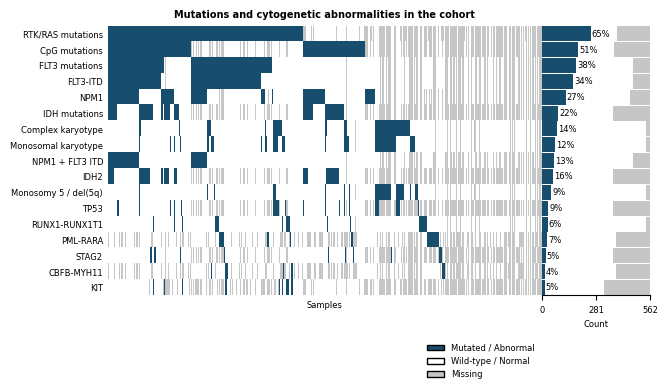

In [28]:
# get subjects with image date available in either BM or PB dataset
subjects_with_image_date = set(df_bm["subject_id"]).union(set(df_pb["subject_id"]))

# read labels (either from BM or PB) and filter to selected subjects
labels = pd.read_excel(LABEL_DATA_PATH_BM)
label_map = json.load(open(LABEL_MAP_PATH_BM, "r"))
labels = get_target_labels(labels, label_map, SELECTED_VARIABLES)
labels = labels[labels["subject_id"].isin(subjects_with_image_date)]

df = labels[SELECTED_VARIABLES].replace({1: 'POS', 0: 'NEG'})

print(df.shape)

oncoprint(
    df,
    category_colors={"POS": "#174E6D", "NEG": "#FFFFFF"},
    category_names={"POS": "Mutated / Abnormal", "NEG": "Wild-type / Normal", "NaN": "Missing"},
    order_by="POS",
    missing_label="NaN",
    missing_color="#C6C6C6",
    show_percentages="POS",
    figsize=(7, 3.5),
    order_samples=True,
    order_features=True,
    highlight_feature=None,
    highlight_color="tab:red",
    title="Mutations and cytogenetic abnormalities in the cohort",
    xlabel="Samples",
    ylabel="",
    num_xticks=3,
)


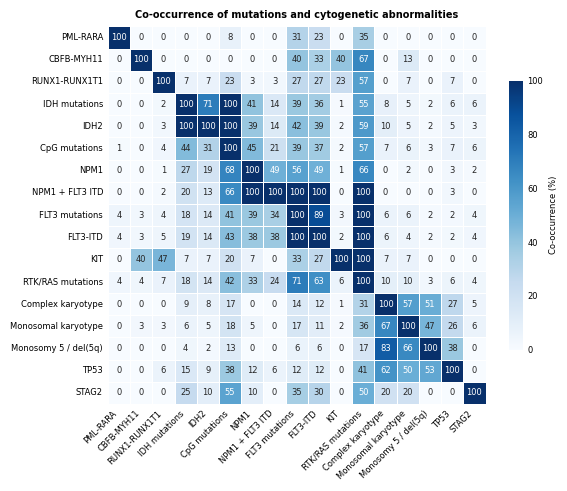

In [29]:
plot_cooccurrence(df, figsize=(6, 6), title="Co-occurrence of mutations and cytogenetic abnormalities", figure_type="main")


#### B) Cell differentials

In [30]:
def compute_cell_counts_and_proportions(df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Compute count and percentage proportion of each cell label per (database_id, album_id).

    Returns two DataFrames:
    - counts: raw counts per cell_label
    - proportions: percentage per cell_label (0-100) with '_Proportion' suffix
    """
    
    # Count occurrences per bag
    counts = (
        df.groupby(["database_id", "album_id", "cell_label"], observed=True)
          .size()
          .unstack(fill_value=0)
          .reset_index()
    )
    
    # Compute proportions (%)
    proportion_cols = [c for c in counts.columns if c not in ["database_id", "album_id"]]
    proportions = counts.copy()
    proportions[proportion_cols] = counts[proportion_cols].div(counts[proportion_cols].sum(axis=1), axis=0).mul(100)
    
    return counts, proportions


In [31]:
adata_bm_obs = load_obs_from_h5(H5_DATA_PATH_BM)

df = adata_bm_obs.copy()

df = df[["database_id", "album_id", "cell_label"]]

cell_counts, cell_proportions = compute_cell_counts_and_proportions(df)
cell_proportions.head()


cell_label,database_id,album_id,Basophils,Blasts,Eosinophils,Eosinophils_immature,Erythroblasts,Lymphocytes,Macrophages,Megakaryocytes,Metamyelocytes,Monocytes,Myelocytes,Neutrophils,Plasma_cells,Proerythroblasts,Promonocytes,Promyelocytes
0,VisionDB_2010,1207,0.000000,68.402911,0.268097,0.229797,5.898123,3.715052,0.000000,0.038300,0.574493,2.987361,5.055534,0.689391,0.421295,0.153198,6.013022,5.553428
1,VisionDB_2010,1290,0.035286,85.638673,0.000000,0.035286,0.105857,2.081863,0.000000,0.000000,0.599859,0.000000,3.069866,0.000000,0.000000,0.000000,0.035286,8.398024
2,VisionDB_2010,1431,1.655030,33.695371,0.698216,1.034394,11.249030,10.188777,0.077580,0.025860,10.033618,1.292992,11.869666,10.912852,0.930954,3.310059,1.810189,1.215412
3,VisionDB_2010,1474,0.075959,54.614508,0.797569,0.569692,9.646791,18.496012,0.113938,0.113938,1.633118,1.671098,1.671098,2.012913,4.937334,1.025446,2.354728,0.265856
4,VisionDB_2010,1493,1.796652,34.993875,0.285831,2.735811,5.063291,2.368314,0.000000,0.122499,2.817477,1.633320,8.411597,3.389138,0.122499,0.163332,13.556554,22.539812


### Bone marrow

In [32]:
if False:
    adata_bm_obs = load_obs_from_h5(H5_DATA_PATH_BM)
    df = adata_bm_obs.copy()
    df = df[["database_id", "album_id", "cell_label"]]

    cell_counts, cell_proportions = compute_cell_counts_and_proportions(df)
    variables_to_include = [v.replace('_proportion', '') for v in CELL_DIFF_VARIABLE_NAMES_BM.keys()]

    # this is the more correct way to get the cell proportions
    # However, the aggrgated data table does not have counts
    df = df_bm[cell_diff_variables_bm]
    df = df.rename(columns=lambda c: c.replace('_proportion', ''))
    variables_to_include = df.columns.to_list()

    # Plot proportions
    plot_cell_strip_box(
        df, #cell_proportions, 
        variables_to_include,
        figsize=(3.5, 3),
        value_name="Cell proportion", 
        color=BONE_MARROW_COLOR,
        xticks=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
        xlimit=(0, 100),
        xlabel="Percentage (%)",
        title="Bone marrow cell type proportions",
        figure_type="main"
    )

    # Plot counts
    # NOTE: Data should be updated becasuse cell classes have changed
    plot_cell_strip_box(
        cell_counts, 
        variables_to_include,
        figsize=(3.5, 3), 
        value_name="Cell count",
        color=BONE_MARROW_COLOR,
        xlabel="Count",
        xlimit=(0, max(cell_counts[variables_to_include].max()) * 1.1,),
        title="Bone marrow cell type counts",
        figure_type="supplementary",
    )

### Peripheral blood

In [33]:
if False:
    adata_pb_obs = load_obs_from_h5(H5_DATA_PATH_PB)
    df = adata_pb_obs.copy()
    df = df[["database_id", "album_id", "cell_label"]]

    cell_counts, cell_proportions = compute_cell_counts_and_proportions(df)
    variables_to_include = [v.replace('_proportion', '') for v in CELL_DIFF_VARIABLE_NAMES_PB.keys()]

    # this is the more correct way to get the cell proportions
    # However, the aggrgated data table does not have counts
    df = df_pb[cell_diff_variables_pb]
    df = df.rename(columns=lambda c: c.replace('_proportion', ''))
    variables_to_include = df.columns.to_list()

    # Plot proportions
    plot_cell_strip_box(
        df, #cell_proportions, 
        variables_to_include,
        figsize=(3.5, 2.5), 
        value_name="Cell proportion", 
        color=PERIPHERAL_BLOOD_COLOR,
        xticks=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
        xlimit=(0, 100),
        xlabel="Percentage (%)",
        title="Peripheral blood cell type proportions",
        figure_type="main"
    )   

    # Plot counts
    plot_cell_strip_box(
        cell_counts, 
        variables_to_include, 
        figsize=(3.5, 2.5), 
        value_name="Cell count",
        color=PERIPHERAL_BLOOD_COLOR,
        xlabel="Count",
        xlimit=(0, max(cell_counts[variables_to_include].max()) * 1.1,),
        title="Peripheral blood cell type counts",
        figure_type="supplementary",
    )


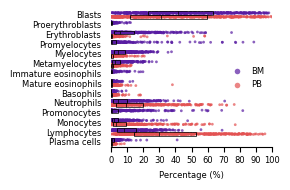

In [34]:
df_bm_props = df_bm[cell_diff_variables_bm].rename(columns=lambda c: c.replace('_proportion', ''))
df_pb_props = df_pb[cell_diff_variables_pb].rename(columns=lambda c: c.replace('_proportion', ''))

plot_combined_cell_strip_box(
    df_bm=df_bm_props,
    df_pb=df_pb_props,
    variables_bm=df_bm_props.columns.tolist(),
    variables_pb=df_pb_props.columns.tolist(),
    pb_pool_map={"Band_neutrophils": "Neutrophils", "Segmented_neutrophils": "Neutrophils"},
    value_name="Cell proportion",
    xlabel="Percentage (%)",
    xticks=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    xlimit=(0, 100),
    figsize=(3, 2),
    title="",
    figure_type="main",
)

if False:
    # This is for older version of image analysis pipelin
    plot_combined_cell_strip_box(
        df_bm=df_bm_props,
        df_pb=df_pb_props,
        variables_bm=df_bm_props.columns.tolist(),
        variables_pb=df_pb_props.columns.tolist(),
        pb_pool_map={"Band_neutrophils": "Neutrophils", "Segmented_neutrophils": "Neutrophils"},
        value_name="Cell proportion",
        xlabel="Percentage (%)",
        xticks=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
        xlimit=(0, 100),
        figsize=(7, 5),
        fontsize=16,
        title="",
        figure_type="main",
    )

# **Table 2. Model results**

In [35]:
METRICS_TO_COLLECT = [
    "roc_auc",
    "pr_auc",
    #"accuracy",
    "average_precision",
    "balanced_accuracy",
    "precision",
    "recall",
    #"specificity",
    #"npv",
    "f1_score",
]

### Bone marrow

In [36]:
bm_metrics = load_performance_metrics(MODEL_METRICS_PATH_BM, METRICS_TO_COLLECT, decimals=2)
bm_metrics = bm_metrics.sort_values(by="roc_auc_mean", ascending=False)
bm_metrics = bm_metrics[bm_metrics.variable.isin(SELECTED_VARIABLES)]

# Get variable order based on BM AUROC
results_bm_auroc = bm_metrics[["variable", "roc_auc_mean"]].copy()
results_bm_auroc = results_bm_auroc.rename(columns={"roc_auc_mean": "roc_auc_mean_bm"})
SELECTED_VARIABLES_IN_ORDER = results_bm_auroc.variable.to_list()

bm_metrics["model"] = "Bone marrow"

### Peripheral blood

In [37]:
pb_metrics = load_performance_metrics(MODEL_METRICS_PATH_PB, METRICS_TO_COLLECT, decimals=2)
pb_metrics = pb_metrics.sort_values(by="roc_auc_mean", ascending=False)
pb_metrics = pb_metrics[pb_metrics.variable.isin(SELECTED_VARIABLES)]

pb_metrics = pb_metrics.merge(results_bm_auroc, on="variable", how="left")
pb_metrics = pb_metrics.sort_values(by="roc_auc_mean_bm", ascending=False)
pb_metrics = pb_metrics.drop(columns=["roc_auc_mean_bm"])
pb_metrics["model"] = "Peripheral blood"

In [38]:
fusion_metrics = load_performance_metrics(MODEL_METRICS_PATH_FUSION, METRICS_TO_COLLECT, decimals=2)
fusion_metrics = fusion_metrics.sort_values(by="roc_auc_mean", ascending=False)
fusion_metrics = fusion_metrics[fusion_metrics.variable.isin(SELECTED_VARIABLES)]

fusion_metrics = fusion_metrics.merge(results_bm_auroc, on="variable", how="left")
fusion_metrics = fusion_metrics.sort_values(by="roc_auc_mean_bm", ascending=False)
fusion_metrics = fusion_metrics.drop(columns=["roc_auc_mean_bm"])
fusion_metrics["model"] = "Fusion"

# **Figure 3 - Model results**

In [39]:
combined_metrics = pd.concat(
    [pb_metrics, bm_metrics, fusion_metrics],
    ignore_index=True
)

In [40]:
#combined_metrics

In [41]:
if False:
    plot_split_axis_metrics(
        combined_metrics,
        metric_left="roc_auc",
        metric_right="average_precision",
        label_left="AUROC",
        label_right="Average Precision",
        x_limit_left=(0, 1.05),
        x_limit_right=(0, 1.05),
        model_col="model",
        fig_width=7,
        fig_height=6,   # fixed height now
        model_colors={
            "Bone marrow": BONE_MARROW_COLOR,
            "Peripheral blood": PERIPHERAL_BLOOD_COLOR,
            "Fusion": FUSION_COLOR,
        },  # colors for models
        model_offset=0.3,
        legend_position=(0.5, -0.01),
        legend=True,
        title="Performance of Bone marrow, Peripheral blood, and Fusion models",
    )

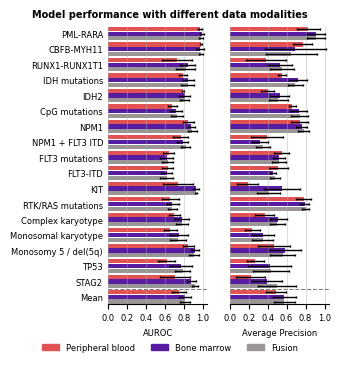

In [42]:
plot_split_axis_metrics_bar(
    combined_metrics,
    metric_left="roc_auc",
    metric_right="average_precision",
    label_left="AUROC",
    label_right="Average Precision",
    x_limit_left=(0, 1.05),
    x_limit_right=(0, 1.05),
    model_col="model",
    fig_width=3.5,
    fig_height=3.5,
    model_colors={
        "Bone marrow": BONE_MARROW_COLOR,
        "Peripheral blood": PERIPHERAL_BLOOD_COLOR,
        "Fusion": FUSION_COLOR,
    },  # colors for models
    variable_order=SELECTED_VARIABLES,
    bar_height=0.3,
    legend_position=(0.5, -0.02),
    legend=True,
    use_grid=True,
    title="Model performance with different data modalities",
    figure_type="main",
)

## **Model Attention Analysis**

Which cell types does the model attend to when predicting each genetic mutation?
Three sub-sections: Fusion model (BM + PB cells), BM-only model, PB-only model.

In [43]:
import glob
from core import utils

# Configure utils module to match notebook settings
utils.SAVE_FIGURES = SAVE_FIGURES
utils.FIGURE_SAVE_DIR = FIGURE_SAVE_DIR
utils.FIGURE_DPI = FIGURE_DPI
utils.FONTSIZE = FONTSIZE
utils.CELL_NAMES = CELL_NAMES
utils.CUSTOM_VARIABLES = CUSTOM_VARIABLES

from core.attention import (
    compute_celltype_mass_bins, plot_celltype_mass_bins,
    plot_importance_heatmaps, plot_lorenz_overlay, plot_neff_by_variable,
)

_RUN_PATH_MAP = {"BM": BM_RUN_PATH, "PB": PB_RUN_PATH, "FUSION": FUSION_RUN_PATH}

def load_attention_scores(model_name):
    run_path = _RUN_PATH_MAP[model_name]
    print(f"Loading attention scores from: {run_path}")
    files = sorted(glob.glob(f"{run_path}/fold_*/cell_attention_scores.csv"))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

def get_attention_variables(df):
    prefix = "cell_attention_score_"
    return [c[len(prefix):] for c in df.columns if c.startswith(prefix)]

In [44]:
"""Attention analysis utilities for MIL model outputs.

Configure the utils module before importing plotting functions:
    from core import utils
    utils.CELL_NAMES = CELL_NAMES
    utils.CUSTOM_VARIABLES = CUSTOM_VARIABLES
    utils.SAVE_FIGURES = SAVE_FIGURES
    ...
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from core import utils
from core.utils import save_and_show, get_readable_variable_name

MASS_THRESHOLD = 0.5

CELL_COLORS = {
    "Proerythroblasts": "maroon",
    "Erythroblasts": "lightcoral",
    "Megakaryocytes": "darkorange",
    "Blasts": "tomato",
    "Promyelocytes": "darkolivegreen",
    "Myelocytes": "yellowgreen",
    "Metamyelocytes": "springgreen",
    "Basophils": "tab:brown",
    "Neutrophils": "dodgerblue",
    "Band_neutrophils": "steelblue",
    "Segmented_neutrophils": "cornflowerblue",
    "Eosinophils_immature": "mediumpurple",
    "Eosinophils": "blueviolet",
    "Promonocytes": "navy",
    "Monocytes": "gold",
    "Macrophages": "darkkhaki",
    "Lymphocytes": "teal",
    "Plasma_cells": "turquoise",
    "Giant_platelets": "salmon",
    "Platelet_aggregations": "lightsalmon",
}


# ── Internal helpers ──────────────────────────────────────────────────────────


def lorenz_curve(attention):
    a = np.sort(attention)[::-1]
    cum_att = np.cumsum(a) / a.sum()
    cum_cells = np.arange(1, len(a) + 1) / len(a)
    return cum_cells, cum_att


def aggregate_lorenz(bags, num_points=100):
    x_grid = np.linspace(0, 1, num_points)
    curves = np.stack([np.interp(x_grid, *lorenz_curve(a)) for a in bags])
    return x_grid, curves.mean(axis=0), curves.std(axis=0)


def cells_for_mass(attention, threshold=0.5):
    """Fraction of top-attending cells needed to reach `threshold` of total attention."""
    a = np.sort(attention)[::-1]
    cum = np.cumsum(a) / a.sum()
    idx = np.searchsorted(cum, threshold)
    return (idx + 1) / len(a)


def effective_num_cells(attention, eps=1e-12):
    a = attention + eps
    return np.exp(-np.sum(a * np.log(a)))


def compute_metrics_per_bag(attention, cell_types, num_types, eps=1e-8, min_cells=5):
    N = len(attention)
    counts = np.bincount(cell_types, minlength=num_types)
    A = np.bincount(cell_types, weights=attention, minlength=num_types)
    p = counts / (N + eps)
    logR = np.log(A + eps) - np.log(p + eps)
    Hnorm = np.full(num_types, np.nan)
    for t in range(num_types):
        n_t = counts[t]
        if n_t < min_cells:
            continue
        mask = cell_types == t
        a_t = attention[mask]
        a_t = a_t / (A[t] + eps)
        H = -np.sum(a_t * np.log(a_t + eps))
        Hnorm[t] = H / np.log(n_t + eps)
    return logR, Hnorm, counts


def compute_logR_summary(df, target_variables, ct_names, subset=None):
    """Mean log(R) per cell type across bags for the given subset.

    Returns DataFrame: rows = cell types (ct_names order), columns = variables.
    subset: None = all, 'TP', 'TN', 'FP', 'FN', 'pred_pos', 'pred_neg'
    """
    _ct_map = {name: i for i, name in enumerate(ct_names)}
    _n_types = len(ct_names)
    result = {}
    for variable in target_variables:
        attn_col = f"cell_attention_score_{variable}"
        true_col = f"{variable}_true_label"
        pred_col = f"{variable}_pred_label"
        sub = df[["bag_id", "cell_label", attn_col, true_col, pred_col]].dropna(
            subset=[attn_col, true_col]
        )
        if subset == "TP":
            sub = sub[(sub[true_col] == 1) & (sub[pred_col] == 1)]
        elif subset == "TN":
            sub = sub[(sub[true_col] == 0) & (sub[pred_col] == 0)]
        elif subset == "FP":
            sub = sub[(sub[true_col] == 0) & (sub[pred_col] == 1)]
        elif subset == "FN":
            sub = sub[(sub[true_col] == 1) & (sub[pred_col] == 0)]
        elif subset == "pred_pos":
            sub = sub[sub[pred_col] == 1]
        elif subset == "pred_neg":
            sub = sub[sub[pred_col] == 0]
        logR_bags = []
        for _, bag_df in sub.groupby("bag_id"):
            attention = bag_df[attn_col].to_numpy()
            cell_types = bag_df["cell_label"].map(_ct_map).to_numpy()
            valid = ~np.isnan(cell_types)
            attention = attention[valid]
            cell_types = cell_types[valid].astype(int)
            if len(attention) == 0:
                continue
            logR, _, _ = compute_metrics_per_bag(attention, cell_types, _n_types)
            logR_bags.append(logR)
        if logR_bags:
            mean_logR = np.nanmean(np.stack(logR_bags), axis=0)
        else:
            mean_logR = np.full(_n_types, np.nan)
        result[variable] = pd.Series(mean_logR, index=ct_names)
    return pd.DataFrame(result)[target_variables]


def compute_attention_mass_summary(
    df_bm, target_variables, ct_names, subset=None, mass_threshold=MASS_THRESHOLD
):
    """For each bag, take the smallest set of top-attending cells that together
    account for `mass_threshold` fraction of total attention, then average cell-type
    proportions across bags.

    subset: None = all, 'pred_pos', 'pred_neg', 'TP', 'TN', 'FP', 'FN'
    """

    def select_mass_cells(g):
        g = g.sort_values(attn_col, ascending=False)
        cum = g[attn_col].cumsum() / g[attn_col].sum()
        cutoff = cum.index[(cum >= mass_threshold).values][0]
        return g.loc[:cutoff]

    result = {}
    for variable in target_variables:
        attn_col = f"cell_attention_score_{variable}"
        true_col = f"{variable}_true_label"
        pred_col = f"{variable}_pred_label"
        sub = df_bm[["bag_id", "cell_label", attn_col, true_col, pred_col]].dropna(
            subset=[attn_col]
        )
        if subset == "TP":
            sub = sub[(sub[true_col] == 1) & (sub[pred_col] == 1)]
        elif subset == "TN":
            sub = sub[(sub[true_col] == 0) & (sub[pred_col] == 0)]
        elif subset == "FP":
            sub = sub[(sub[true_col] == 0) & (sub[pred_col] == 1)]
        elif subset == "FN":
            sub = sub[(sub[true_col] == 1) & (sub[pred_col] == 0)]
        elif subset == "pred_pos":
            sub = sub[sub[pred_col] == 1]
        elif subset == "pred_neg":
            sub = sub[sub[pred_col] == 0]
        top_cells = (
            sub.groupby("bag_id")
            .apply(select_mass_cells, include_groups=False)
            .reset_index(level=0)
            .reset_index(drop=True)
        )
        counts = top_cells.groupby(["bag_id", "cell_label"]).size()
        totals = top_cells.groupby("bag_id").size()
        proportions = counts / totals.reindex(counts.index, level="bag_id")
        result[variable] = proportions.groupby(level="cell_label").mean()
    return pd.DataFrame(result).reindex(ct_names)[target_variables].fillna(np.nan)


# ── Top-level analysis functions ──────────────────────────────────────────────


def compute_celltype_mass_bins(df, target_variables, ct_names, n_bins=10, subset=None, cell_groups=None):
    """Assign cells to attention-mass decile bins, return mean cell-type proportions per bin.

    subset: None = all bags, 'pred_pos', 'pred_neg'
    cell_groups: dict of label -> [cell_type_names]. When provided, cell types are summed
        into groups before normalizing, so each group is one row in the output (indexed by
        label). This ensures group proportions sum to 1 and avoids seams in stacked plots.
    group_colors: dict of label -> color (used alongside cell_groups, ignored here).
    Returns: dict of variable -> DataFrame (index=ct_names or labels, columns=1..n_bins)
    """
    ct_names_set = set(ct_names)
    if cell_groups is not None:
        groups = [
            (label, [ct for ct in cts if ct in ct_names_set])
            for label, cts in cell_groups.items()
            if any(ct in ct_names_set for ct in cts)
        ]
        ct_to_row = {ct: i for i, (_, cts) in enumerate(groups) for ct in cts}
        n_rows = len(groups)
        row_names = [label for label, _ in groups]
    else:
        ct_to_row = {name: i for i, name in enumerate(ct_names)}
        n_rows = len(ct_names)
        row_names = list(ct_names)
    result = {}
    for variable in target_variables:
        attn_col = f"cell_attention_score_{variable}"
        pred_col = f"{variable}_pred_label"
        sub = df[["bag_id", "cell_label", attn_col, pred_col]].dropna(subset=[attn_col])
        if subset == "pred_pos":
            sub = sub[sub[pred_col] == 1]
        elif subset == "pred_neg":
            sub = sub[sub[pred_col] == 0]
        bag_mats = []
        for _, bag_df in sub.groupby("bag_id"):
            a = bag_df[attn_col].to_numpy()
            ct_arr = bag_df["cell_label"].to_numpy()
            order = np.argsort(a)[::-1]
            a_sorted = a[order]
            ct_sorted = ct_arr[order]
            cum_frac = np.cumsum(a_sorted) / a_sorted.sum()
            bin_ids = np.minimum((cum_frac * n_bins).astype(int), n_bins - 1)
            mat = np.zeros((n_rows, n_bins))
            for b_id, ct_name in zip(bin_ids, ct_sorted):
                if ct_name in ct_to_row:
                    mat[ct_to_row[ct_name], b_id] += 1
            col_sums = mat.sum(axis=0, keepdims=True)
            col_sums[col_sums == 0] = 1
            bag_mats.append(mat / col_sums)
        mean_mat = (
            np.stack(bag_mats).mean(axis=0)
            if bag_mats
            else np.zeros((n_rows, n_bins))
        )
        result[variable] = pd.DataFrame(
            mean_mat, index=row_names, columns=range(1, n_bins + 1)
        )
    return result


def plot_celltype_mass_bins(
    bin_data,
    target_variables,
    ct_names,
    n_cols=5,
    n_legend_cols=3,
    title="All bags",
    figsize=None,
    figure_type=None,
    cell_groups=None,
    group_colors=None,
    hspace=None,
    wspace=None,
):
    """Stacked area chart of cell-type proportions per attention-mass decile, one subplot per variable."""
    n_vars = len(target_variables)
    n_rows = (n_vars + n_cols - 1) // n_cols
    if cell_groups is not None:
        ct_to_label = {ct: label for label, cts in cell_groups.items() for ct in cts}
        ct_names = [ct for ct in ct_names if ct in ct_to_label]
        ct_names_set = set(ct_names)
        plot_groups = [
            (label, group_colors.get(label, "gray"), [ct for ct in cts if ct in ct_names_set])
            for label, cts in cell_groups.items()
            if any(ct in ct_names_set for ct in cts)
        ]
        legend_colors = [color for _, color, _ in plot_groups]
        legend_labels = [label for label, _, _ in plot_groups]
        plot_groups_reversed = list(reversed(plot_groups))
    else:
        colors = [CELL_COLORS.get(ct, "gray") for ct in ct_names]
        legend_colors = colors
        legend_labels = [get_readable_variable_name(ct) for ct in ct_names]
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=figsize or (n_cols * 2.5, n_rows * 2.8), squeeze=False,
        layout="constrained",
    )
    if hspace is not None or wspace is not None:
        fig.set_constrained_layout_pads(
            **({"hspace": hspace} if hspace is not None else {}),
            **({"wspace": wspace} if wspace is not None else {}),
        )
    for idx, variable in enumerate(target_variables):
        ax = axes[idx // n_cols][idx % n_cols]
        data = bin_data[variable]
        if cell_groups is not None:
            ax.stackplot(
                data.columns,
                [data.loc[label].to_numpy() for label, _, _ in plot_groups_reversed],
                colors=[color for _, color, _ in plot_groups_reversed],
            )
        else:
            ax.stackplot(
                data.columns, [data.loc[ct].to_numpy() for ct in ct_names], colors=colors
            )
        ax.set_title(get_readable_variable_name(variable), fontsize=utils.FONTSIZE - 1)
        ax.set_ylabel("Cells (%)", fontsize=utils.FONTSIZE - 1, labelpad=2)
        ax.set_xlabel("Attention (%)", fontsize=utils.FONTSIZE - 1)
        ax.set_xticks(range(2, data.shape[1] + 1, 2))
        ax.set_xticklabels([f"{i*10}" for i in range(2, data.shape[1] + 1, 2)])
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:.0f}"))
        ax.tick_params(labelsize=utils.FONTSIZE - 2)
        ax.set_xlim(1, 10)
        ax.set_ylim(0, 1)
        ax.spines[["top", "right"]].set_visible(False)
    for idx in range(n_vars, n_rows * n_cols):
        axes[idx // n_cols][idx % n_cols].set_visible(False)
    last_row_start = (n_rows - 1) * n_cols
    for idx in range(n_vars):
        ax = axes[idx // n_cols][idx % n_cols]
        if idx < last_row_start:
            ax.set_xlabel("")
            ax.tick_params(axis="x", labelbottom=False)
        if idx % n_cols != 0:
            ax.set_ylabel("")
            ax.tick_params(axis="y", labelleft=False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in legend_colors]
    fig.suptitle(title, fontsize=utils.FONTSIZE, fontweight="bold")
    fig.legend(
        handles,
        legend_labels,
        loc="outside lower center",
        ncol=n_legend_cols,
        fontsize=utils.FONTSIZE - 1,
        frameon=False,
    )
    save_and_show(fig, title=title, figure_type=figure_type)


def plot_heatmap(
    panels,
    cbar_label="Mean proportion",
    annotate_positive_values=False,
    cmap="Blues",
    center=None,
    figsize=None,
    figure_type=None,
):
    """Plot one heatmap figure per entry in `panels` (list of (DataFrame, title_str))."""
    vmin = min(m.min().min() for m, _ in panels) if center is not None else 0
    vmax = max(m.max().max() for m, _ in panels)
    for summary, title in panels:
        data = summary.T
        data.index = [get_readable_variable_name(i) for i in data.index]
        data.columns = [get_readable_variable_name(c) for c in data.columns]
        nrows, ncols = data.shape
        fig, ax = plt.subplots(
            1,
            1,
            figsize=figsize
            or (min(9, ncols * 0.78 + 2.6), min(7.8, nrows * 0.29 + 1.3)),
        )
        sns.heatmap(
            data,
            ax=ax,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            center=center,
            linewidths=0.4,
            linecolor="white",
            annot=False,
            square=True,
            cbar_kws={"label": cbar_label, "shrink": 0.5},
        )
        cbar = ax.collections[0].colorbar
        cbar.set_label(cbar_label, fontsize=utils.FONTSIZE - 1)
        cbar.ax.tick_params(labelsize=utils.FONTSIZE - 2)
        if annotate_positive_values:
            for row_idx, row_label in enumerate(data.index):
                for col_idx, col_label in enumerate(data.columns):
                    val = data.loc[row_label, col_label]
                    if pd.notna(val) and val > 0:
                        ax.text(
                            col_idx + 0.5,
                            row_idx + 0.5,
                            f"{val:.1f}",
                            ha="center",
                            va="center",
                            fontsize=utils.FONTSIZE - 2,
                            color="black",
                        )
        ax.set_title(
            title, pad=10, fontdict={"fontsize": utils.FONTSIZE, "fontweight": "bold"}
        )
        ax.tick_params(axis="x", rotation=45, labelsize=utils.FONTSIZE - 1, length=0)
        for label in ax.get_xticklabels():
            label.set_ha("right")
            label.set_rotation_mode("anchor")
        ax.tick_params(axis="y", rotation=0, labelsize=utils.FONTSIZE - 1, length=0)
        ax.set_xlabel("")
        plt.tight_layout()
        save_and_show(fig, title=title, figure_type=figure_type)


def plot_importance_heatmaps(
    df,
    target_variables,
    ct_names,
    figsize=None,
    figure_type=None,
    title_pred_pos="Cell type importance in \npositive predictive samples",
    title_pred_neg="Cell type importance in \nnegative predictive samples",
):
    """Log(R) heatmaps for predicted-positive and predicted-negative subsets."""
    logR_pred_pos = compute_logR_summary(
        df, target_variables, ct_names, subset="pred_pos"
    )
    logR_pred_neg = compute_logR_summary(
        df, target_variables, ct_names, subset="pred_neg"
    )
    plot_heatmap(
        panels=[
            (logR_pred_pos, title_pred_pos),
            (logR_pred_neg, title_pred_neg),
        ],
        cbar_label="Relative attention enrichment (log scale)",
        cmap="RdBu_r",
        center=0,
        annotate_positive_values=False,
        figsize=figsize,
        figure_type=figure_type,
    )


def plot_lorenz_overlay(
    df, target_variables, threshold=0.5, figsize=None, title=None, figure_type=None
):
    """Overlay Lorenz curves for all variables, sorted by concentration."""
    if title is None:
        title = (
            "Lorenz curves by variable  (sorted by cell fraction at 50% attention mass)"
        )
    var_data = []
    for variable in target_variables:
        attn_col = f"cell_attention_score_{variable}"
        sub = df[["bag_id", attn_col]].dropna(subset=[attn_col])
        bags = [g[attn_col].to_numpy() for _, g in sub.groupby("bag_id")]
        frac = np.mean([cells_for_mass(a, threshold=threshold) for a in bags])
        var_data.append((variable, bags, frac))
    var_data.sort(key=lambda x: x[2])
    colors = plt.cm.tab20(np.linspace(0, 1, len(var_data)))
    fig, ax = plt.subplots(figsize=figsize or (6, 5))
    for (variable, bags, frac), color in zip(var_data, colors):
        x, mean, _ = aggregate_lorenz(bags)
        ax.plot(
            x,
            mean,
            label=f"{get_readable_variable_name(variable)} ({frac:.2f})",
            color=color,
            linewidth=1.2,
        )
    for thr in (0.5, 0.9):
        ax.axhline(thr, color="black", linestyle="--", linewidth=0.8)
    ax.plot([0, 1], [0, 1], linestyle=":", color="gray", linewidth=0.8)
    ax.set_xlabel("Fraction of cells")
    ax.set_ylabel("Fraction of attention")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=7, ncol=2, loc="lower right")
    plt.tight_layout()
    save_and_show(fig, title=title, figure_type=figure_type)


def plot_neff_by_variable(
    df,
    target_variables,
    use_cell_fractions=False,
    figsize=None,
    title=None,
    ylabel=None,
    figure_type=None,
):
    """Cross-variable boxplot of effective number of cells (N_eff = exp entropy)."""
    if title is None:
        title = "Attention spread by variable"
    rows = []
    for variable in target_variables:
        attn_col = f"cell_attention_score_{variable}"
        true_col = f"{variable}_true_label"
        sub = df[["bag_id", attn_col, true_col]].dropna(subset=[attn_col, true_col])
        for _, bag_df in sub.groupby("bag_id"):
            a = bag_df[attn_col].to_numpy()
            neff = effective_num_cells(a)
            value = neff / len(a) if use_cell_fractions else neff
            label = "Positive" if bag_df[true_col].iloc[0] == 1 else "Negative"
            rows.append(
                {
                    "Variable": get_readable_variable_name(variable),
                    "N_eff": value,
                    "Label": label,
                }
            )
    df_plot = pd.DataFrame(rows)
    palette = {"Positive": "tab:red", "Negative": "tab:blue"}
    black_palette = {"Positive": "black", "Negative": "black"}
    hue_order = ["Positive", "Negative"]
    readable_order = [get_readable_variable_name(v) for v in target_variables]
    fig, ax = plt.subplots(figsize=figsize or (max(6, len(target_variables) * 0.6), 5))
    sns.boxplot(
        data=df_plot,
        x="Variable",
        y="N_eff",
        hue="Label",
        palette=palette,
        hue_order=hue_order,
        order=readable_order,
        dodge=True,
        width=0.5,
        showfliers=False,
        whis=1.5,
        linewidth=0.8,
        boxprops=dict(alpha=0.8),
        whiskerprops=dict(linestyle="--"),
        capprops=dict(linestyle="--"),
        medianprops=dict(color="black"),
        ax=ax,
    )
    sns.stripplot(
        data=df_plot,
        x="Variable",
        y="N_eff",
        hue="Label",
        palette=black_palette,
        hue_order=hue_order,
        order=readable_order,
        dodge=True,
        size=2,
        linewidth=0,
        alpha=0.3,
        ax=ax,
    )
    ax.set_xticks(range(len(target_variables)))
    ax.set_xticklabels(
        readable_order,
        rotation=45,
        ha="right",
        fontdict={"fontsize": utils.FONTSIZE - 1},
    )
    ax.set_xlabel("")
    ax.set_ylabel(
        ylabel
        or (
            "N effective / total cells"
            if use_cell_fractions
            else "N effective  (exp entropy)"
        ),
        fontdict={"fontsize": utils.FONTSIZE - 1},
    )
    ax.tick_params(axis="y", labelsize=utils.FONTSIZE - 1)
    ax.set_title(title, fontdict={"fontsize": utils.FONTSIZE, "fontweight": "bold"})
    ax.spines[["top", "right"]].set_visible(False)
    handles, lbls = ax.get_legend_handles_labels()
    ax.legend(
        handles[:2], lbls[:2], title="", fontsize=utils.FONTSIZE - 1, frameon=False
    )
    plt.tight_layout()
    save_and_show(fig, title=title, figure_type=figure_type)


def select_top_attention_cell_ids(
    df_attn, target_variable, threshold=0.5, modality_filter=None
):
    """Return (database_id, album_id, cell_id) rows for cells in the top-threshold
    attention mass per sample for `target_variable`.

    modality_filter: optional (column, value) tuple to pre-filter df_attn rows,
                     e.g. ('modality', 'BM') for the Fusion model.
    """
    score_col = f"cell_attention_score_{target_variable}"
    df = (
        df_attn
        if modality_filter is None
        else df_attn[df_attn[modality_filter[0]] == modality_filter[1]]
    )
    rows = []
    for (db_id, alb_id), grp in df.groupby(["database_id", "album_id"]):
        scores = grp[score_col].to_numpy(dtype=float)
        total = scores.sum()
        if total == 0:
            continue
        order = np.argsort(scores)[::-1]
        cum = np.cumsum(scores[order]) / total
        n_keep = int(np.searchsorted(cum, threshold)) + 1
        kept_ids = grp.iloc[order[:n_keep]]["cell_id"].to_numpy()
        rows.extend(
            {"database_id": str(db_id), "album_id": str(alb_id), "cell_id": int(cid)}
            for cid in kept_ids
        )
    return pd.DataFrame(rows, columns=["database_id", "album_id", "cell_id"])


### Fusion Model

In [45]:
df_attn_fusion = load_attention_scores("FUSION")
attn_vars_fusion = get_attention_variables(df_attn_fusion)

Loading attention scores from: /home/mikkop/projects/aml-mil/results/AML_V15_OPTIMIZED_PARAMETERS/multilabel/scemila/FUSION/All cells/run_2026-05-05_17-01


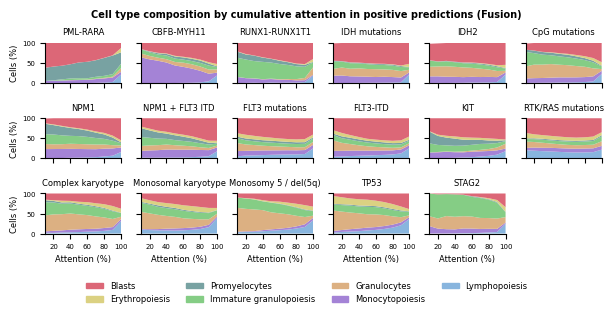

In [46]:
for subset, title in [(None, "all bags"), ("pred_pos", "positive predictions"), ("pred_neg", "negative predictions")]:
    if subset == "pred_pos":
        bin_data = compute_celltype_mass_bins(df_attn_fusion, attn_vars_fusion, CELL_LINEAGE_ORDER_BM, subset=subset, cell_groups=BM_ATTN_CELL_GROUPS)
        full_title = f"Cell type composition by cumulative attention in {title} (Fusion)"
        plot_celltype_mass_bins(
            bin_data, 
            SELECTED_VARIABLES, 
            CELL_LINEAGE_ORDER_BM, 
            title=full_title, 
            n_cols=6, 
            n_legend_cols=4, 
            figsize=(10, 5), 
            figure_type="main", 
            cell_groups=BM_ATTN_CELL_GROUPS, 
            group_colors=BM_ATTN_GROUP_COLORS,
            hspace=0.15,
        )

if False:
    plot_importance_heatmaps(
        df_attn_fusion, attn_vars_fusion, CELL_LINEAGE_ORDER_BM,
        title_pred_pos="Attention enrichment in positive predictions (Fusion)",
        title_pred_neg="Attention enrichment in negative predictions (Fusion)",
        figsize=(5, 3.5), figure_type="main")

    if True:
        plot_lorenz_overlay(df_attn_fusion, attn_vars_fusion, figsize=(7, 4),
                            title="Fusion — Lorenz curves (sorted by cell fraction at 50% attention mass)",
                            figure_type=None)
        plot_neff_by_variable(df_attn_fusion, attn_vars_fusion, use_cell_fractions=True,
                            figsize=(6, 3), title="Attention spread (Fusion)", figure_type=None)

### BM Model

In [47]:
df_attn_bm = load_attention_scores("BM")
attn_vars_bm = get_attention_variables(df_attn_bm)

Loading attention scores from: /home/mikkop/projects/aml-mil/results/AML_V15_OPTIMIZED_PARAMETERS/multilabel/scemila/BM/All cells/run_2026-05-19_11-37


In [48]:
if False:
    for subset, title in [(None, "all bags"), ("pred_pos", "predicted positive"), ("pred_neg", "predicted negative")]:
        bin_data = compute_celltype_mass_bins(df_attn_bm, attn_vars_bm, CELL_LINEAGE_ORDER_BM, subset=subset, cell_groups=BM_ATTN_CELL_GROUPS)
        plot_celltype_mass_bins(bin_data, attn_vars_bm, CELL_LINEAGE_ORDER_BM_GROUPED,
                                title=f"BM — {title}", figsize=(5.5, 4.5), figure_type=None,
                                cell_groups=BM_ATTN_CELL_GROUPS, group_colors=BM_ATTN_GROUP_COLORS)

    plot_importance_heatmaps(df_attn_bm, attn_vars_bm, CELL_LINEAGE_ORDER_BM,
                            figsize=(4, 3.5), figure_type=None)
    plot_lorenz_overlay(df_attn_bm, attn_vars_bm, figsize=(7, 4),
                        title="BM — Lorenz curves (sorted by cell fraction at 50% attention mass)",
                        figure_type=None)
    plot_neff_by_variable(df_attn_bm, attn_vars_bm, use_cell_fractions=True,
                        figsize=(6, 3), title="BM — Attention spread by variable", figure_type=None)

### PB Model

In [49]:
df_attn_pb = load_attention_scores("PB")
attn_vars_pb = get_attention_variables(df_attn_pb)

if False:

    for subset, title in [(None, "all bags"), ("pred_pos", "predicted positive"), ("pred_neg", "predicted negative")]:
        bin_data = compute_celltype_mass_bins(df_attn_pb, attn_vars_pb, CELL_LINEAGE_ORDER_PB, subset=subset)
        plot_celltype_mass_bins(bin_data, attn_vars_pb, CELL_LINEAGE_ORDER_PB,
                                title=f"PB — {title}", figsize=(5.5, 4.5), figure_type=None)

    plot_importance_heatmaps(df_attn_pb, attn_vars_pb, CELL_LINEAGE_ORDER_PB,
                            figsize=(4, 3.5), figure_type=None)
    plot_lorenz_overlay(df_attn_pb, attn_vars_pb, figsize=(7, 4),
                        title="PB — Lorenz curves (sorted by cell fraction at 50% attention mass)",
                        figure_type=None)
    plot_neff_by_variable(df_attn_pb, attn_vars_pb, use_cell_fractions=True,
                        figsize=(6, 3), title="PB — Attention spread by variable", figure_type=None)

Loading attention scores from: /home/mikkop/projects/aml-mil/results/AML_V15_OPTIMIZED_PARAMETERS/multilabel/scemila/PB/All cells/run_2026-05-19_11-40


## Attention-Filtered Cell Analysis
For mutated samples, only cells contributing to 50% of the attention mass are used when aggregating features. Wild-type samples use all cells.

In [50]:
import os
from core.cell_feature_aggregation.aggregate import aggregate_bm_dataset, aggregate_pb_dataset
from core.attention import select_top_attention_cell_ids

BM_CELL_PARQUET = "data/cell_level_features_aml_dg_de-novo-and-secondary_bm_07-04-2026.parquet"
PB_CELL_PARQUET = "data/cell_level_features_aml_dg_de-novo-and-secondary_pb_07-04-2026.parquet"

cell_df_bm = pd.read_parquet(BM_CELL_PARQUET)
cell_df_pb = pd.read_parquet(PB_CELL_PARQUET)


def build_three_group_df(
    target_variable, labels_df, df_attn, cell_df, aggregate_fn,
    threshold=0.5, filter_type="all", modality_filter=None, post_process_fn=None,
):
    """Return a sample-level DataFrame with a 'group' column: 'Wt/all', 'Mut/all', 'Mut/filtered'.

    All three groups are aggregated from the cell-level parquet.
    For 'Mut/filtered', only cells in the top-threshold attention mass are used.
    post_process_fn: optional callable applied to each group df before the group column is added,
                     e.g. lambda df: pre_process_bone_marrow_data(df)[0]
    """
    pos_ids = labels_df[labels_df[target_variable] == 1][["database_id", "album_id"]].copy()
    neg_ids = labels_df[labels_df[target_variable] == 0][["database_id", "album_id"]].copy()
    pos_ids["database_id"] = pos_ids["database_id"].astype(str)
    pos_ids["album_id"] = pos_ids["album_id"].astype(str)
    neg_ids["database_id"] = neg_ids["database_id"].astype(str)
    neg_ids["album_id"] = neg_ids["album_id"].astype(str)

    def subset(df, id_df):
        return df.merge(id_df, on=["database_id", "album_id"], how="inner")

    top_ids = select_top_attention_cell_ids(df_attn, target_variable, threshold, modality_filter)
    cell_pos_filt = cell_df.merge(top_ids, on=["database_id", "album_id", "cell_id"], how="inner")

    agg_mut_all  = aggregate_fn(subset(cell_df, pos_ids),       filter_type=filter_type).reset_index()
    agg_mut_filt = aggregate_fn(subset(cell_pos_filt, pos_ids), filter_type=filter_type).reset_index()
    agg_wt_all   = aggregate_fn(subset(cell_df, neg_ids),       filter_type=filter_type).reset_index()

    if post_process_fn is not None:
        agg_mut_all  = post_process_fn(agg_mut_all)
        agg_mut_filt = post_process_fn(agg_mut_filt)
        agg_wt_all   = post_process_fn(agg_wt_all)

    agg_mut_all["group"]  = "Mut/all"
    agg_mut_filt["group"] = "Mut/filtered"
    agg_wt_all["group"]   = "Wt/all"

    return pd.concat([agg_mut_all, agg_mut_filt, agg_wt_all], ignore_index=True)



def plot_attention_comparison(
    features, df_three,
    ylabel="", num_columns=4, fig_width=6, fig_height=4, bracket_start: float = 0.30, bracket_spacing: float = 0.08, figure_type=None,
    prediction_col=None,
    wt_label="Wt/all", mut_label="Mut/all",
    feature_labels=None,
    title=None,
    filename=None,
    hspace: float | None = None,
    wspace: float | None = None,
):
    """Multi-panel three-group boxplot: one panel per feature.
    features: list of column names (or a single string).
    Groups: Wt/all (blue), Mut/all (light red), Mut/filtered (dark red).
    Styling matches plot_significant_distributions.
    """
    from scipy.stats import ranksums

    if isinstance(features, str):
        features = [features]
    features = [f for f in features if f in df_three.columns]
    if not features:
        print("No matching columns in df_three")
        return

    n = len(features)
    n_cols = min(num_columns, n)
    n_rows = math.ceil(n / n_cols)
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height))
    axs = np.array(axs).flatten()

    order = ["Wt/all", "Mut/all", "Mut/filtered"]
    # Add a dummy NaN row for any missing group so seaborn keeps box widths uniform
    missing = [g for g in order if g not in df_three["group"].values]
    if missing:
        df_three = pd.concat([df_three, pd.DataFrame({"group": missing})], ignore_index=True)
    palette = {"Wt/all": "tab:blue", "Mut/all": "#f4a582", "Mut/filtered": "#ca0020"}
    pairs = [("Wt/all", "Mut/all"), ("Wt/all", "Mut/filtered"), ("Mut/all", "Mut/filtered")]

    # Precompute Wilcoxon p-values for each pair × feature
    pvals = {}
    for cat1, cat2 in pairs:
        g1 = df_three.loc[df_three["group"] == cat1]
        g2 = df_three.loc[df_three["group"] == cat2]
        for feat in features:
            v1 = g1[feat].dropna()
            v2 = g2[feat].dropna()
            pvals[(cat1, cat2, feat)] = ranksums(v1, v2).pvalue if (len(v1) > 1 and len(v2) > 1) else np.nan

    fontsize = FONTSIZE
    mut_filt_label = f"{mut_label}\n(top cells)"
    display_labels = [wt_label, mut_label, mut_filt_label]
    for ax, feat in zip(axs, features):
        sns.boxplot(
            data=df_three, x="group", y=feat, hue="group",
            palette=palette, gap=0.02, whis=0, showfliers=False,
            order=order, ax=ax, zorder=2,
        )
        sns.stripplot(
            data=df_three, x="group", y=feat, color=".3", size=2,
            order=order, jitter=True, ax=ax, zorder=0
        )
        # Highlight misclassifications: FP (red), FN (orange-red)
        if prediction_col is not None and prediction_col in df_three.columns:
            fp_mask = (df_three["group"] == "Wt/all") & (df_three[prediction_col] == 1)
            fn_mask = (df_three["group"].isin(["Mut/all", "Mut/filtered"])) & (df_three[prediction_col] == 0)
            for mask, color in [(fp_mask, "#d73027"), (fn_mask, "#fc8d59")]:
                if mask.any():
                    sns.stripplot(
                        data=df_three[mask], x="group", y=feat, color=color,
                        order=order, jitter=True, ax=ax, size=2.5, zorder=1,
                    )
        for line in ax.lines:
            if line.get_linestyle() == "-":
                line.set_linewidth(2)
        if ax.get_legend():
            ax.get_legend().remove()
        if prediction_col is not None and prediction_col in df_three.columns:
            ax.plot([], [], "o", color=".3", markersize=1.5, label="Correct")
            ax.plot([], [], "o", color="#d73027", markersize=2.5, label="FP")
            ax.plot([], [], "o", color="#fc8d59", markersize=2.5, label="FN")
            ax.legend(frameon=False, fontsize=fontsize - 2, loc="best")

        # P-value brackets (only for significant pairs)


        ax.tick_params(axis="x", labelsize=fontsize - 1)
        ax.set_xlabel("")
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(display_labels)
        ax.set_ylabel(ylabel, fontsize=fontsize - 2)
        ax.set_axisbelow(True)
        ax.tick_params(axis="y", labelsize=fontsize - 1)
        ax.spines[["right", "top"]].set_visible(False)
        feat_label = feature_labels.get(feat, get_readable_variable_name(feat)) if feature_labels else get_readable_variable_name(feat)
        ax.set_title(feat_label, fontsize=fontsize, fontweight="bold")

    for ax in axs[n:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=fontsize, fontweight="bold")
    plt.tight_layout()
    if hspace is not None or wspace is not None:
        plt.subplots_adjust(hspace=hspace, wspace=wspace)

    # Draw brackets after tight_layout so the axes geometry is finalised;
    # clip_on=False lets them extend below the axes box without disturbing layout
    for ax, feat in zip(axs[:n], features):
        trans = ax.get_xaxis_transform()
        j = 0
        for cat1, cat2 in pairs:
            p = pvals[(cat1, cat2, feat)]
            if not np.isnan(p) and p <= 0.05:
                x1, x2 = order.index(cat1), order.index(cat2)
                y = -(bracket_start + j * bracket_spacing)
                ax.plot([x1, x2], [y, y], lw=1, color="black",
                        transform=trans, clip_on=False)
                p_label = "***" if p < 0.001 else ("**" if p < 0.01 else "*")
                ax.text((x1 + x2) / 2, y - 0.02, p_label,
                        transform=trans, clip_on=False,
                        ha="center", va="top", fontsize=fontsize - 1)
                j += 1

    save_and_show(fig, filename, figure_type=figure_type)

def plot_attention_median_line(
    target_variable, features, df_three, cell_lineage_order,
    ylabel="", fig_width=6, fig_height=4, figure_type=None, show_iqr=False,
):
    """Line plot of per-group medians across cell types.
    Features are ordered by cell_lineage_order (e.g. CELL_LINEAGE_ORDER_BM).
    Groups: Wt/all (blue), Mut/all (light red), Mut/filtered (dark red).
    """
    if isinstance(features, str):
        features = [features]
    features = [f for f in features if f in df_three.columns]
    if not features:
        print("No matching columns in df_three")
        return

    # Order features by cell lineage order
    features = sort_features_by_lineage(features, cell_lineage_order[::-1])  # reverse lineage order for better visualization
    labels = [get_readable_variable_name(f) for f in features]

    order = ["Wt/all", "Mut/all", "Mut/filtered"]
    colors = {"Wt/all": "tab:blue", "Mut/all": "#f4a582", "Mut/filtered": "#ca0020"}

    fontsize = FONTSIZE
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    x = range(len(features))

    for group in order:
        g = df_three[df_three["group"] == group]
        medians = [g[f].median() for f in features]
        q25 = [g[f].quantile(0.25) for f in features]
        q75 = [g[f].quantile(0.75) for f in features]
        ax.plot(x, medians, marker="o", markersize=4, linewidth=1.5,
                color=colors[group], label=group)
        if show_iqr:
            ax.fill_between(x, q25, q75, color=colors[group], alpha=0.15)

    ax.set_xticks(list(x))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=fontsize - 1)
    ax.set_ylabel(ylabel, fontsize=fontsize - 1)
    ax.tick_params(axis="y", labelsize=fontsize - 1)
    ax.set_title(get_readable_variable_name(target_variable), fontsize=fontsize, fontweight="bold")
    ax.spines[["right", "top"]].set_visible(False)
    ax.legend(frameon=False, fontsize=fontsize - 1)
    plt.tight_layout()
    save_and_show(fig, title=f"{target_variable}_attn_median_line", figure_type=figure_type)


In [51]:
def plot_attention_cell_differentials(
    features: List[str],
    df_three: pd.DataFrame,
    xlabel: str = "Proportion (%)",
    fig_width: float = 4,
    fig_height: float = 4,
    figure_type: str | None = None,
    prediction_col: str | None = None,
    wt_label: str = "Neg.",
    mut_label: str = "Pos.",
    filtered_label: str = "Pos. (top cells)",
    feature_labels: dict | None = None,
    title: str = "",
    xticks: List[float] | None = None,
    xlimit: Tuple[float, float] | None = None,
) -> Tuple[plt.Figure, plt.Axes]:
    """Single horizontal strip+box plot comparing cell-type proportions across three groups.

    Cell types on y-axis, groups (Wt/all, Mut/all, Mut/filtered) dodged per row.
    Boxes filled with group colors. Dots are grey (correct), red (FP), orange (FN).
    Kruskal-Wallis significance annotated as asterisks on y-axis labels.
    """
    from scipy.stats import kruskal

    cols = [f for f in features if f in df_three.columns]

    def _display_name(col):
        return feature_labels.get(col, get_readable_variable_name(col)) if feature_labels else get_readable_variable_name(col)

    group_map = {"Wt/all": wt_label, "Mut/all": mut_label, "Mut/filtered": filtered_label}
    id_vars = ["group"] + ([prediction_col] if prediction_col else [])
    work = df_three[cols + id_vars].copy()
    work["group"] = work["group"].map(group_map)

    melted = work.melt(id_vars=id_vars, value_vars=cols, var_name="Cell type", value_name=xlabel)
    melted["Cell type"] = melted["Cell type"].map(_display_name)

    cell_type_order = [_display_name(c) for c in cols]
    hue_order = [wt_label, mut_label, filtered_label]
    palette = {wt_label: "tab:blue", mut_label: "#f4a582", filtered_label: "#ca0020"}
    grey_palette = {k: ".6" for k in palette}

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    # Dots: all grey; FP/FN overlaid in color below
    sns.stripplot(
        data=melted, y="Cell type", x=xlabel, hue="group",
        hue_order=hue_order, order=cell_type_order, dodge=True,
        palette=grey_palette, size=1.5, linewidth=0, alpha=0.7, zorder=0, ax=ax,
    )
    # Boxes: filled with group colors
    sns.boxplot(
        data=melted, y="Cell type", x=xlabel, hue="group",
        hue_order=hue_order, order=cell_type_order, dodge=True,
        palette=palette,
        linewidth=0.5, showfliers=False, whis=0, zorder=2,
        boxprops=dict(edgecolor="black"),
        whiskerprops=dict(color="black", linestyle="--"),
        capprops=dict(color="black", linestyle="--"),
        medianprops=dict(color="black"),
        ax=ax,
    )

    if prediction_col:
        fp_mask = (melted["group"] == wt_label) & (melted[prediction_col] == 1)
        fn_mask = (melted["group"].isin([mut_label, filtered_label])) & (melted[prediction_col] == 0)
        for mask, color in [(fp_mask, "#d73027"), (fn_mask, "#fc8d59")]:
            if mask.any():
                sns.stripplot(
                    data=melted[mask], y="Cell type", x=xlabel, hue="group",
                    hue_order=hue_order, order=cell_type_order, dodge=True,
                    palette={k: color for k in palette},
                    size=1.5, zorder=1, ax=ax,
                )

    # Kruskal-Wallis significance: asterisks appended to y-tick labels
    ax.figure.canvas.draw()
    ytick_labels = [t.get_text() for t in ax.get_yticklabels()]
    for i, cell_type in enumerate(cell_type_order):
        groups = [
            melted.loc[(melted["Cell type"] == cell_type) & (melted["group"] == g), xlabel].dropna()
            for g in hue_order
        ]
        groups = [g for g in groups if len(g) > 1]
        if len(groups) >= 2:
            p = kruskal(*groups).pvalue
            stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
            if stars and i < len(ytick_labels):
                ytick_labels[i] = ytick_labels[i] + " " + stars
    ax.set_yticklabels(ytick_labels)

    # Legend: group colors (box patches) + FP/FN markers
    from matplotlib.patches import Patch
    patch_handles = [Patch(facecolor=c, edgecolor="black", label=l) for l, c in palette.items()]
    line_handles = []
    if prediction_col:
        line_handles.append(ax.plot([], [], "o", color=".3", markersize=1, label="Correct")[0])
        line_handles.append(ax.plot([], [], "o", color="#d73027", markersize=1, label="FP")[0])
        line_handles.append(ax.plot([], [], "o", color="#fc8d59", markersize=1, label="FN")[0])
    ax.legend(handles=patch_handles + line_handles, frameon=False, fontsize=FONTSIZE - 1, loc="best")

    # Tighten y-axis to remove excess padding above/below the categories
    ax.set_ylim(len(cell_type_order) - 0.5, -0.5)

    ax.set_xlabel(xlabel, fontsize=FONTSIZE - 1)
    ax.set_ylabel("", fontsize=FONTSIZE - 1)
    ax.tick_params(axis="x", labelsize=FONTSIZE - 1)
    ax.tick_params(axis="y", labelsize=FONTSIZE - 1)
    ax.spines[["left", "right", "top"]].set_visible(False)
    ax.tick_params(left=False)
    if xticks is not None:
        ax.set_xticks(xticks)
    if xlimit is not None:
        ax.set_xlim(xlimit)
    ax.set_title(title or "", fontsize=FONTSIZE, fontweight="bold")

    plt.tight_layout()
    save_and_show(fig, title=title, figure_type=figure_type)


## **Analysis of cytomorphology**

#### **BM Cell differentials**

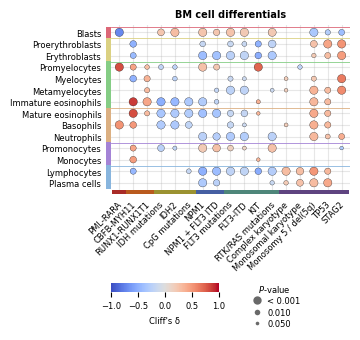

In [52]:
temp = sort_features(get_bm_cell_differential_variables(), CELL_LINEAGE_ORDER_BM, CELL_STATISTIC_ORDER)

cell_differential_stats, _ = plot_balloon_plot(
    df=df_bm,
    cat_vars={variable: get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
    cont_vars={variable: get_readable_variable_name(variable) for variable in temp}, #sort_features_by_lineage(get_bm_cell_differential_variables(), CELL_LINEAGE_ORDER_BM)
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=4.5,
    plot_width=3.7,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=22,
    cbar_height=0.02,
    title="BM cell differentials",
    ylabel=None,
    figure_type="main_bm_cell_differentials_balloon_plot",
    legend_below=True,
    ylabel_group_colors=BM_BALLOON_YLABEL_COLORS,
    xlabel_group_colors=MUTATION_COLORS,
    xlabel_color_strip_height=9,
    axis_color_strip_width=6,
    ylabel_group_separators=True,
    xlabel_label_offset=3,
)

#cell_differential_stats.head()
bm_cell_diff_stats = cell_differential_stats

In [53]:
# Usage — cell differentials:
#plot_significant_distributions("NPM1", df_bm, cell_differential_stats, ylabel="% of living cells", fig_height=6, fig_width=6)

# Usage — dysplasia (after running the dysplasia balloon plot):
# plot_significant_distributions("NPM1", df_bm, dysplasia_stats, ylabel="Dysplasia score")

# Usage — cell statistics (after running the cell statistics balloon plot):
# plot_significant_distributions("NPM1", df_bm, cell_statistic_stats, ylabel="Morphology")

In [54]:
# BM - Predicted mutations and aberrations
if False:
    cell_differential_stats, _ = plot_balloon_plot(
        df=df_bm,
        cat_vars={f"{variable}_predicted": get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
        cont_vars={variable: get_readable_variable_name(variable) for variable in sort_features_by_lineage(get_bm_cell_differential_variables(), CELL_LINEAGE_ORDER_BM)},
        max_pvalue=0.05,
        adjust_p_values=True,
        plot_height=3,
        plot_width=4,
        scale_factor=3,
        swap_axes=True,
        sort_by_pvalue=False,
        cbar_divider=8,
        title="Association of BM cell differentials with predicted genetic abnormalities",
        ylabel="Cell differentials (%)",
        figure_type="supplementary",
    )

#VARIABLE = "PML-RARA"
#cell_differential_stats[cell_differential_stats["Categorical"] == VARIABLE]


In [55]:
#plot_significant_distributions("CpG_mutations_predicted", df_bm, cell_differential_stats, ylabel="% of living cells", fig_height=2, fig_width=6)

#### **PB Cell differentials**

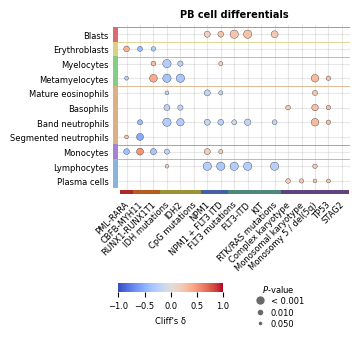

In [56]:
cell_differential_stats, _ = plot_balloon_plot(
    df=df_pb,
    cat_vars={variable: get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
    cont_vars={variable: get_readable_variable_name(variable) for variable in sort_features_by_lineage(get_pb_cell_differential_variables(), CELL_LINEAGE_ORDER_PB)},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=4.5,
    plot_width=3.7,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=16,
    cbar_height=0.02,
    title="PB cell differentials",
    ylabel=None,
    figure_type="main_pb_cell_differentials_balloon_plot",
    legend_below=True,
    ylabel_group_colors=PB_BALLOON_YLABEL_COLORS,
    xlabel_group_colors=MUTATION_COLORS,
    xlabel_color_strip_height=9,
    axis_color_strip_width=6,
    xlabel_label_offset=3,
)

#cell_differential_stats.head()
pb_cell_diff_stats = cell_differential_stats

In [57]:
# Usage — cell differentials:
#plot_significant_distributions("IDH_mutations", df_bm, cell_differential_stats, ylabel="% of living cells", fig_height=3, fig_width=5)

In [58]:
if False:
    cell_differential_stats, _ = plot_balloon_plot(
        df=df_pb,
        cat_vars={f"{variable}_predicted": get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
        cont_vars={variable: get_readable_variable_name(variable) for variable in sort_features_by_lineage(get_pb_cell_differential_variables(), CELL_LINEAGE_ORDER_PB)},
        max_pvalue=0.05,
        adjust_p_values=True,
        plot_height=2.5,
        plot_width=4,
        scale_factor=2,
        swap_axes=True,
        sort_by_pvalue=False,
        cbar_divider=7,
        title="Association of PB cell differentials with predicted genetic abnormalities",
        ylabel="Cell differentials (%)",
    )

#cell_differential_stats.head()


#### **BM Morphometry**

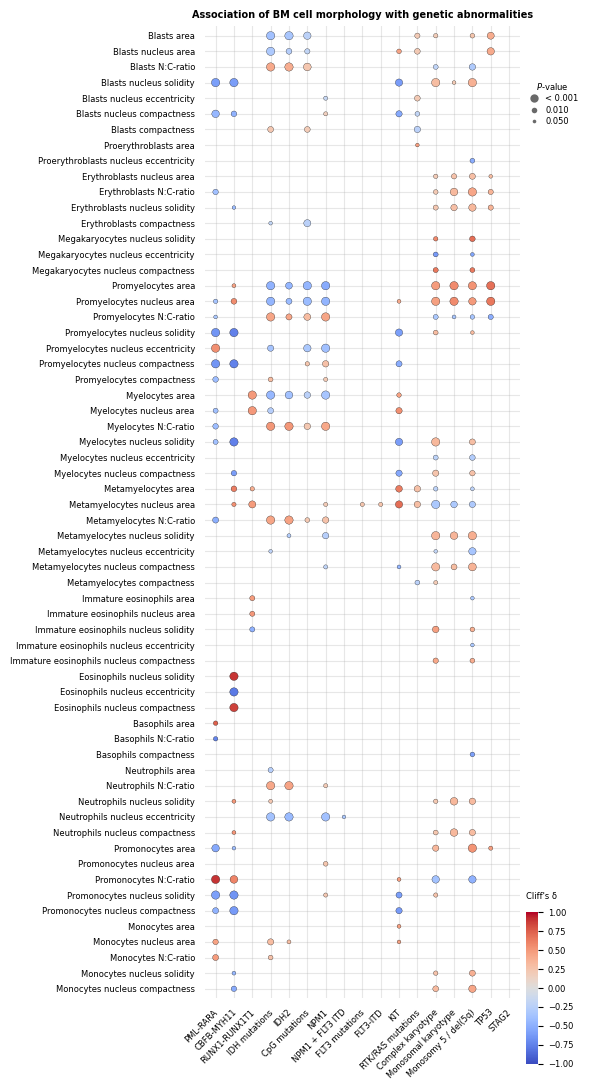

In [59]:
cell_statistic_variables_ordered = sort_features(cell_statistic_variables_bm, CELL_LINEAGE_ORDER_BM, CELL_STATISTIC_ORDER)

cell_statistic_stats, balloon_plot_data = plot_balloon_plot(
    df=df_bm,
    cat_vars={variable: get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
    cont_vars={variable: get_human_readable_cell_statistic_variable(variable) for variable in cell_statistic_variables_ordered},
    max_pvalue=0.05,
    plot_height=11,
    plot_width=6,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=80,
    title="Association of BM cell morphology with genetic abnormalities",
)
bm_cell_stat_stats = cell_statistic_stats

In [60]:
if False:
    VARIABLE = "KMT2A_rearrangement"
    CELL_TYPE = "Myelocytes"
    df = cell_statistic_stats.copy()
    df = df[df["cat_col"] == VARIABLE]
    df = df[df["Continuous"].str.contains(CELL_TYPE, case=False)]
    df

In [61]:
#temp = filter_stats(cell_statistic_stats)
#plot_significant_distributions("NPM1", df_bm, temp, ylabel="Morphology", num_columns=4, fig_height=8, fig_width=8)

In [62]:
if False:
    # Create matrix
    matrix = create_cell_statistic_summary_matrix(
        df=balloon_plot_data,
        cell_types=[get_readable_variable_name(k) for k in CELL_DIFF_VARIABLE_NAMES_BM.keys()],
        variable_order=SELECTED_VARIABLES_IN_ORDER,
        readable_variable_func=get_readable_variable_name,
        max_p_value=0.05,
    )

    # Plot heatmap
    ax = plot_cell_statistic_summary(
        matrix=matrix,
        figsize=(5, 3),
        cbar_shrink=0.8,
        vmin=0,
        vmax=7,
        title="Summary of associations of BM cell morphology\nwith genetic abnormalities\n",
    )

In [63]:
if False:
    cell_statistic_variables_ordered = sort_features(cell_statistic_variables_bm, CELL_LINEAGE_ORDER_BM, CELL_STATISTIC_ORDER)

    cell_statistic_stats, balloon_plot_data = plot_balloon_plot(
        df=df_bm,
        cat_vars={f"{variable}_predicted": get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
        cont_vars={variable: get_human_readable_cell_statistic_variable(variable) for variable in cell_statistic_variables_ordered},
        max_pvalue=0.05,
        plot_height=11,
        plot_width=4,
        scale_factor=2,
        swap_axes=True,
        sort_by_pvalue=False,
        cbar_divider=80,
        title="Association of BM cell morphology with predicted genetic abnormalities",
    )

    #cell_statistic_stats.head()


In [64]:
if False:
    matrix = create_cell_statistic_summary_matrix(
        df=balloon_plot_data,
        cell_types=[get_readable_variable_name(k) for k in CELL_DIFF_VARIABLE_NAMES_BM.keys()],
        variable_order=SELECTED_VARIABLES_IN_ORDER,
        readable_variable_func=get_readable_variable_name,
        max_p_value=0.05,
    )
    ax = plot_cell_statistic_summary(
        matrix=matrix,
        figsize=(4, 3),
        cbar_shrink=0.8,
        vmin=0,
        vmax=7,
        title="Summary of associations of BM cell morphology\n with predicted genetic abnormalities",
    )

#### **PB Morphometry**

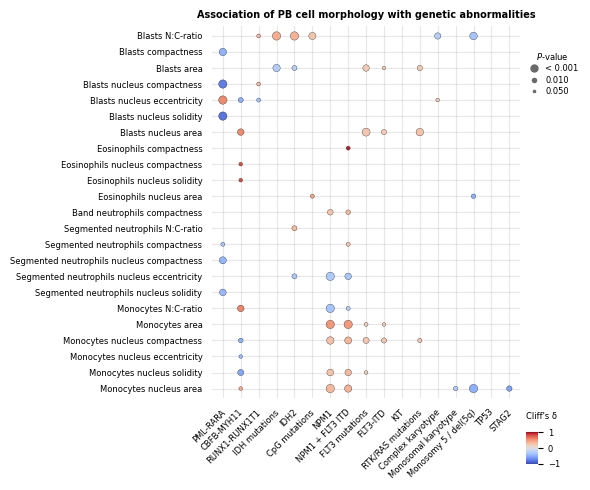

In [65]:
cell_statistic_variables_ordered = sort_features_by_lineage(cell_statistic_variables_pb, CELL_LINEAGE_ORDER_PB)

cell_statistic_stats, balloon_plot_data = plot_balloon_plot(
    df=df_pb,
    cat_vars={variable: get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
    cont_vars={variable: get_human_readable_cell_statistic_variable(variable) for variable in cell_statistic_variables_ordered},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=5,
    plot_width=6,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=80,
    title="Association of PB cell morphology with genetic abnormalities",
    xlabel_label_offset=3,
)

#cell_statistic_stats.head()
pb_cell_stat_stats = cell_statistic_stats

In [66]:
#temp = filter_stats(cell_statistic_stats, cell_type="Blasts")
#plot_significant_distributions("RTK_RAS_mutations", df_bm, temp, ylabel="Morphology", num_columns=3, fig_height=2, fig_width=6)

In [67]:
if False:
    # Create matrix
    matrix = create_cell_statistic_summary_matrix(
        df=balloon_plot_data,
        cell_types=[get_readable_variable_name(k) for k in CELL_DIFF_VARIABLE_NAMES_PB.keys()],
        variable_order=SELECTED_VARIABLES_IN_ORDER,
        readable_variable_func=get_readable_variable_name,
        max_p_value=0.05,
    )

    # Plot heatmap
    ax = plot_cell_statistic_summary(
        matrix=matrix,
        figsize=(4, 2),
        cbar_shrink=0.8,
        vmin=0,
        vmax=7,
        title="Summary of associations of PB cell morphology\n with genetic abnormalities",
    )

In [68]:
if False:
    cell_statistic_variables_ordered = sort_features_by_lineage(cell_statistic_variables_pb, CELL_LINEAGE_ORDER_PB)

    cell_statistic_stats, balloon_plot_data = plot_balloon_plot(
        df=df_pb,
        cat_vars={f"{variable}_predicted": get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
        cont_vars={variable: get_human_readable_cell_statistic_variable(variable) for variable in cell_statistic_variables_ordered},
        max_pvalue=0.05,
        adjust_p_values=True,
        plot_height=11,
        plot_width=4,
        scale_factor=2,
        swap_axes=True,
        sort_by_pvalue=False,
        cbar_divider=80,
        title="Association of PB cell morphology with predicted genetic abnormalities",
    )

    #cell_statistic_stats.head()


In [69]:
if False:
    # Create matrix
    matrix = create_cell_statistic_summary_matrix(
        df=balloon_plot_data,
        cell_types=[get_readable_variable_name(k) for k in CELL_DIFF_VARIABLE_NAMES_PB.keys()],
        variable_order=SELECTED_VARIABLES_IN_ORDER,
        readable_variable_func=get_readable_variable_name,
        max_p_value=0.05,
    )

    # Plot heatmap
    ax = plot_cell_statistic_summary(
        matrix=matrix,
        figsize=(4, 2),
        cbar_shrink=0.8,
        vmin=0,
        vmax=7,
        title="Summary of associations of PB cell morphology\n with predicted genetic abnormalities",
    )

#### **BM Dysplasia**

In [70]:
SELECTED_BM_DYSPLASIA_VARIABLES = [
    # MYELOID PRECURSORS
    ## Overall dysplasia:
    #'Myeloid_precursors_overall_dysplasia_proportion',
    ## Morphological dysplasia:

    'Myeloid_precursors_hypergranulated_proportion',
    'Myeloid_precursors_bilobed_proportion',
    'Myeloid_precursors_auer_proportion',

    ## Hypergranularity:
    
    #'Blasts_hypergranulated_proportion',
    #'Promyelocytes_hypergranulated_proportion',
    #'Myelocytes_hypergranulated_proportion',

    ## Bilobed nuclei:
    
    #'Blasts_bilobed_proportion',
    #'Promyelocytes_bilobed_proportion',

    ## Auer rods:
    
    #'Blasts_auer_proportion',
    #'Promyelocytes_auer_proportion',

    ## Vacuolization:
    ## Cell type specific dysplasia:
    ### Blasts
    ### Promyelocytes
    ### Myelocytes
    #'Myelocytes_bilobed_proportion',
    #'Myelocytes_auer_proportion',
    
    # ERYTHROBLASTS:
    ## Overall dysplasia:
    #'Erythroblasts-overall_dysplasia_proportion',
    ## Morphological dysplasia:
    'Erythroblasts_asynchrony_proportion',
    'Erythroblasts_dysmorphic_proportion',
    'Erythroblasts_multinucleated_proportion',

    # MEGAKARYOCYTES:
    ## Overall dysplasia (NOTE: Missing)
    ## Morphological dysplasia:
    'Megakaryocytes_multinucleated_proportion',
    'Megakaryocytes_hypolobated_proportion',
    'Megakaryocytes-vacuolated_proportion',

    # VACUOLIZATION:
    'Blasts-vacuolated_proportion',
    'Erythroblasts-vacuolated_proportion',
    'Promyelocytes-vacuolated_proportion',
    'Myelocytes-vacuolated_proportion',
    ## Mature granulocytes:
    'Basophils-vacuolated_proportion',
    'Neutrophils-vacuolated_proportion',
    'Eosinophils-vacuolated_proportion',

    # Lymphocytes:
    'Lymphocytes-vacuolated_proportion',

    # Plasma cells:
    'Plasma_cells-vacuolated_proportion'

]

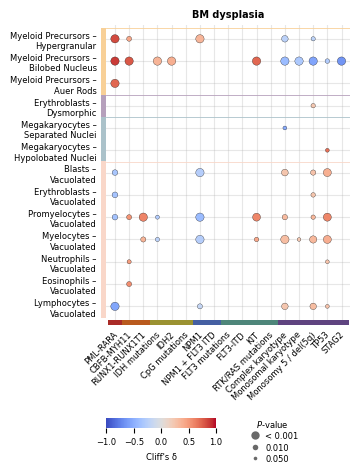

In [71]:
dysplasia_stats, ballon_plot_data = plot_balloon_plot(
    df=df_bm,
    cat_vars={variable: get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
    cont_vars={variable: get_human_readable_bm_dysplasia_variable(variable) for variable in SELECTED_BM_DYSPLASIA_VARIABLES[::-1]},
    max_pvalue=0.05,
    plot_height=6.5, #9.5
    plot_width=3.7,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=16,
    cbar_height=0.015, #0.01
    filter_empty_features=True,
    title="BM dysplasia",
    ylabel=None,
    figure_type="main_bm_dysplasia_balloon_plot",
    legend_below=True,
    xlabel_group_colors=MUTATION_COLORS,
    ylabel_group_colors={
        "#f8d097": ['Myeloid_precursors_hypergranulated_proportion', 'Myeloid_precursors_bilobed_proportion', 'Myeloid_precursors_auer_proportion'],
        "#b6a0bc": ['Erythroblasts_asynchrony_proportion', 'Erythroblasts_dysmorphic_proportion', 'Erythroblasts_multinucleated_proportion'],
        "#abc2ca": ['Megakaryocytes_multinucleated_proportion', 'Megakaryocytes_hypolobated_proportion', 'Megakaryocytes-vacuolated_proportion'],
        "#f9d7c9": ['Blasts-vacuolated_proportion', 'Erythroblasts-vacuolated_proportion', 'Promyelocytes-vacuolated_proportion', 'Myelocytes-vacuolated_proportion', 'Basophils-vacuolated_proportion', 'Neutrophils-vacuolated_proportion', 'Eosinophils-vacuolated_proportion', 'Lymphocytes-vacuolated_proportion', 'Plasma_cells-vacuolated_proportion'],
    },
    xlabel_color_strip_height=9,
    axis_color_strip_width=6,
    ylabel_group_separators=True,
    xlabel_label_offset=3,
)
#dysplasia_stats.head()
bm_dysplasia_stats = dysplasia_stats

In [72]:
# Usage — dysplasia (after running the dysplasia balloon plot):
#plot_significant_distributions("KIT", df_bm, dysplasia_stats, ylabel="Cell proportion (%)", fig_width=6, fig_height=4)

In [73]:
if False:
    rows = {
        "PML-RARA": [
            "Myeloid Precursors-Auer Rods",
            "Myeloid Precursors-Hypergranular", 
            "Promyelocytes-Hypergranular", 
            "Myelocytes-Hypergranular", 
            "Blasts-Bilobed Nucleus",
        ],
        "CBFB-MYH11": ["Myeloid Precursors-Hypergranular"],
        "NPM1": ["Blasts-Vacuolated", "Promyelocytes-Vacuolated", "Myelocytes-Vacuolated"],
    }

    for variable in rows.keys():
        print(f"Variable: {variable}")
        # show only rows that are in `rows`
        df = dysplasia_stats.copy()
        df = df[df["Categorical"] == variable]  # Filter by categorical variable
        df = df[df["Continuous"].isin(rows[variable])]  # Filter by continuous variables
        display(df)


In [74]:
if False:
    dysplasia_stats, _ = plot_balloon_plot(
        df=df_bm,
        cat_vars={f"{variable}_predicted": get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
        cont_vars={variable: get_human_readable_bm_dysplasia_variable(variable) for variable in SELECTED_BM_DYSPLASIA_VARIABLES[::-1]},
        max_pvalue=0.05,
        plot_height=2.5,
        plot_width=4,
        scale_factor=3,
        swap_axes=True,
        sort_by_pvalue=False,
        filter_empty_features=True,
        cbar_divider=30,
        title="Association of BM dysplasia with \n predicted genetic abnormalities",
        ylabel="Cell differentials (%)",
    )


#### **PB Dysplasia**

In [75]:
SELECTED_PB_DYSPLASIA_VARIABLES = [

    # APL / MYELOID PRECURSORS (hypergranulation):
    'APL-apl_hypergranulated_proportion',
    'Blasts-apl_hypergranulated_proportion',
    'Myelocytes-apl_hypergranulated_proportion',

    # NEUTROPHILS (combined band + segmented):
    ## Granularity:
    'Neutrophils-neut_gran_normal_proportion',
    'Neutrophils-neut_gran_hypo_proportion',
    'Neutrophils-neut_gran_hyper_proportion',

    # BAND NEUTROPHILS:
    ## Granularity:
    #'Band_neutrophils-neut_gran_normal_proportion',
    #'Band_neutrophils-neut_gran_hypo_proportion',
    #'Band_neutrophils-neut_gran_hyper_proportion',

    # SEGMENTED NEUTROPHILS:
    ## Granularity:
    #'Segmented_neutrophils-neut_gran_normal_proportion',
    #'Segmented_neutrophils-neut_gran_hypo_proportion',
    #'Segmented_neutrophils-neut_gran_hyper_proportion',

]

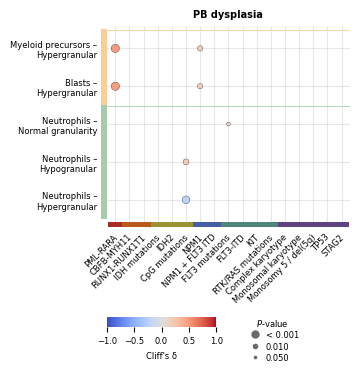

In [76]:
dysplasia_stats, _ = plot_balloon_plot(
    df=df_pb,
    cat_vars={variable: get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
    cont_vars={variable: get_human_readable_pb_dysplasia_variable(variable) for variable in SELECTED_PB_DYSPLASIA_VARIABLES[::-1]},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=5,
    plot_width=3.7,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=16,
    cbar_height=0.02,
    filter_empty_features=True,
    title="PB dysplasia",
    ylabel=None,
    figure_type="main_pb_dysplasia_balloon_plot",
    legend_below=True,
    #group_separators=[('Myelocytes-apl_hypergranulated_proportion', 'Neutrophils-neut_gran_normal_proportion')],
    xlabel_group_colors=MUTATION_COLORS,
    ylabel_group_colors={
        "#f8d097": ['APL-apl_hypergranulated_proportion', 'Blasts-apl_hypergranulated_proportion', 'Myelocytes-apl_hypergranulated_proportion'],
        "#a7cbab": ['Neutrophils-neut_gran_normal_proportion', 'Neutrophils-neut_gran_hypo_proportion', 'Neutrophils-neut_gran_hyper_proportion'],
    },
    xlabel_color_strip_height=9,
    axis_color_strip_width=6,
    xlabel_label_offset=3,
)
pb_dysplasia_stats = dysplasia_stats

In [77]:
# Usage — dysplasia (after running the dysplasia balloon plot):
# plot_significant_distributions("KMT2A_rearrangement", df_pb, dysplasia_stats, ylabel="Cell proportion (%)", fig_width=5, fig_height=3)

In [78]:
if False:
    dysplasia_stats = plot_balloon_plot(
        df=df_pb,
        cat_vars={f"{variable}_predicted": get_readable_variable_name(variable) for variable in SELECTED_VARIABLES},
        cont_vars={variable: get_human_readable_pb_dysplasia_variable(variable) for variable in SELECTED_PB_DYSPLASIA_VARIABLES},
        max_pvalue=0.05,
        adjust_p_values=True,
        plot_height=3,
        plot_width=4,
        scale_factor=3,
        swap_axes=True,
        sort_by_pvalue=False,
        cbar_divider=8,
        title="Association of PB dysplasia \n with predicted genetic abnormalities",
        ylabel="Cell differential (%)",
    )


### **UMAP of morphology features**

In [79]:
FEATURE_STATS = pd.concat([
    bm_cell_diff_stats.assign(modality="BM", feature_type="cell_differential"),
    bm_dysplasia_stats.assign(modality="BM", feature_type="dysplasia"),
    bm_cell_stat_stats.assign(modality="BM", feature_type="cell_statistic"),
    pb_cell_diff_stats.assign(modality="PB", feature_type="cell_differential"),
    pb_dysplasia_stats.assign(modality="PB", feature_type="dysplasia"),
    pb_cell_stat_stats.assign(modality="PB", feature_type="cell_statistic"),
], ignore_index=True)


def get_significant_features(target_variable, modality=None, feature_type=None):
    """Return FEATURE_STATS rows for a mutation variable, optionally filtered.

    modality: "BM" or "PB" (None = both)
    feature_type: "cell_differential", "dysplasia", "cell_statistic" (None = all)
    """
    mask = FEATURE_STATS["cat_col"] == target_variable
    if modality is not None:
        mask &= FEATURE_STATS["modality"] == modality
    if feature_type is not None:
        mask &= FEATURE_STATS["feature_type"] == feature_type
    return FEATURE_STATS[mask][["modality", "feature_type", "cont_col", "p-value", "Log10_FC"]]

In [80]:
import umap
from adjustText import adjust_text
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


def compute_umap_embedding(df, feature_cols, random_state=42):
    X = df[feature_cols].values
    X = SimpleImputer(strategy="median").fit_transform(X)
    X = StandardScaler().fit_transform(X)
    reducer = umap.UMAP(n_components=2, random_state=random_state)
    return reducer.fit_transform(X)


def compute_pca_embedding(df, feature_cols):
    X = df[feature_cols].values
    X = SimpleImputer(strategy="median").fit_transform(X)
    X = StandardScaler().fit_transform(X)
    return PCA(n_components=2).fit_transform(X)


def plot_umap_mutation_centroids(df, embedding, mutation_vars, title, ax,
                                  palette=None, labels=None, colors=None,
                                  legend_groups=None, show_samples=True, 
                                  fontsize=FONTSIZE, marker_size=40):
    umap1, umap2 = embedding[:, 0], embedding[:, 1]
    if show_samples:
        ax.scatter(umap1, umap2, c="lightgray", s=marker_size*0.15, alpha=0.6, linewidths=0, rasterized=True)
    if palette is None:
        palette = plt.cm.tab20.colors
    if labels is None:
        labels = {}
    if colors is None:
        colors = {}
    texts = []
    for i, var in enumerate(mutation_vars):
        if var not in df.columns:
            continue
        mask = df[var].fillna(0).astype(bool)
        if mask.sum() == 0:
            continue
        cx = umap1[mask].mean()
        cy = umap2[mask].mean()
        color = colors.get(var, palette[i % len(palette)])
        label = labels.get(var, get_readable_variable_name(var))
        ax.scatter(cx, cy, s=marker_size, color=color, zorder=5, edgecolors="black", linewidths=0.4)
        texts.append(
            ax.text(cx, cy, label, fontsize=fontsize - 2,
                    color=color, fontweight="bold")
        )
    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(arrowstyle="-", color="black", lw=0.5),
        expand=(1.5, 1.5),
        force_text=(1.5, 1.5),
        #force_points=(0.5, 1.0),
    )
    if legend_groups:
        handles = [
            plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=color,
                       markeredgecolor="black", markeredgewidth=0.4,
                       markersize=marker_size*0.15, label=name)
            for name, color in legend_groups.items()
        ]
        ax.legend(handles=handles, fontsize=fontsize -2, frameon=False,
                  loc="lower center", borderaxespad=0, ncol=4)
    ax.set_xlim(umap1.min(), umap1.max())
    ax.set_ylim(umap2.min(), umap2.max())
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title, fontsize=fontsize, fontweight="bold")
    ax.set_axis_off()

/home/mikkop/projects/mut-pred-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [81]:
# Custom display labels for UMAP/PCA centroid plots.
# Any variable not listed here falls back to get_readable_variable_name().
CENTROID_LABELS = {
    "PML-RARA":                       "PML-RARA",
    "CBFB-MYH11":                     "CBFB-MYH11",
    "monosomy5_del_5q":               "Monosomy 5 /\ndel(5q)",
    "NPM1":                           "NPM1",
    "STAG2":                          "STAG2",
    "KIT":                            "KIT",
    "IDH_mutations":                  "IDH1/2",
    "IDH2":                           "IDH2",
    "RUNX1-RUNX1T1_OR_t_8_21":        "RUNX1-RUNX1T1",
    "NPM1_AND_FLT3_ITD":              "NPM1 & FLT3-ITD",
    "TP53":                           "TP53",
    "complex_karyotype":              "Complex karyotype",
    "monosomal_karyotype":            "Monosomal karyotype",
    "RTK_RAS_mutations":              "RTK/RAS",
    "CpG_mutations":                  "CpG",
    "FLT3_mutations":                 "FLT3-ITD/TKD",
    "FLT3_ITD":                       "FLT3-ITD",
    "KMT2A_rearrangement":            "KMT2A",
}

In [82]:
# Derived from MUTATION_GROUPS / MUTATION_GROUP_COLORS (defined in the constants cell)
CENTROID_COLORS = {ct: MUTATION_GROUP_COLORS[label] for label, cts in MUTATION_GROUPS.items() for ct in cts}
MUTATION_GROUP_COLORS = MUTATION_GROUP_COLORS


BM: 89 significant features selected out of 159


/home/mikkop/projects/mut-pred-analysis/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


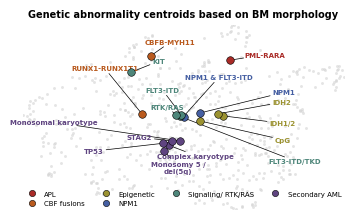

In [83]:
bm_sig_cols = (
    FEATURE_STATS[
        (FEATURE_STATS["modality"] == "BM") & (FEATURE_STATS["p-value"] < 0.05)
    ]["cont_col"].unique().tolist()
)
all_bm_cols = cell_diff_variables_bm + cell_statistic_variables_bm + cell_dysplasia_variables_bm
bm_feature_cols = [f for f in all_bm_cols if f in bm_sig_cols]
print(f"BM: {len(bm_feature_cols)} significant features selected out of {len(all_bm_cols)}")

bm_embedding = compute_umap_embedding(df_bm, bm_feature_cols)

fig, ax = plt.subplots(figsize=(3.8, 2.3))
plot_umap_mutation_centroids(
    df_bm, bm_embedding, SELECTED_VARIABLES,
    labels=CENTROID_LABELS,
    colors=CENTROID_COLORS,
    legend_groups=MUTATION_GROUP_COLORS,
    title="Genetic abnormality centroids based on BM morphology", ax=ax,
    marker_size=30,
    fontsize=FONTSIZE
)
fig.tight_layout()
save_and_show(fig, "Figure_5_BM_UMAP_mutation_centroids", figure_type="main")

PB: 39 significant features selected out of 86


/home/mikkop/projects/mut-pred-analysis/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


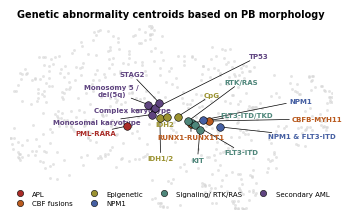

In [84]:
pb_sig_cols = (
    FEATURE_STATS[
        (FEATURE_STATS["modality"] == "PB") & (FEATURE_STATS["p-value"] < 0.05)
    ]["cont_col"].unique().tolist()
)
all_pb_cols = cell_diff_variables_pb + cell_statistic_variables_pb + cell_dysplasia_variables_pb
pb_feature_cols = [f for f in all_pb_cols if f in pb_sig_cols]
print(f"PB: {len(pb_feature_cols)} significant features selected out of {len(all_pb_cols)}")

pb_embedding = compute_umap_embedding(df_pb, pb_feature_cols)

fig, ax = plt.subplots(figsize=(3.8, 2.3))
plot_umap_mutation_centroids(
    df_pb, pb_embedding, SELECTED_VARIABLES,
    labels=CENTROID_LABELS,
    colors=CENTROID_COLORS,
    legend_groups=MUTATION_GROUP_COLORS,
    title="Genetic abnormality centroids based on PB morphology", ax=ax,
    marker_size=30,
    fontsize=FONTSIZE
)
fig.tight_layout()
save_and_show(fig, "Figure_5_PB_UMAP_mutation_centroids", figure_type="main")

# **Model explainaility**

### **PML-RARA**

In [85]:
df3_bm_pml_rara = build_three_group_df("PML-RARA", df_bm, df_attn_bm, cell_df_bm, aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_pml_rara = df3_bm_pml_rara.merge(
    df_bm[["database_id", "album_id", "PML-RARA_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_pml_rara = build_three_group_df("PML-RARA", df_pb, df_attn_pb, cell_df_pb, aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_pml_rara = df3_pb_pml_rara.merge(
    df_pb[["database_id", "album_id", "PML-RARA_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **PML-RARA: Cell differentials**

In [86]:
get_significant_features("PML-RARA", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
0,BM,cell_differential,Basophils_proportion,0.001,0.528
1,BM,cell_differential,Promyelocytes_proportion,0.001,0.820
2,BM,cell_differential,Blasts_proportion,0.001,-0.717


In [87]:
get_significant_features("PML-RARA", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
407,PB,cell_differential,Monocytes_proportion,0.008,-0.386
408,PB,cell_differential,Segmented_neutrophils_proportion,0.043,0.292
409,PB,cell_differential,Metamyelocytes_proportion,0.043,-0.284
410,PB,cell_differential,Erythroblasts_proportion,0.008,0.372


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


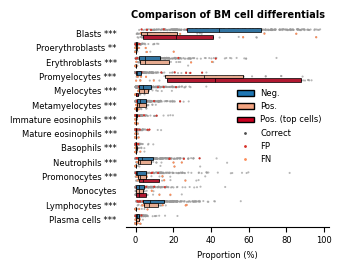

/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


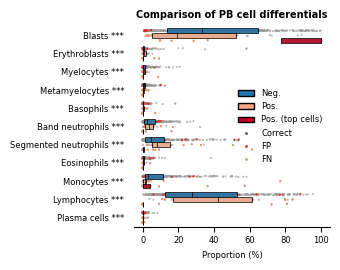

In [88]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_pml_rara,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="PML-RARA_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_PML_RARA",
    title="Comparison of BM cell differentials",
)

plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_pml_rara,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="PML-RARA_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_PML_RARA",
    title="Comparison of PB cell differentials",
)

#### **PML-RARA: BM Dysplasia**

In [89]:
get_significant_features("PML-RARA", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
126,BM,dysplasia,Lymphocytes-vacuolated_proportion,0.001,-0.555
127,BM,dysplasia,Promyelocytes-vacuolated_proportion,0.009,-0.370
128,BM,dysplasia,Erythroblasts-vacuolated_proportion,0.008,-0.359
129,BM,dysplasia,Blasts-vacuolated_proportion,0.009,-0.341
130,BM,dysplasia,Myeloid_precursors_auer_proportion,0.001,0.726
131,BM,dysplasia,Myeloid_precursors_bilobed_proportion,0.001,0.879
132,BM,dysplasia,Myeloid_precursors_hypergranulated_proportion,0.001,0.826


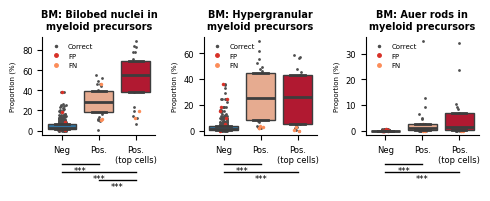

In [90]:
plot_attention_comparison(
    ["Myeloid_precursors_bilobed_proportion", "Myeloid_precursors_hypergranulated_proportion", "Myeloid_precursors_auer_proportion"],
    df3_bm_pml_rara,
    ylabel="Proportion (%)",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=5,
    fig_height=2,
    num_columns=3,
    prediction_col="PML-RARA_predicted",
    feature_labels={
        "Myeloid_precursors_bilobed_proportion": "BM: Bilobed nuclei in\nmyeloid precursors",
        "Myeloid_precursors_hypergranulated_proportion": "BM: Hypergranular\nmyeloid precursors",
        "Myeloid_precursors_auer_proportion": "BM: Auer rods in\nmyeloid precursors",
    },
)

#### **PML-RARA: PB Dysplasia**

In [91]:
get_significant_features("PML-RARA", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
463,PB,dysplasia,Blasts-apl_hypergranulated_proportion,0.001,0.474
464,PB,dysplasia,APL-apl_hypergranulated_proportion,0.001,0.483


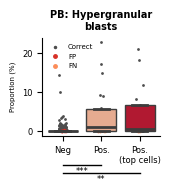

In [92]:
plot_attention_comparison(
    ["Blasts-apl_hypergranulated_proportion"], 
    df3_pb_pml_rara,
    ylabel="Proportion (%)",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.8,
    fig_height=2,
    prediction_col="PML-RARA_predicted",
    feature_labels={
        "Blasts-apl_hypergranulated_proportion": "PB: Hypergranular\nblasts",
    },
)

#### **PML-RARA: BM Morphometry**

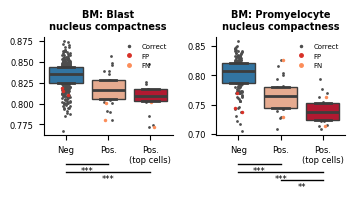

In [93]:
morphometry = get_significant_features("PML-RARA", modality="BM", feature_type="cell_statistic")
features = filter_stats(morphometry).cont_col.to_list()

if False:
    display(morphometry)
    plot_attention_comparison(
        features, 
        df3_bm_pml_rara,
        ylabel="",
        wt_label="Neg", 
        mut_label="Pos.",
        fig_width=12,
        fig_height=10,
        num_columns=5,
        prediction_col="PML-RARA_predicted",
    )

plot_attention_comparison(
    [
        "Blasts_nucleus_compactness_median",
        "Promyelocytes_nucleus_compactness_median",
    ], 
    df3_bm_pml_rara,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=3.6,
    fig_height=2,
    num_columns=4,
    prediction_col="PML-RARA_predicted",
    feature_labels={
        "Blasts_nucleus_compactness_median": "BM: Blast\nnucleus compactness",
        "Promyelocytes_nucleus_compactness_median": "BM: Promyelocyte\nnucleus compactness",
    },
)

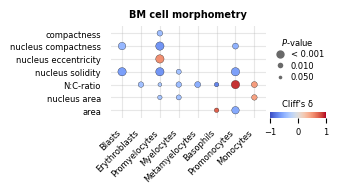

In [94]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "PML-RARA",
    modality="BM",
    plot_width=2, plot_height=1.2,
    figure_type="supplementary_PML_RARA",
    title="BM cell morphometry",   
)


#### **PML-RARA: PB Dysplasia**

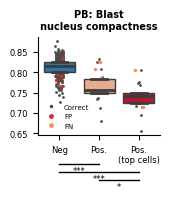

In [95]:
morphometry = get_significant_features("PML-RARA", modality="PB", feature_type="cell_statistic")
features = morphometry.cont_col.to_list()

if False:
    display(morphometry)
    plot_attention_comparison(
        features, 
        df3_pb_pml_rara,
        ylabel="Proportion (%)",
        wt_label="Neg", 
        mut_label="Pos.",
        fig_width=8,
        fig_height=6,
        num_columns=4,
        prediction_col="PML-RARA_predicted",
    )

plot_attention_comparison(
    ["Blasts_nucleus_compactness_median"], 
    df3_pb_pml_rara,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.8,
    fig_height=2,
    num_columns=2,
    prediction_col="PML-RARA_predicted",
    feature_labels={
        "Blasts_nucleus_compactness_median": "PB: Blast\nnucleus compactness",
    },
)

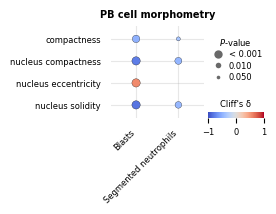

In [96]:
if True:
    plot_mutation_morphometry_balloon(
        pb_cell_stat_stats, "PML-RARA",
        modality="PB",
        plot_width=1.2, plot_height=1.2,
        figure_type="supplementary_PML_RARA",
        title="PB cell morphometry",
    )


### **CBFB-MYH11**

In [97]:
df3_bm_cbf_myh11 = build_three_group_df("CBFB-MYH11", df_bm, df_attn_bm, cell_df_bm, aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_cbf_myh11 = df3_bm_cbf_myh11.merge(
    df_bm[["database_id", "album_id", "CBFB-MYH11_predicted"]],
    on=["database_id", "album_id"], how="left"
)


df3_pb_cbf_myh11 = build_three_group_df("CBFB-MYH11", df_pb, df_attn_pb, cell_df_pb, aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_cbf_myh11 = df3_pb_cbf_myh11.merge(
    df_pb[["database_id", "album_id", "CBFB-MYH11_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **CBFB-MYH11: Cell differentials**

In [98]:
get_significant_features("CBFB-MYH11", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
3,BM,cell_differential,Lymphocytes_proportion,0.006,-0.444
4,BM,cell_differential,Monocytes_proportion,0.004,0.480
5,BM,cell_differential,Promonocytes_proportion,0.006,0.437
6,BM,cell_differential,Basophils_proportion,0.004,0.504
7,BM,cell_differential,Eosinophils_proportion,0.001,0.814
8,BM,cell_differential,Eosinophils_immature_proportion,0.001,0.881
9,BM,cell_differential,Myelocytes_proportion,0.004,-0.484
10,BM,cell_differential,Promyelocytes_proportion,0.006,0.452
11,BM,cell_differential,Erythroblasts_proportion,0.007,-0.429
12,BM,cell_differential,Proerythroblasts_proportion,0.004,-0.484


In [99]:
get_significant_features("CBFB-MYH11", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
411,PB,cell_differential,Monocytes_proportion,0.003,0.529
412,PB,cell_differential,Segmented_neutrophils_proportion,0.003,-0.525
413,PB,cell_differential,Band_neutrophils_proportion,0.015,-0.422
414,PB,cell_differential,Erythroblasts_proportion,0.015,-0.427


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


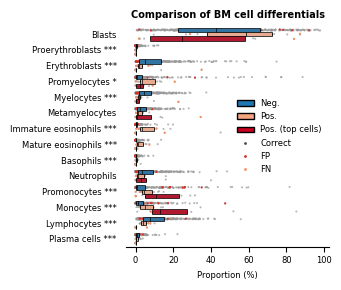

/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


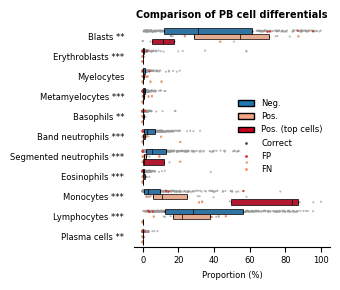

In [100]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_cbf_myh11,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=3,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_CBFB_MYH11",
    title="Comparison of BM cell differentials",
)

plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_cbf_myh11,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=3,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_CBFB_MYH11",
    title="Comparison of PB cell differentials",
)

#### **CBFB-MYH11: BM Dysplasia**

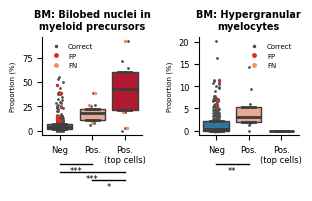

In [101]:
results = get_significant_features("CBFB-MYH11", modality="BM", feature_type="dysplasia")
features = filter_stats(results).cont_col.to_list()

if False:
    display(results)
    plot_attention_comparison(
        features, 
        df3_bm_cbf_myh11,
        ylabel="",
        wt_label="Neg", 
        mut_label="Pos.",
        fig_width=12,
        fig_height=5,
        num_columns=4,
        prediction_col="CBFB-MYH11_predicted",
    )

plot_attention_comparison(
    ["Myeloid_precursors_bilobed_proportion", "Myelocytes_hypergranulated_proportion"],
    df3_bm_cbf_myh11,
    ylabel="Proportion (%)",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=3.2,
    fig_height=2,
    num_columns=2,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Myeloid_precursors_bilobed_proportion": "BM: Bilobed nuclei in\nmyeloid precursors",
        "Myelocytes_hypergranulated_proportion": "BM: Hypergranular\nmyelocytes",
    },
)

#### **CBFB-MYH11: PB Dysplasia**

In [102]:
get_significant_features("CBFB-MYH11", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


#### **CBFB-MYH11: BM Morphometry**

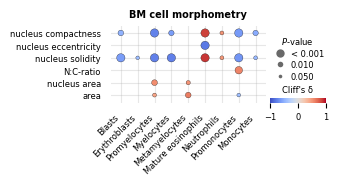

In [103]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "CBFB-MYH11",
    modality="BM",
    plot_width=2, plot_height=1,
    figure_type="supplementary_CBFB_MYH11",
    title="BM cell morphometry",
)


In [104]:
morphometry = get_significant_features("CBFB-MYH11", modality="PB", feature_type="cell_statistic")
features = morphometry.cont_col.to_list()

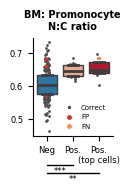

In [105]:
plot_attention_comparison(
    [
        "Promonocytes_entire_N:C-ratio_median",
    ], 
    df3_bm_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.4,
    fig_height=2,
    num_columns=1,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Promonocytes_entire_N:C-ratio_median": "BM: Promonocyte\nN:C ratio",
    },
)

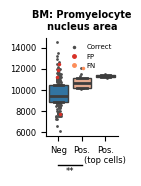

In [106]:
plot_attention_comparison(
    [
        "Promyelocytes_nucleus_area_median",
    ], 
    df3_bm_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.4,
    fig_height=2,
    num_columns=1,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Promyelocytes_nucleus_area_median": "BM: Promyelocyte\nnucleus area",
    },
)


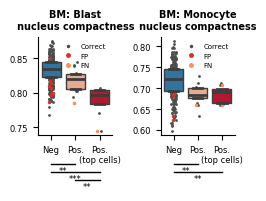

In [107]:
plot_attention_comparison(
    [
        "Blasts_nucleus_compactness_median",
        "Monocytes_nucleus_compactness_median",
    ], 
    df3_bm_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=2.6,
    fig_height=2,
    num_columns=2,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Blasts_nucleus_compactness_median": "BM: Blast\nnucleus compactness",
        "Monocytes_nucleus_compactness_median": "BM: Monocyte\nnucleus compactness",
    },
)

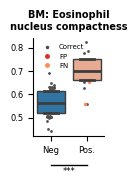

In [108]:
plot_attention_comparison(
    [
        "Eosinophils_nucleus_compactness_median",
    ], 
    df3_bm_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    num_columns=1,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Eosinophils_nucleus_compactness_median": "BM: Eosinophil\nnucleus compactness",
    },
)

#### **CBFB-MYH11: PB Morphometry**

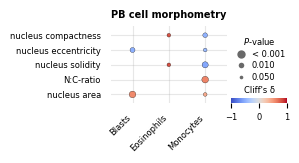

In [109]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "CBFB-MYH11",
    modality="PB",
    plot_width=1.5, plot_height=1,
    figure_type="supplementary_CBFB_MYH11",
    title="PB cell morphometry",
)


In [110]:
morphometry = get_significant_features("CBFB-MYH11", modality="PB", feature_type="cell_statistic")
features = morphometry.cont_col.to_list()

# extra outlier filter:
#df3_pb_cbf_myh11 = df3_pb_cbf_myh11[df3_pb_cbf_myh11["Monocytes_nucleus_area_median"] < 30000]

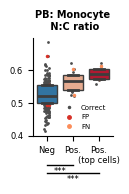

In [111]:
plot_attention_comparison(
    [
        "Monocytes_entire_N:C-ratio_median",
    ], 
    df3_pb_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.4,
    fig_height=2,
    num_columns=1,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Monocytes_entire_N:C-ratio_median": "PB: Monocyte\n N:C ratio",
    },
)

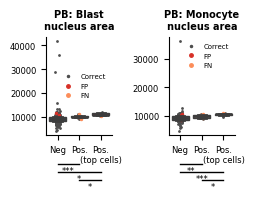

In [112]:
plot_attention_comparison(
    [
        "Blasts_nucleus_area_median",
        "Monocytes_nucleus_area_median",
    ], 
    df3_pb_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=2.6,
    fig_height=2,
    num_columns=2,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Monocytes_nucleus_area_median": "PB: Monocyte\nnucleus area",
        "Monocytes_entire_N:C-ratio_median": "PB: Monocyte\n N:C ratio",
        "Blasts_nucleus_area_median": "PB: Blast\nnucleus area",
        "Monocytes_nucleus_compactness_median": "PB: Monocyte\n nucleus compactness",
        "Eosinophils_nucleus_compactness_median": "PB: Eosinophil\n nucleus compactness",
    },
)

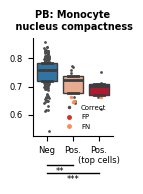

In [113]:

plot_attention_comparison(
    [
        "Monocytes_nucleus_compactness_median",
    ], 
    df3_pb_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.4,
    fig_height=2,
    num_columns=1,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Monocytes_nucleus_compactness_median": "PB: Monocyte\n nucleus compactness",
    },
)

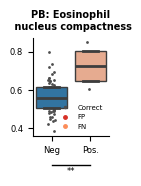

In [114]:
plot_attention_comparison(
    [
        "Eosinophils_nucleus_compactness_median" 
    ], 
    df3_pb_cbf_myh11,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    num_columns=1,
    prediction_col="CBFB-MYH11_predicted",
    feature_labels={
        "Eosinophils_nucleus_compactness_median": "PB: Eosinophil\n nucleus compactness",
    },
)

### **RUNX1-RUNX1T1**

In [115]:
df3_bm_runx1 = build_three_group_df("RUNX1-RUNX1T1_OR_t_8_21", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_runx1 = df3_bm_runx1.merge(
    df_bm[["database_id", "album_id", "RUNX1-RUNX1T1_OR_t_8_21_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_runx1 = build_three_group_df("RUNX1-RUNX1T1_OR_t_8_21", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_runx1 = df3_pb_runx1.merge(
    df_pb[["database_id", "album_id", "RUNX1-RUNX1T1_OR_t_8_21_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **RUNX1-RUNX1T1: BM Differentials**

In [116]:
get_significant_features("RUNX1-RUNX1T1_OR_t_8_21", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
13,BM,cell_differential,Eosinophils_proportion,0.013,0.314
14,BM,cell_differential,Eosinophils_immature_proportion,0.001,0.433
15,BM,cell_differential,Metamyelocytes_proportion,0.013,0.325
16,BM,cell_differential,Myelocytes_proportion,0.005,0.365
17,BM,cell_differential,Promyelocytes_proportion,0.020,0.291


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


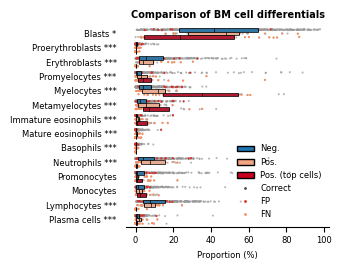

In [117]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_runx1,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="RUNX1-RUNX1T1_OR_t_8_21_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_runx1",
    title="Comparison of BM cell differentials",
)

#### **RUNX1-RUNX1T1: PB Differentials**

In [118]:
get_significant_features("RUNX1-RUNX1T1_OR_t_8_21", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
415,PB,cell_differential,Monocytes_proportion,0.006,-0.353
416,PB,cell_differential,Metamyelocytes_proportion,0.002,0.413
417,PB,cell_differential,Myelocytes_proportion,0.018,0.306
418,PB,cell_differential,Erythroblasts_proportion,0.024,-0.285


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


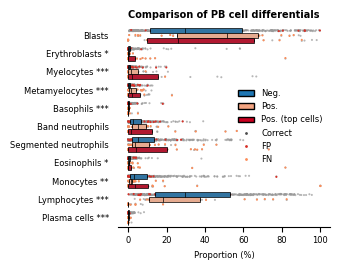

In [119]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_runx1,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="RUNX1-RUNX1T1_OR_t_8_21_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_runx1",
    title="Comparison of PB cell differentials",
)

#### **RUNX1-RUNX1T1: BM Dysplasia**

In [120]:
get_significant_features("RUNX1-RUNX1T1_OR_t_8_21", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
138,BM,dysplasia,Myelocytes-vacuolated_proportion,0.013,0.352
139,BM,dysplasia,Promyelocytes-vacuolated_proportion,0.001,0.597


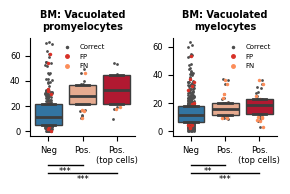

In [121]:

plot_attention_comparison(
    ["Promyelocytes-vacuolated_proportion", "Myelocytes-vacuolated_proportion"],
    df3_bm_runx1,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=3,
    fig_height=2,
    prediction_col="RUNX1-RUNX1T1_OR_t_8_21_predicted",
    feature_labels={
        "Promyelocytes-vacuolated_proportion": "BM: Vacuolated\npromyelocytes",
        "Myelocytes-vacuolated_proportion": "BM: Vacuolated\nmyelocytes",
    },
)

#### **RUNX1-RUNX1T1: PB Dysplasia**

In [122]:
get_significant_features("RUNX1-RUNX1T1_OR_t_8_21", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


#### **RUNX1-RUNX1T1: BM Morphometry**

In [123]:
get_significant_features("RUNX1-RUNX1T1_OR_t_8_21", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
220,BM,cell_statistic,Eosinophils_immature_nucleus_solidity_median,0.014,-0.489
221,BM,cell_statistic,Eosinophils_immature_nucleus_area_median,0.014,0.504
222,BM,cell_statistic,Eosinophils_immature_entire_area_median,0.014,0.491
223,BM,cell_statistic,Metamyelocytes_nucleus_area_median,0.003,0.487
224,BM,cell_statistic,Metamyelocytes_entire_area_median,0.026,0.385
225,BM,cell_statistic,Myelocytes_nucleus_area_median,0.001,0.506
226,BM,cell_statistic,Myelocytes_entire_area_median,0.001,0.499


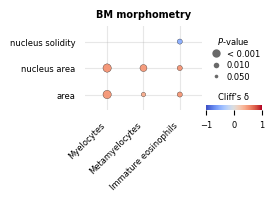

In [124]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "RUNX1-RUNX1T1_OR_t_8_21",
    modality="BM",
    plot_width=1.5, plot_height=1.1,
    title="BM morphometry",
    figure_type="supplementary_runx1",
)

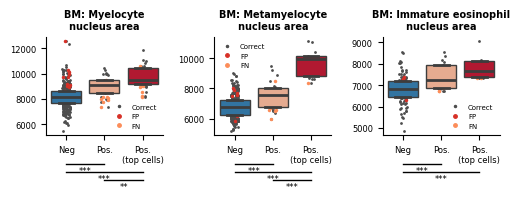

In [125]:
plot_attention_comparison(
    ["Myelocytes_nucleus_area_median", "Metamyelocytes_nucleus_area_median", "Eosinophils_immature_nucleus_area_median"],
    df3_bm_runx1,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=5.2,
    fig_height=2,
    prediction_col="RUNX1-RUNX1T1_OR_t_8_21_predicted",
    feature_labels={
        "Myelocytes_nucleus_area_median": "BM: Myelocyte\nnucleus area",
        "Metamyelocytes_nucleus_area_median": "BM: Metamyelocyte\nnucleus area",
        "Eosinophils_immature_nucleus_area_median": "BM: Immature eosinophil\nnucleus area",
    },
)

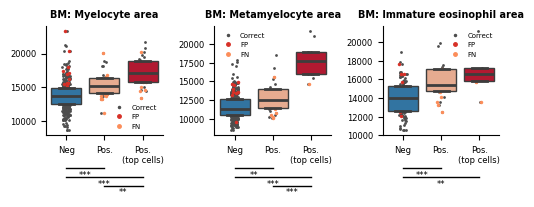

In [126]:
plot_attention_comparison(
    ["Myelocytes_entire_area_median", "Metamyelocytes_entire_area_median", "Eosinophils_immature_entire_area_median"],
    df3_bm_runx1,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=5.2,
    fig_height=2,
    prediction_col="RUNX1-RUNX1T1_OR_t_8_21_predicted",
    feature_labels={
        "Myelocytes_entire_area_median": "BM: Myelocyte area",
        "Metamyelocytes_entire_area_median": "BM: Metamyelocyte area",
        "Eosinophils_immature_entire_area_median": "BM: Immature eosinophil area",
    },
)

#### **RUNX1-RUNX1T1: PB Morphometry**

In [127]:
get_significant_features("RUNX1-RUNX1T1_OR_t_8_21", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
486,PB,cell_statistic,Blasts_nucleus_eccentricity_median,0.035,-0.377
487,PB,cell_statistic,Blasts_nucleus_compactness_median,0.039,0.340
488,PB,cell_statistic,Blasts_entire_N:C-ratio_median,0.039,0.353


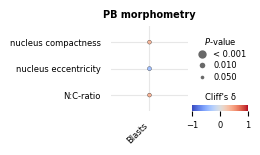

In [128]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "RUNX1-RUNX1T1_OR_t_8_21",
    modality="PB",
    plot_width=1, plot_height=1.1,
    title="PB morphometry",
    figure_type="supplementary_runx1",
)

### **IDH mutations**

In [129]:
df3_bm_idh = build_three_group_df("IDH_mutations", df_bm, df_attn_bm, cell_df_bm, aggregate_bm_dataset,
                                   post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_idh = df3_bm_idh.merge(
    df_bm[["database_id", "album_id", "IDH_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_idh = build_three_group_df("IDH_mutations", df_pb, df_attn_pb, cell_df_pb, aggregate_pb_dataset,
                                   post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_idh = df3_pb_idh.merge(
    df_pb[["database_id", "album_id", "IDH_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)


#### **IDH mutations: Cell differentials**

In [130]:
get_significant_features("IDH_mutations", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
18,BM,cell_differential,Promonocytes_proportion,0.003,-0.233
19,BM,cell_differential,Basophils_proportion,0.001,-0.290
20,BM,cell_differential,Eosinophils_proportion,0.001,-0.343
21,BM,cell_differential,Eosinophils_immature_proportion,0.001,-0.496
22,BM,cell_differential,Promyelocytes_proportion,0.016,-0.196
23,BM,cell_differential,Blasts_proportion,0.003,0.239


In [131]:
get_significant_features("IDH_mutations", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
419,PB,cell_differential,Lymphocytes_proportion,0.049,0.156
420,PB,cell_differential,Monocytes_proportion,0.014,-0.196
421,PB,cell_differential,Band_neutrophils_proportion,0.001,-0.275
422,PB,cell_differential,Basophils_proportion,0.007,-0.217
423,PB,cell_differential,Eosinophils_proportion,0.039,-0.166
424,PB,cell_differential,Metamyelocytes_proportion,0.001,-0.352
425,PB,cell_differential,Myelocytes_proportion,0.001,-0.267


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


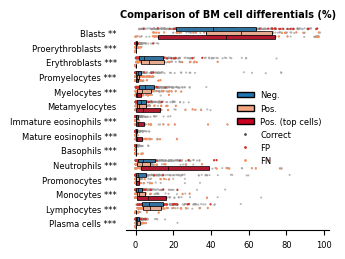

/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


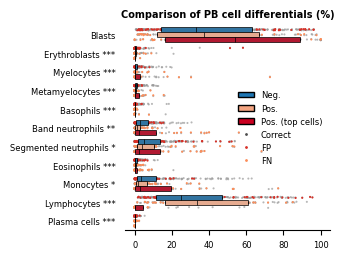

In [132]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()), df3_bm_idh,
    xlabel="", fig_width=3.5, fig_height=2.7,
    prediction_col="IDH_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_IDH_mutations",
    title="Comparison of BM cell differentials (%)",
)
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()), df3_pb_idh,
    xlabel="", fig_width=3.5, fig_height=2.7,
    prediction_col="IDH_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_IDH_mutations",
    title="Comparison of PB cell differentials (%)",
)


#### **IDH mutations: BM Dysplasia**

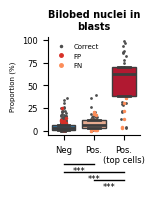

In [133]:
results = get_significant_features("IDH_mutations", modality="BM", feature_type="dysplasia")
features = filter_stats(results).cont_col.to_list()

if False:
    display(results)
    plot_attention_comparison(
        features, df3_bm_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        fig_width=12, fig_height=5, num_columns=4,
        prediction_col="IDH_mutations_predicted",
    )

if True:  # fill in selected features after exploring
    plot_attention_comparison(
        ["Blasts_bilobed_proportion"],
        df3_bm_idh, ylabel="Proportion (%)",
        wt_label="Neg", mut_label="Pos.",
        fig_width=1.6, fig_height=2, num_columns=1,
        prediction_col="IDH_mutations_predicted",
        feature_labels={"Blasts_bilobed_proportion": "Bilobed nuclei in\nblasts"}
    )


#### **IDH mutations: PB Dysplasia**

In [134]:
results = get_significant_features("IDH_mutations", modality="PB", feature_type="dysplasia")
features = filter_stats(results).cont_col.to_list()

if True:
    display(results)
    plot_attention_comparison(
        features, df3_pb_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        fig_width=12, fig_height=5, num_columns=4,
        prediction_col="IDH_mutations_predicted",
    )

if False:
    plot_attention_comparison(
        [],
        df3_pb_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        prediction_col="IDH_mutations_predicted",
    )


,modality,feature_type,cont_col,p-value,Log10_FC


No matching columns in df_three


#### **IDH mutations: BM Morphometry**

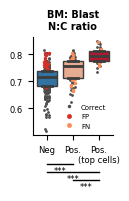

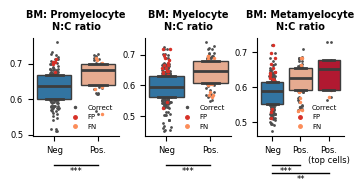

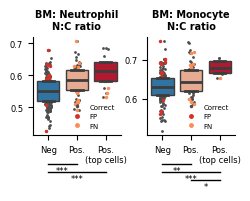

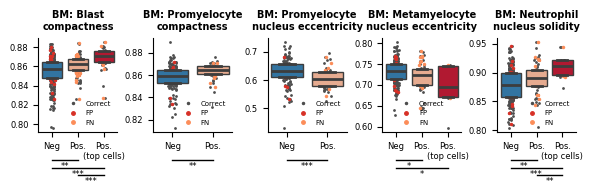

In [135]:
morphometry = get_significant_features("IDH_mutations", modality="BM", feature_type="cell_statistic")
features = filter_stats(morphometry).cont_col.to_list()

# tempoarary filter out N:C ratio features to reduce number of plots, since many are significant and attention is spread across them
features = [f for f in features if "area" in f]

if False:
    display(morphometry)
    plot_attention_comparison(
        features, df3_bm_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        fig_width=12, fig_height=10, num_columns=4,
        prediction_col="IDH_mutations_predicted",
    )

if True:

    plot_attention_comparison(
        [
            # N:C ratio
            "Blasts_entire_N:C-ratio_median",
        ],
        df3_bm_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        prediction_col="IDH_mutations_predicted",
        fig_width=1.4, fig_height=2, num_columns=1, wspace=0.3,
        feature_labels={
            "Blasts_entire_N:C-ratio_median": "BM: Blast\nN:C ratio",
        }
    )

    plot_attention_comparison(
        [
            # N:C ratio
            "Promyelocytes_entire_N:C-ratio_median",
            "Myelocytes_entire_N:C-ratio_median",
            "Metamyelocytes_entire_N:C-ratio_median",
        ],
        df3_bm_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        prediction_col="IDH_mutations_predicted",
        fig_width=3.75, fig_height=2, num_columns=3, wspace=0.3,
        feature_labels={
            "Promyelocytes_entire_N:C-ratio_median": "BM: Promyelocyte\nN:C ratio",
            "Myelocytes_entire_N:C-ratio_median": "BM: Myelocyte\nN:C ratio",
            "Metamyelocytes_entire_N:C-ratio_median": "BM: Metamyelocyte\nN:C ratio",
        }
    )

    plot_attention_comparison(
        [
            "Neutrophils_entire_N:C-ratio_median",
            "Monocytes_entire_N:C-ratio_median",
        ],
        df3_bm_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        prediction_col="IDH_mutations_predicted",
        fig_width=2.65, fig_height=2, num_columns=3, wspace=0.3,
        feature_labels={
            "Neutrophils_entire_N:C-ratio_median": "BM: Neutrophil\nN:C ratio",
            "Monocytes_entire_N:C-ratio_median": "BM: Monocyte\nN:C ratio",
        }
    )


    plot_attention_comparison(
        [
            "Blasts_entire_compactness_median",
            "Promyelocytes_entire_compactness_median",
            "Promyelocytes_nucleus_eccentricity_median",
            "Metamyelocytes_nucleus_eccentricity_median",
            "Neutrophils_nucleus_solidity_median", 
        ],
        df3_bm_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        prediction_col="IDH_mutations_predicted",
        fig_width=6.25, fig_height=2, num_columns=5, wspace=0.45,
        feature_labels={
            "Blasts_entire_compactness_median": "BM: Blast\ncompactness",
            "Promyelocytes_entire_compactness_median": "BM: Promyelocyte\ncompactness",
            "Promyelocytes_nucleus_eccentricity_median": "BM: Promyelocyte\nnucleus eccentricity",
            "Metamyelocytes_nucleus_eccentricity_median": "BM: Metamyelocyte\nnucleus eccentricity",
            "Neutrophils_nucleus_solidity_median": "BM: Neutrophil\nnucleus solidity",
        }
    )


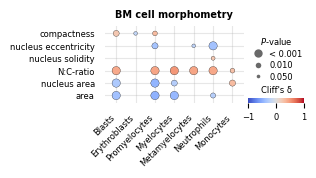

In [136]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "IDH_mutations",
    modality="BM",
    plot_width=1.8, plot_height=1,
    figure_type="supplementary_IDH_mutations",
    title="BM cell morphometry",
)

#### **IDH mutations: PB Morphometry**

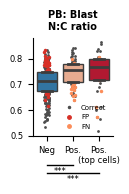

In [137]:
morphometry = get_significant_features("IDH_mutations", modality="PB", feature_type="cell_statistic")
features = morphometry.cont_col.to_list()

if False:
    display(morphometry)
    plot_attention_comparison(
        features, df3_pb_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        fig_width=3.2, fig_height=2, num_columns=2,
        prediction_col="IDH_mutations_predicted",
    )

if True:
    plot_attention_comparison(
        ["Blasts_entire_N:C-ratio_median"],
        df3_pb_idh, ylabel="",
        wt_label="Neg", mut_label="Pos.",
        fig_width=1.4, fig_height=2, num_columns=1,
        prediction_col="IDH_mutations_predicted",
        feature_labels={"Blasts_entire_N:C-ratio_median": "PB: Blast\nN:C ratio"}
    )


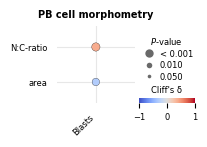

In [138]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "IDH_mutations",
    modality="PB",
    plot_width=1, plot_height=1,
    figure_type="supplementary_IDH_mutations",
    title="PB cell morphometry",
)


### **CpG mutations**

In [139]:
df3_bm_cpg = build_three_group_df("CpG_mutations", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_cpg = df3_bm_cpg.merge(
    df_bm[["database_id", "album_id", "CpG_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_cpg = build_three_group_df("CpG_mutations", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_cpg = df3_pb_cpg.merge(
    df_pb[["database_id", "album_id", "CpG_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **CpG mutations: BM Differentials**

In [140]:
get_significant_features("CpG_mutations", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
31,BM,cell_differential,Lymphocytes_proportion,0.019,-0.167
32,BM,cell_differential,Basophils_proportion,0.003,-0.203
33,BM,cell_differential,Eosinophils_proportion,0.001,-0.283
34,BM,cell_differential,Eosinophils_immature_proportion,0.001,-0.310


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


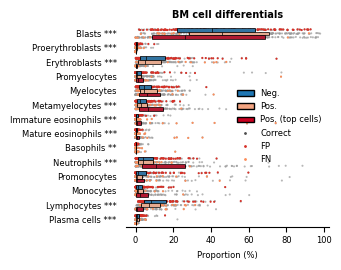

In [141]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_cpg,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="CpG_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_cpg_bm_differemtials",
    title="BM cell differentials",
)

#### **CpG mutations: PB Differentials**

In [142]:
get_significant_features("CpG_mutations", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


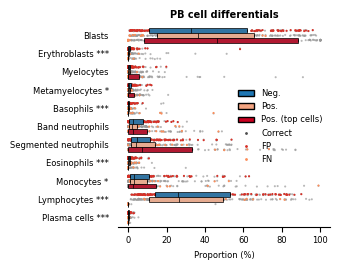

In [143]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_cpg,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="CpG_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_cpg_pb_differentials",
    title="PB cell differentials",
)

#### **CpG mutations: BM Dysplasia**

In [144]:
get_significant_features("CpG_mutations", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


In [145]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_bm_cpg,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="CpG_mutations_predicted",
    )

#### **CpG mutations: PB Dysplasia**

In [146]:
get_significant_features("CpG_mutations", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
465,PB,dysplasia,Neutrophils-neut_gran_hyper_proportion,0.002,-0.234
466,PB,dysplasia,Neutrophils-neut_gran_hypo_proportion,0.007,0.197


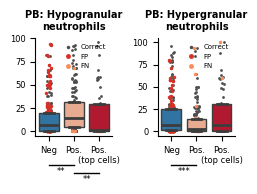

In [147]:

plot_attention_comparison(
    ["Neutrophils-neut_gran_hypo_proportion", "Neutrophils-neut_gran_hyper_proportion", ],
    df3_pb_cpg,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=2.6,
    fig_height=2,
    prediction_col="CpG_mutations_predicted",
    feature_labels={
        "Neutrophils-neut_gran_hyper_proportion": "PB: Hypergranular\nneutrophils",
        "Neutrophils-neut_gran_hypo_proportion": "PB: Hypogranular\nneutrophils",
    },
)

#### **CpG mutations: BM Morphometry**

In [148]:
get_significant_features("CpG_mutations", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
261,BM,cell_statistic,Metamyelocytes_entire_N:C-ratio_median,0.019,0.219
262,BM,cell_statistic,Myelocytes_entire_N:C-ratio_median,0.004,0.234
263,BM,cell_statistic,Myelocytes_entire_area_median,0.004,-0.235
264,BM,cell_statistic,Promyelocytes_nucleus_compactness_median,0.025,0.246
265,BM,cell_statistic,Promyelocytes_nucleus_eccentricity_median,0.002,-0.326
266,BM,cell_statistic,Promyelocytes_entire_N:C-ratio_median,0.003,0.310
267,BM,cell_statistic,Promyelocytes_nucleus_area_median,0.001,-0.421
268,BM,cell_statistic,Promyelocytes_entire_area_median,0.001,-0.456
269,BM,cell_statistic,Erythroblasts_entire_compactness_median,0.003,-0.242
270,BM,cell_statistic,Blasts_entire_compactness_median,0.008,0.200


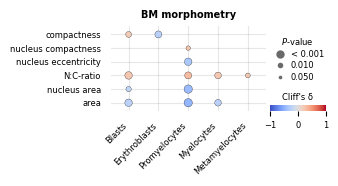

In [149]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "CpG_mutations",
    modality="BM",
    plot_width=2, plot_height=1.1,
    title="BM morphometry",
    figure_type="supplementary_cpg_bm_morphometry",
)

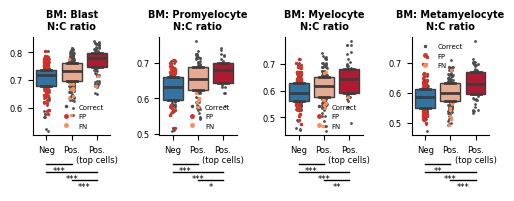

In [150]:
plot_attention_comparison(
    [
        "Blasts_entire_N:C-ratio_median",
        "Promyelocytes_entire_N:C-ratio_median",
        "Myelocytes_entire_N:C-ratio_median",
        "Metamyelocytes_entire_N:C-ratio_median",
    ],
    df3_bm_cpg,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=5.2,
    fig_height=2,
    prediction_col="CpG_mutations_predicted",
    feature_labels={
        "Blasts_entire_N:C-ratio_median": "BM: Blast\nN:C ratio",
        "Promyelocytes_entire_N:C-ratio_median": "BM: Promyelocyte\nN:C ratio",
        "Myelocytes_entire_N:C-ratio_median": "BM: Myelocyte\nN:C ratio",
        "Metamyelocytes_entire_N:C-ratio_median": "BM: Metamyelocyte\nN:C ratio",
    },
)

#### **CpG mutations: PB Morphometry**

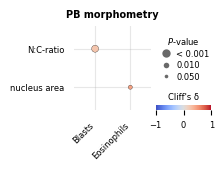

In [151]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "CpG_mutations",
    modality="PB",
    plot_width=1, plot_height=1.1,
    title="PB morphometry",
    figure_type="supplementary_cpg_pb_morphometry",
)

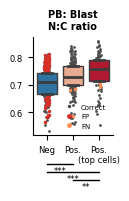

In [152]:
plot_attention_comparison(
    [
        "Blasts_entire_N:C-ratio_median",
    ],
    df3_pb_cpg,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=1.4,
    fig_height=2,
    prediction_col="CpG_mutations_predicted",
    feature_labels={
        "Blasts_entire_N:C-ratio_median": "PB: Blast\nN:C ratio",
    },
)

### **NPM1**

In [153]:
df3_bm_npm1 = build_three_group_df("NPM1", df_bm, df_attn_bm, cell_df_bm, aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_npm1 = df3_bm_npm1.merge(
    df_bm[["database_id", "album_id", "NPM1_predicted"]],
    on=["database_id", "album_id"], how="left"
)


df3_pb_npm1 = build_three_group_df("NPM1", df_pb, df_attn_pb, cell_df_pb, aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_npm1 = df3_pb_npm1.merge(
    df_pb[["database_id", "album_id", "NPM1_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **NPM1: BM Differentials**

In [154]:
get_significant_features("NPM1", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
35,BM,cell_differential,Plasma_cells_proportion,0.001,-0.301
36,BM,cell_differential,Lymphocytes_proportion,0.001,-0.487
37,BM,cell_differential,Promonocytes_proportion,0.001,0.209
38,BM,cell_differential,Neutrophils_proportion,0.001,-0.236
39,BM,cell_differential,Eosinophils_proportion,0.001,-0.376
40,BM,cell_differential,Eosinophils_immature_proportion,0.001,-0.287
41,BM,cell_differential,Promyelocytes_proportion,0.001,0.267
42,BM,cell_differential,Erythroblasts_proportion,0.001,-0.410
43,BM,cell_differential,Proerythroblasts_proportion,0.009,-0.166
44,BM,cell_differential,Blasts_proportion,0.001,0.245


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


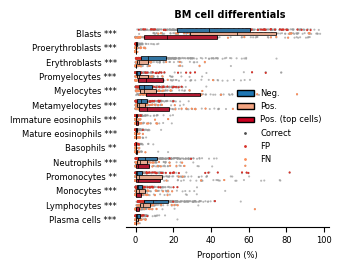

In [155]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_npm1,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="NPM1_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_NPM1_bm_differentials",
    title=" BM cell differentials",
)

#### **NPM1: PB Differentials**

In [156]:
get_significant_features("NPM1", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
430,PB,cell_differential,Lymphocytes_proportion,0.001,-0.272
431,PB,cell_differential,Monocytes_proportion,0.007,0.185
432,PB,cell_differential,Band_neutrophils_proportion,0.007,-0.186
433,PB,cell_differential,Eosinophils_proportion,0.007,-0.180
434,PB,cell_differential,Blasts_proportion,0.007,0.183


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


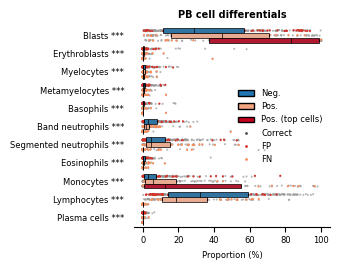

In [157]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_npm1,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="NPM1_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_NPM1_pb_differentials",
    title="PB cell differentials",
)

#### **NPM1: BM Dysplasia**

In [158]:
get_significant_features("NPM1", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
144,BM,dysplasia,Lymphocytes-vacuolated_proportion,0.014,-0.177
145,BM,dysplasia,Myelocytes-vacuolated_proportion,0.001,-0.270
146,BM,dysplasia,Promyelocytes-vacuolated_proportion,0.001,-0.417
147,BM,dysplasia,Blasts-vacuolated_proportion,0.001,-0.267
148,BM,dysplasia,Myeloid_precursors_hypergranulated_proportion,0.001,0.348


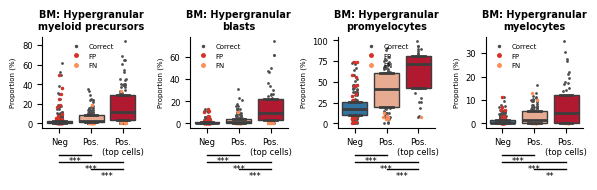

In [159]:
plot_attention_comparison(
    ["Myeloid_precursors_hypergranulated_proportion",
     "Blasts_hypergranulated_proportion", 
     "Promyelocytes_hypergranulated_proportion", 
     "Myelocytes_hypergranulated_proportion"], 
    df3_bm_npm1,
    ylabel="Proportion (%)",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=6.5,
    fig_height=2,
    prediction_col="NPM1_predicted",
    #figure_type="supplementary_NPM1_bm_dysplasia",
    feature_labels={
        "Myeloid_precursors_hypergranulated_proportion": "BM: Hypergranular\nmyeloid precursors",
        "Blasts_hypergranulated_proportion": "BM: Hypergranular\nblasts",
        "Promyelocytes_hypergranulated_proportion": "BM: Hypergranular\npromyelocytes",
        "Myelocytes_hypergranulated_proportion": "BM: Hypergranular\nmyelocytes"
    },
)

#### **NPM1: PB Dysplasia**

In [160]:
get_significant_features("NPM1", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
467,PB,dysplasia,Blasts-apl_hypergranulated_proportion,0.012,0.183
468,PB,dysplasia,APL-apl_hypergranulated_proportion,0.012,0.177


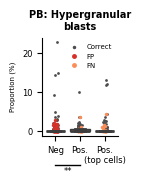

In [162]:
plot_attention_comparison(
    ["Blasts-apl_hypergranulated_proportion"], 
    df3_pb_npm1,
    ylabel="Proportion (%)",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=1.4,
    fig_height=2,
    prediction_col="NPM1_predicted",
    feature_labels={
        "Blasts-apl_hypergranulated_proportion": "PB: Hypergranular\nblasts",
    },
    #figure_type="supplementary_NPM1_pb_dysplasia",
)

#### **NPM1: BM Morphometry**

In [ ]:
get_significant_features("NPM1", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
274,BM,cell_statistic,Promonocytes_nucleus_solidity_median,0.032,0.227
275,BM,cell_statistic,Promonocytes_nucleus_area_median,0.020,0.250
276,BM,cell_statistic,Neutrophils_nucleus_eccentricity_median,0.001,-0.382
277,BM,cell_statistic,Neutrophils_entire_N:C-ratio_median,0.032,0.207
278,BM,cell_statistic,Metamyelocytes_nucleus_compactness_median,0.032,-0.207
279,BM,cell_statistic,Metamyelocytes_nucleus_solidity_median,0.005,-0.264
280,BM,cell_statistic,Metamyelocytes_entire_N:C-ratio_median,0.005,0.260
281,BM,cell_statistic,Metamyelocytes_nucleus_area_median,0.032,0.205
282,BM,cell_statistic,Myelocytes_entire_N:C-ratio_median,0.001,0.428
283,BM,cell_statistic,Myelocytes_entire_area_median,0.001,-0.351


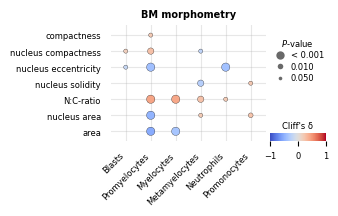

In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "NPM1",
    modality="BM",
    plot_width=2, plot_height=1.5,
    figure_type="supplementary_NPM1_bm_morphometry",
    title="BM morphometry",
)


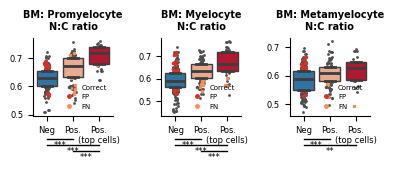

In [ ]:
plot_attention_comparison(
    [
        "Promyelocytes_entire_N:C-ratio_median", 
        "Myelocytes_entire_N:C-ratio_median",
        "Metamyelocytes_entire_N:C-ratio_median",
        #"Neutrophils_entire_N:C-ratio_median",
     ], 
    df3_bm_npm1,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=4,
    fig_height=1.8,
    num_columns=4,
    prediction_col="NPM1_predicted",
    feature_labels={
        "Promyelocytes_entire_N:C-ratio_median": "BM: Promyelocyte\nN:C ratio",
        "Myelocytes_entire_N:C-ratio_median": "BM: Myelocyte\nN:C ratio",
        "Metamyelocytes_entire_N:C-ratio_median": "BM: Metamyelocyte\nN:C ratio",
        #"Neutrophils_entire_N:C-ratio_median": "BM: Neutrophil\nN:C ratio",
    },
)

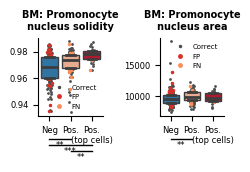

In [ ]:
plot_attention_comparison(
    [
        "Promonocytes_nucleus_solidity_median", 
        "Promonocytes_nucleus_area_median",
     ], 
    df3_bm_npm1,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=2.5,
    fig_height=1.8,
    num_columns=2,
    prediction_col="NPM1_predicted",
    feature_labels={
        "Promonocytes_nucleus_area_median": "BM: Promonocyte\nnucleus area",
        "Promonocytes_nucleus_solidity_median": "BM: Promonocyte\nnucleus solidity",
    },
)

#### **NPM1: PB Morphometry**

In [ ]:
get_significant_features("NPM1", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
497,PB,cell_statistic,Monocytes_nucleus_area_median,0.001,0.341
498,PB,cell_statistic,Monocytes_nucleus_solidity_median,0.004,0.262
499,PB,cell_statistic,Monocytes_nucleus_compactness_median,0.002,0.276
500,PB,cell_statistic,Monocytes_entire_area_median,0.001,0.519
501,PB,cell_statistic,Monocytes_entire_N:C-ratio_median,0.001,-0.359
502,PB,cell_statistic,Segmented_neutrophils_nucleus_eccentricity_median,0.001,-0.303
503,PB,cell_statistic,Band_neutrophils_entire_compactness_median,0.009,0.261


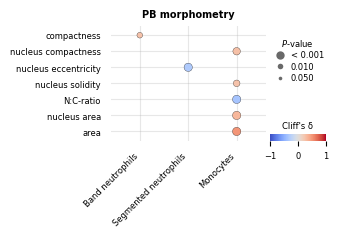

In [ ]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "NPM1",
    modality="PB",
    plot_width=2, plot_height=1.5,
    figure_type="supplementary_NPM1_pb_morphometry",
    title="PB morphometry",
)


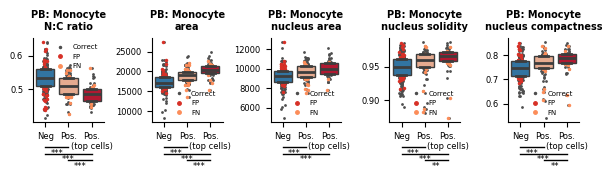

In [ ]:
temp = df3_pb_npm1[df3_pb_npm1["Monocytes_entire_area_median"] < 60000]
plot_attention_comparison(
    [
        "Monocytes_entire_N:C-ratio_median",
        "Monocytes_entire_area_median",
        "Monocytes_nucleus_area_median",
        "Monocytes_nucleus_solidity_median", 
        "Monocytes_nucleus_compactness_median",  
     ], 
    temp,
    ylabel="",
    wt_label="Neg", 
    mut_label="Pos.",
    fig_width=7,
    fig_height=2,
    num_columns=5,
    prediction_col="NPM1_predicted",
    feature_labels={
        "Monocytes_entire_N:C-ratio_median": "PB: Monocyte\nN:C ratio",
        "Monocytes_nucleus_area_median": "PB: Monocyte\nnucleus area",
        "Monocytes_nucleus_solidity_median": "PB: Monocyte\nnucleus solidity",
        "Monocytes_nucleus_compactness_median": "PB: Monocyte\nnucleus compactness",
        "Monocytes_entire_area_median": "PB: Monocyte\narea",
    },
)

### **FLT3 mutations**

In [ ]:
df3_bm_flt3 = build_three_group_df("FLT3_mutations", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_flt3 = df3_bm_flt3.merge(
    df_bm[["database_id", "album_id", "FLT3_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_flt3 = build_three_group_df("FLT3_mutations", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_flt3 = df3_pb_flt3.merge(
    df_pb[["database_id", "album_id", "FLT3_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **FLT3 mutations: BM Differentials**

In [ ]:
get_significant_features("FLT3_mutations", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
55,BM,cell_differential,Lymphocytes_proportion,0.001,-0.209
56,BM,cell_differential,Promonocytes_proportion,0.008,0.155
57,BM,cell_differential,Neutrophils_proportion,0.001,-0.290
58,BM,cell_differential,Basophils_proportion,0.005,-0.167
59,BM,cell_differential,Eosinophils_proportion,0.005,-0.166
60,BM,cell_differential,Metamyelocytes_proportion,0.001,-0.223
61,BM,cell_differential,Myelocytes_proportion,0.013,-0.142
62,BM,cell_differential,Erythroblasts_proportion,0.001,-0.231
63,BM,cell_differential,Proerythroblasts_proportion,0.008,-0.154
64,BM,cell_differential,Blasts_proportion,0.001,0.254


/tmp/ipykernel_2099597/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


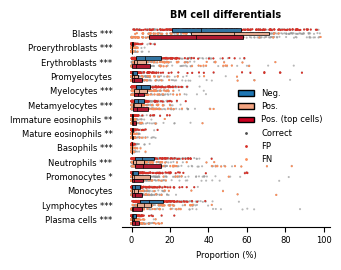

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_flt3,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="FLT3_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_flt3_bm_differentials",
    title="BM cell differentials",
)

#### **FLT3 mutations: PB Differentials**

In [ ]:
get_significant_features("FLT3_mutations", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
441,PB,cell_differential,Lymphocytes_proportion,0.001,-0.276
442,PB,cell_differential,Band_neutrophils_proportion,0.017,-0.155
443,PB,cell_differential,Blasts_proportion,0.001,0.254


/tmp/ipykernel_2099597/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


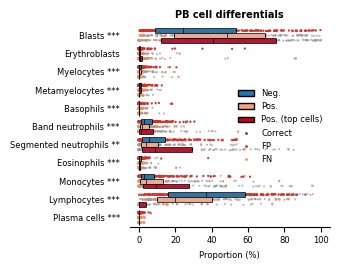

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_flt3,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="FLT3_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_flt3_pb_differentials",
    title="PB cell differentials",
)

#### **FLT3 mutations: BM Dysplasia**

In [ ]:
get_significant_features("FLT3_mutations", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


In [ ]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_bm_flt3,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="FLT3_mutations_predicted",
    )

#### **FLT3 mutations: PB Dysplasia**

In [ ]:
get_significant_features("FLT3_mutations", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
469,PB,dysplasia,Neutrophils-neut_gran_normal_proportion,0.042,0.16


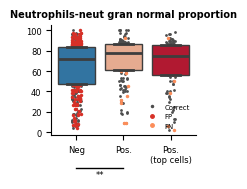

In [ ]:
plot_attention_comparison(
    ["Neutrophils-neut_gran_normal_proportion"],
    df3_pb_flt3,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=2,
    fig_height=2,
    prediction_col="FLT3_mutations_predicted",
)

#### **FLT3 mutations: BM Morphometry**

In [ ]:
get_significant_features("FLT3_mutations", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
293,BM,cell_statistic,Metamyelocytes_nucleus_area_median,0.03,0.245


In [ ]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_bm_flt3,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="FLT3_mutations_predicted",
    )

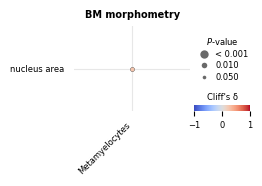

In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "FLT3_mutations",
    modality="BM",
    plot_width=1.5, plot_height=1.1,
    title="BM morphometry",
    figure_type="supplementary_flt3_bm_morphometry",
)

#### **FLT3 mutations: PB Morphometry**

In [ ]:
get_significant_features("FLT3_mutations", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
513,PB,cell_statistic,Monocytes_nucleus_solidity_median,0.045,0.196
514,PB,cell_statistic,Monocytes_nucleus_compactness_median,0.006,0.243
515,PB,cell_statistic,Monocytes_entire_area_median,0.040,0.203
516,PB,cell_statistic,Blasts_nucleus_area_median,0.001,0.237
517,PB,cell_statistic,Blasts_entire_area_median,0.004,0.212


In [ ]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_pb_flt3,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="FLT3_mutations_predicted",
    )

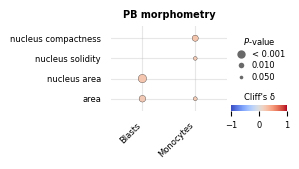

In [ ]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "FLT3_mutations",
    modality="PB",
    plot_width=1.5, plot_height=1.1,
    title="PB morphometry",
    figure_type="supplementary_flt3_pb_morphometry",
)

### **KIT**

In [ ]:
df3_bm_kit = build_three_group_df("KIT", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_kit = df3_bm_kit.merge(
    df_bm[["database_id", "album_id", "KIT_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_kit = build_three_group_df("KIT", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_kit = df3_pb_kit.merge(
    df_pb[["database_id", "album_id", "KIT_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **KIT: BM Differentials**

In [ ]:
get_significant_features("KIT", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
75,BM,cell_differential,Lymphocytes_proportion,0.004,-0.518
76,BM,cell_differential,Monocytes_proportion,0.048,0.345
77,BM,cell_differential,Eosinophils_proportion,0.048,0.353
78,BM,cell_differential,Eosinophils_immature_proportion,0.031,0.388
79,BM,cell_differential,Promyelocytes_proportion,0.001,0.732
80,BM,cell_differential,Erythroblasts_proportion,0.004,-0.509
81,BM,cell_differential,Proerythroblasts_proportion,0.006,-0.483


/tmp/ipykernel_2099597/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


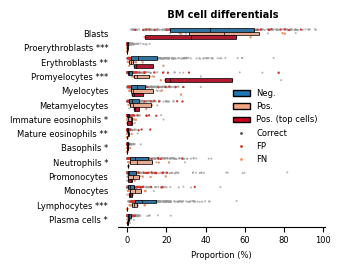

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_kit,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="KIT_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_kit_bm_differentials",
    title=" BM cell differentials",
)

#### **KIT: PB Differentials**

In [ ]:
get_significant_features("KIT", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC


/tmp/ipykernel_2099597/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


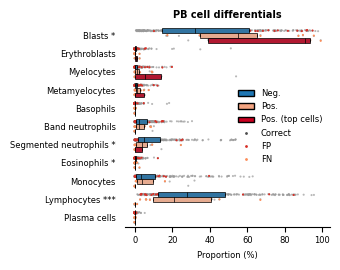

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_kit,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="KIT_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_kit_pb_differentials",
    title="PB cell differentials",
)

#### **KIT: BM Dysplasia**

In [ ]:
get_significant_features("KIT", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
149,BM,dysplasia,Myelocytes-vacuolated_proportion,0.024,0.436
150,BM,dysplasia,Promyelocytes-vacuolated_proportion,0.001,0.586
151,BM,dysplasia,Myeloid_precursors_bilobed_proportion,0.001,0.725


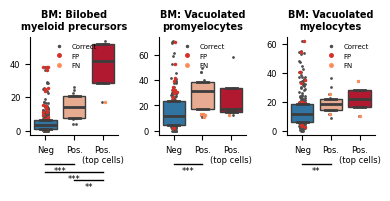

In [ ]:
plot_attention_comparison(
    [
        "Myeloid_precursors_bilobed_proportion",
        "Promyelocytes-vacuolated_proportion",
        "Myelocytes-vacuolated_proportion"
     ],
    df3_bm_kit,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=4,
    fig_height=2,
    prediction_col="KIT_predicted",
    feature_labels={
        "Myeloid_precursors_bilobed_proportion": "BM: Bilobed\nmyeloid precursors",
        "Promyelocytes-vacuolated_proportion": "BM: Vacuolated\npromyelocytes",
        "Myelocytes-vacuolated_proportion": "BM: Vacuolated\nmyelocytes",
    },
)

#### **KIT: PB Dysplasia**

In [ ]:
get_significant_features("KIT", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


In [ ]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_pb_kit,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="KIT_predicted",
    )

#### **KIT: BM Morphometry**

In [ ]:
get_significant_features("KIT", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
295,BM,cell_statistic,Monocytes_nucleus_area_median,0.044,0.462
296,BM,cell_statistic,Monocytes_entire_area_median,0.040,0.476
297,BM,cell_statistic,Promonocytes_nucleus_compactness_median,0.005,-0.619
298,BM,cell_statistic,Promonocytes_nucleus_solidity_median,0.007,-0.601
299,BM,cell_statistic,Promonocytes_entire_N:C-ratio_median,0.040,0.478
300,BM,cell_statistic,Metamyelocytes_nucleus_compactness_median,0.040,-0.450
301,BM,cell_statistic,Metamyelocytes_nucleus_area_median,0.002,0.692
302,BM,cell_statistic,Metamyelocytes_entire_area_median,0.004,0.629
303,BM,cell_statistic,Myelocytes_nucleus_compactness_median,0.005,-0.546
304,BM,cell_statistic,Myelocytes_nucleus_solidity_median,0.002,-0.609


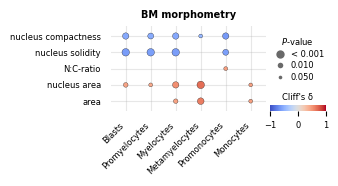

In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "KIT",
    modality="BM",
    plot_width=2, plot_height=1.1,
    title="BM morphometry",
    figure_type="supplementary_kit_bm_morphometry",
)

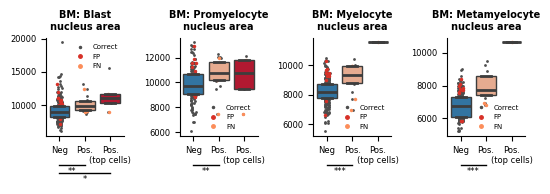

In [ ]:
plot_attention_comparison(
    [
        "Blasts_nucleus_area_median",
        "Promyelocytes_nucleus_area_median",
        "Myelocytes_nucleus_area_median",
        "Metamyelocytes_nucleus_area_median",
     ],
    df3_bm_kit,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=5.5,
    fig_height=2,
    num_columns=4,
    prediction_col="KIT_predicted",
    feature_labels={
        "Blasts_nucleus_area_median": "BM: Blast\nnucleus area",
        "Promyelocytes_nucleus_area_median": "BM: Promyelocyte\nnucleus area",
        "Myelocytes_nucleus_area_median": "BM: Myelocyte\nnucleus area",
        "Metamyelocytes_nucleus_area_median": "BM: Metamyelocyte\nnucleus area",
    },
)

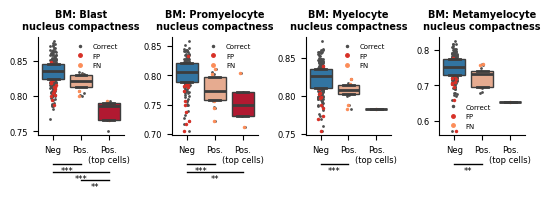

In [ ]:
plot_attention_comparison(
    [
        "Blasts_nucleus_compactness_median",
        "Promyelocytes_nucleus_compactness_median",
        "Myelocytes_nucleus_compactness_median",
        "Metamyelocytes_nucleus_compactness_median",
     ],
    df3_bm_kit,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=5.5,
    fig_height=2,
    num_columns=4,
    prediction_col="KIT_predicted",
    feature_labels={
        "Blasts_nucleus_compactness_median": "BM: Blast\nnucleus compactness",
        "Promyelocytes_nucleus_compactness_median": "BM: Promyelocyte\nnucleus compactness",
        "Myelocytes_nucleus_compactness_median": "BM: Myelocyte\nnucleus compactness",
        "Metamyelocytes_nucleus_compactness_median": "BM: Metamyelocyte\nnucleus compactness",
    },
)

#### **KIT: PB Morphometry**

In [ ]:
get_significant_features("KIT", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC


In [ ]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_pb_kit,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="KIT_predicted",
    )

In [ ]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "KIT",
    modality="PB",
    plot_width=4, plot_height=3,
    title="PB morphometry (KIT)",
    figure_type="supplementary_kit",
)

No significant morphometry associations for KIT (PB)


### **RTK-RAS mutations**

In [ ]:
df3_bm_rtk_ras = build_three_group_df("RTK_RAS_mutations", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_rtk_ras = df3_bm_rtk_ras.merge(
    df_bm[["database_id", "album_id", "RTK_RAS_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_rtk_ras = build_three_group_df("RTK_RAS_mutations", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_rtk_ras = df3_pb_rtk_ras.merge(
    df_pb[["database_id", "album_id", "RTK_RAS_mutations_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **RTK-RAS mutations: BM Differentials**

In [ ]:
get_significant_features("RTK_RAS_mutations", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
82,BM,cell_differential,Plasma_cells_proportion,0.023,-0.155
83,BM,cell_differential,Lymphocytes_proportion,0.001,-0.273
84,BM,cell_differential,Promonocytes_proportion,0.001,0.273
85,BM,cell_differential,Neutrophils_proportion,0.001,-0.227
86,BM,cell_differential,Metamyelocytes_proportion,0.040,-0.139
87,BM,cell_differential,Erythroblasts_proportion,0.001,-0.315
88,BM,cell_differential,Proerythroblasts_proportion,0.002,-0.208
89,BM,cell_differential,Blasts_proportion,0.001,0.216


/tmp/ipykernel_2099597/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


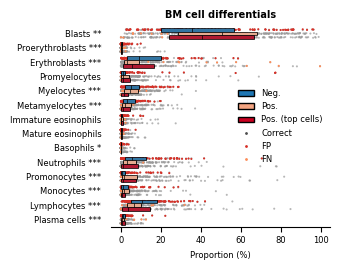

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_rtk_ras,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="RTK_RAS_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_rtk_ras_bm_differentials",
    title="BM cell differentials",
)

#### **RTK-RAS mutations: PB Differentials**

In [ ]:
get_significant_features("RTK_RAS_mutations", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
447,PB,cell_differential,Lymphocytes_proportion,0.001,-0.254
448,PB,cell_differential,Band_neutrophils_proportion,0.018,-0.173
449,PB,cell_differential,Blasts_proportion,0.003,0.211


/tmp/ipykernel_2099597/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


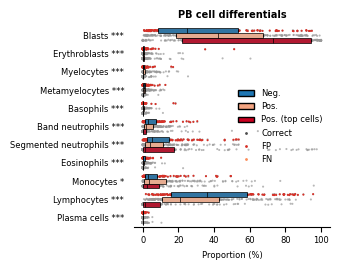

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_rtk_ras,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="RTK_RAS_mutations_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_rtk_ras_pb_differentials",
    title="PB cell differentials",
)

#### **RTK-RAS mutations: BM Dysplasia**

In [ ]:
get_significant_features("RTK_RAS_mutations", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


In [ ]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_bm_rtk_ras,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="RTK_RAS_mutations_predicted",
    )

#### **RTK-RAS mutations: PB Dysplasia**

In [ ]:
get_significant_features("RTK_RAS_mutations", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


In [ ]:
if False:
    plot_attention_comparison(
        ["FEATURE_1", "FEATURE_2"],
        df3_pb_rtk_ras,
        ylabel="",
        wt_label="Neg",
        mut_label="Pos.",
        fig_width=4,
        fig_height=3,
        prediction_col="RTK_RAS_mutations_predicted",
    )

#### **RTK-RAS mutations: BM Morphometry**

In [ ]:
get_significant_features("RTK_RAS_mutations", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
313,BM,cell_statistic,Metamyelocytes_entire_compactness_median,0.018,-0.235
314,BM,cell_statistic,Metamyelocytes_nucleus_area_median,0.005,0.291
315,BM,cell_statistic,Metamyelocytes_entire_area_median,0.005,0.278
316,BM,cell_statistic,Proerythroblasts_entire_area_median,0.047,0.482
317,BM,cell_statistic,Blasts_entire_compactness_median,0.005,-0.236
318,BM,cell_statistic,Blasts_nucleus_compactness_median,0.019,-0.193
319,BM,cell_statistic,Blasts_nucleus_eccentricity_median,0.008,0.216
320,BM,cell_statistic,Blasts_nucleus_area_median,0.008,0.215
321,BM,cell_statistic,Blasts_entire_area_median,0.012,0.206


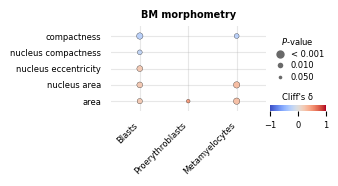

In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "RTK_RAS_mutations",
    modality="BM",
    plot_width=2, plot_height=1.1,
    title="BM morphometry",
    figure_type="supplementary_rtk_ras_bm_morphometry",
)

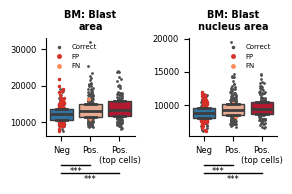

In [ ]:
plot_attention_comparison(
    ["Blasts_entire_area_median",
     "Blasts_nucleus_area_median",
    ],
    df3_bm_rtk_ras,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=3,
    fig_height=2,
    num_columns=2,
    prediction_col="RTK_RAS_mutations_predicted",
    feature_labels={
        "Blasts_entire_area_median": "BM: Blast\narea",
        "Blasts_nucleus_area_median": "BM: Blast\nnucleus area",
    },
)

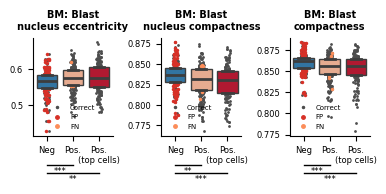

In [ ]:
plot_attention_comparison(
    [
     "Blasts_nucleus_eccentricity_median",
     "Blasts_nucleus_compactness_median",
     "Blasts_entire_compactness_median",
    ],
    df3_bm_rtk_ras,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=4,
    fig_height=2,
    num_columns=3,
    prediction_col="RTK_RAS_mutations_predicted",
    feature_labels={
        "Blasts_nucleus_eccentricity_median": "BM: Blast\nnucleus eccentricity",
        "Blasts_nucleus_compactness_median": "BM: Blast\nnucleus compactness",
        "Blasts_entire_compactness_median": "BM: Blast\ncompactness",
    },
)

#### **RTK-RAS mutations: PB Morphometry**

In [ ]:
get_significant_features("RTK_RAS_mutations", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
522,PB,cell_statistic,Monocytes_nucleus_compactness_median,0.029,0.241
523,PB,cell_statistic,Blasts_nucleus_area_median,0.002,0.259
524,PB,cell_statistic,Blasts_entire_area_median,0.011,0.222


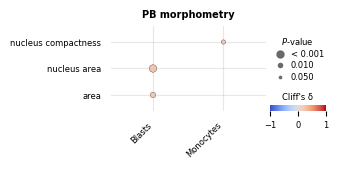

In [ ]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "RTK_RAS_mutations",
    modality="PB",
    plot_width=2, plot_height=1.1,
    title="PB morphometry",
    figure_type="supplementary_rtk_ras_pb_morphometry",
)

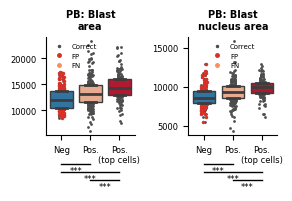

In [ ]:
temp = df3_pb_rtk_ras[df3_pb_rtk_ras["Blasts_entire_area_median"] < 30000]
plot_attention_comparison(
    ["Blasts_entire_area_median",
     "Blasts_nucleus_area_median"],
    temp,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=3,
    fig_height=2,
    num_columns=2,
    prediction_col="RTK_RAS_mutations_predicted",
    feature_labels={
        "Blasts_entire_area_median": "PB: Blast\narea",
        "Blasts_nucleus_area_median": "PB: Blast\nnucleus area",
    },
)

### **Complex karyotype**

In [ ]:
df3_bm_complex_karyotype = build_three_group_df("complex_karyotype", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_complex_karyotype = df3_bm_complex_karyotype.merge(
    df_bm[["database_id", "album_id", "complex_karyotype_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_complex_karyotype = build_three_group_df("complex_karyotype", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_complex_karyotype = df3_pb_complex_karyotype.merge(
    df_pb[["database_id", "album_id", "complex_karyotype_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **Complex karyotype: BM Differentials**

In [ ]:
get_significant_features("complex_karyotype", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
90,BM,cell_differential,Plasma_cells_proportion,0.022,0.210
91,BM,cell_differential,Lymphocytes_proportion,0.001,0.301
92,BM,cell_differential,Basophils_proportion,0.038,0.181
93,BM,cell_differential,Metamyelocytes_proportion,0.045,0.171
94,BM,cell_differential,Myelocytes_proportion,0.038,0.182


/tmp/ipykernel_2157546/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


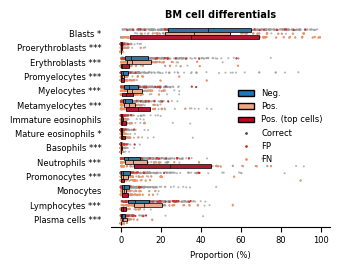

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_complex_karyotype,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="complex_karyotype_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_complex_karyotype_bm_differentials",
    title="BM cell differentials",
)

#### **Complex karyotype: PB Differentials**

In [ ]:
get_significant_features("complex_karyotype", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
450,PB,cell_differential,Plasma_cells_proportion,0.02,0.207
451,PB,cell_differential,Basophils_proportion,0.02,0.209


/tmp/ipykernel_2157546/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


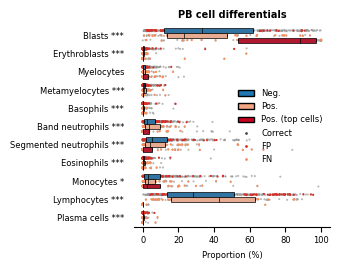

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_complex_karyotype,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="complex_karyotype_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_complex_karyotype_pb_differentials",
    title="PB cell differentials",
)

#### **Complex karyotype: BM Dysplasia**

**NB:** Significant features but none of those are used by the model

In [ ]:
get_significant_features("complex_karyotype", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
152,BM,dysplasia,Lymphocytes-vacuolated_proportion,0.004,0.236
153,BM,dysplasia,Myelocytes-vacuolated_proportion,0.001,0.298
154,BM,dysplasia,Promyelocytes-vacuolated_proportion,0.011,0.315
155,BM,dysplasia,Blasts-vacuolated_proportion,0.004,0.243
156,BM,dysplasia,Megakaryocytes_multinucleated_proportion,0.040,-0.519
157,BM,dysplasia,Myeloid_precursors_bilobed_proportion,0.001,-0.417
158,BM,dysplasia,Myeloid_precursors_hypergranulated_proportion,0.004,-0.230


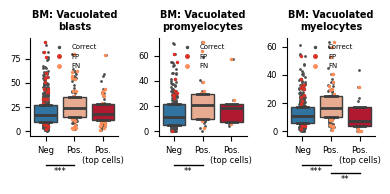

In [ ]:
plot_attention_comparison(
    [
        "Blasts-vacuolated_proportion",
        "Promyelocytes-vacuolated_proportion",
        "Myelocytes-vacuolated_proportion",
    ],
    df3_bm_complex_karyotype,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=4,
    fig_height=2,
    prediction_col="complex_karyotype_predicted",
    feature_labels={
        "Blasts-vacuolated_proportion": "BM: Vacuolated\nblasts",
        "Promyelocytes-vacuolated_proportion": "BM: Vacuolated\npromyelocytes",
        "Myelocytes-vacuolated_proportion": "BM: Vacuolated\nmyelocytes",
    },
)

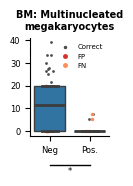

In [ ]:
plot_attention_comparison(
    [
        "Megakaryocytes_multinucleated_proportion",
    ],
    df3_bm_complex_karyotype,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    prediction_col="complex_karyotype_predicted",
    feature_labels={
        "Megakaryocytes_multinucleated_proportion": "BM: Multinucleated\nmegakaryocytes",
    },
)

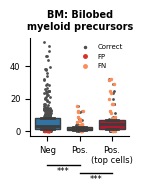

In [ ]:
plot_attention_comparison(
    [
        "Myeloid_precursors_bilobed_proportion",
    ],
    df3_bm_complex_karyotype,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    prediction_col="complex_karyotype_predicted",
    feature_labels={
        "Myeloid_precursors_bilobed_proportion": "BM: Bilobed\nmyeloid precursors",
    },
)

#### **Complex karyotype: PB Dysplasia**

In [ ]:
get_significant_features("complex_karyotype", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


#### **Complex karyotype: BM Morphometry**

In [ ]:
get_significant_features("complex_karyotype", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
322,BM,cell_statistic,Monocytes_nucleus_compactness_median,0.008,0.318
323,BM,cell_statistic,Monocytes_nucleus_solidity_median,0.024,0.264
324,BM,cell_statistic,Promonocytes_nucleus_solidity_median,0.029,0.258
325,BM,cell_statistic,Promonocytes_entire_N:C-ratio_median,0.002,-0.372
326,BM,cell_statistic,Promonocytes_entire_area_median,0.005,0.341
327,BM,cell_statistic,Neutrophils_nucleus_compactness_median,0.017,0.238
328,BM,cell_statistic,Neutrophils_nucleus_solidity_median,0.025,0.220
329,BM,cell_statistic,Eosinophils_immature_nucleus_compactness_median,0.011,0.422
330,BM,cell_statistic,Eosinophils_immature_nucleus_solidity_median,0.004,0.473
331,BM,cell_statistic,Metamyelocytes_entire_compactness_median,0.034,0.205


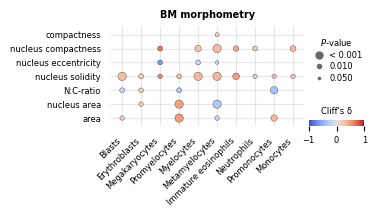

In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "complex_karyotype",
    modality="BM",
    plot_width=2.5, plot_height=1.3,
    title="BM morphometry",
    figure_type="supplementary_complex_karyotype_bm_morphometry",
)

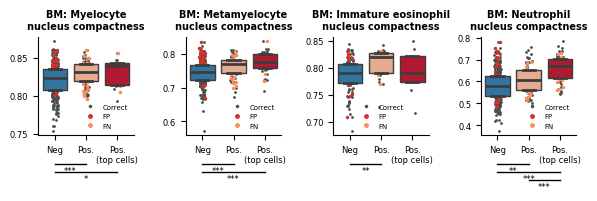

In [ ]:
plot_attention_comparison(
    [
     "Myelocytes_nucleus_compactness_median",
     "Metamyelocytes_nucleus_compactness_median",
     "Eosinophils_immature_nucleus_compactness_median",
     "Neutrophils_nucleus_compactness_median",
    ],
    df3_bm_complex_karyotype,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=6,
    fig_height=2,
    num_columns=4,
    prediction_col="complex_karyotype_predicted",
    feature_labels={
        "Myelocytes_nucleus_compactness_median": "BM: Myelocyte\nnucleus compactness",
        "Metamyelocytes_nucleus_compactness_median": "BM: Metamyelocyte\nnucleus compactness",
        "Eosinophils_immature_nucleus_compactness_median": "BM: Immature eosinophil\nnucleus compactness",
        "Neutrophils_nucleus_compactness_median": "BM: Neutrophil\nnucleus compactness",
    },
)

#### **Complex karyotype: PB Morphometry**

In [ ]:
get_significant_features("complex_karyotype", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
525,PB,cell_statistic,Blasts_nucleus_eccentricity_median,0.046,0.229
526,PB,cell_statistic,Blasts_entire_N:C-ratio_median,0.005,-0.284


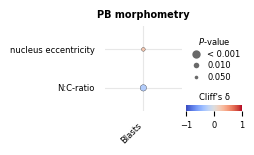

In [ ]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "complex_karyotype",
    modality="PB",
    plot_width=1, plot_height=1.1,
    title="PB morphometry",
    figure_type="supplementary_complex_karyotype_pb_morphometry",
)

### **Monosomy 5 / del(5q)**

In [ ]:
df3_bm_monosomy5 = build_three_group_df("monosomy5_del_5q", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_monosomy5 = df3_bm_monosomy5.merge(
    df_bm[["database_id", "album_id", "monosomy5_del_5q_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_monosomy5 = build_three_group_df("monosomy5_del_5q", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_monosomy5 = df3_pb_monosomy5.merge(
    df_pb[["database_id", "album_id", "monosomy5_del_5q_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **Monosomy 5 / del(5q): BM Differentials**

In [ ]:
get_significant_features("monosomy5_del_5q", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
98,BM,cell_differential,Plasma_cells_proportion,0.001,0.308
99,BM,cell_differential,Lymphocytes_proportion,0.001,0.512
100,BM,cell_differential,Neutrophils_proportion,0.001,0.335
101,BM,cell_differential,Basophils_proportion,0.001,0.388
102,BM,cell_differential,Eosinophils_proportion,0.001,0.417
103,BM,cell_differential,Eosinophils_immature_proportion,0.001,0.339
104,BM,cell_differential,Metamyelocytes_proportion,0.001,0.363
105,BM,cell_differential,Myelocytes_proportion,0.014,0.227
106,BM,cell_differential,Erythroblasts_proportion,0.025,0.206
107,BM,cell_differential,Proerythroblasts_proportion,0.003,0.273


/tmp/ipykernel_2157546/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


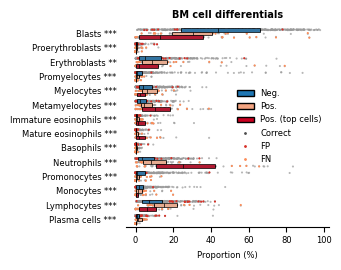

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_monosomy5,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="monosomy5_del_5q_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_monosomy5_bm_differentials",
    title="BM cell differentials",
)

#### **Monosomy 5 / del(5q): PB Differentials**

In [ ]:
get_significant_features("monosomy5_del_5q", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
453,PB,cell_differential,Plasma_cells_proportion,0.040,0.203
454,PB,cell_differential,Lymphocytes_proportion,0.025,0.224
455,PB,cell_differential,Band_neutrophils_proportion,0.002,0.316
456,PB,cell_differential,Basophils_proportion,0.004,0.286
457,PB,cell_differential,Eosinophils_proportion,0.014,0.248
458,PB,cell_differential,Metamyelocytes_proportion,0.002,0.319


/tmp/ipykernel_2157546/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


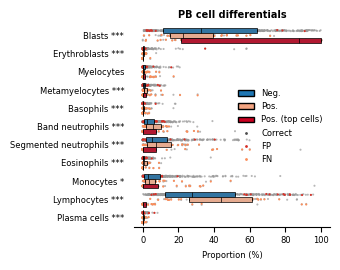

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_monosomy5,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="monosomy5_del_5q_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_monosomy5_pb_differentials",
    title="PB cell differentials",
)

#### **Monosomy 5 / del(5q): BM Dysplasia**

In [ ]:
get_significant_features("monosomy5_del_5q", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
161,BM,dysplasia,Lymphocytes-vacuolated_proportion,0.005,0.297
162,BM,dysplasia,Myelocytes-vacuolated_proportion,0.002,0.330
163,BM,dysplasia,Promyelocytes-vacuolated_proportion,0.025,0.340
164,BM,dysplasia,Erythroblasts-vacuolated_proportion,0.023,0.244
165,BM,dysplasia,Blasts-vacuolated_proportion,0.012,0.264
166,BM,dysplasia,Erythroblasts_dysmorphic_proportion,0.025,0.231
167,BM,dysplasia,Myeloid_precursors_bilobed_proportion,0.001,-0.564
168,BM,dysplasia,Myeloid_precursors_hypergranulated_proportion,0.028,-0.220


#### **Monosomy 5 / del(5q): PB Dysplasia**

In [ ]:
get_significant_features("monosomy5_del_5q", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


#### **Monosomy 5 / del(5q): BM Morphometry**

In [ ]:
get_significant_features("monosomy5_del_5q", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
365,BM,cell_statistic,Monocytes_nucleus_compactness_median,0.002,0.432
366,BM,cell_statistic,Monocytes_nucleus_solidity_median,0.007,0.382
367,BM,cell_statistic,Promonocytes_entire_N:C-ratio_median,0.002,-0.481
368,BM,cell_statistic,Promonocytes_entire_area_median,0.001,0.526
369,BM,cell_statistic,Neutrophils_nucleus_compactness_median,0.006,0.309
370,BM,cell_statistic,Neutrophils_nucleus_solidity_median,0.005,0.317
371,BM,cell_statistic,Basophils_entire_compactness_median,0.020,-0.579
372,BM,cell_statistic,Eosinophils_immature_nucleus_compactness_median,0.018,0.392
373,BM,cell_statistic,Eosinophils_immature_nucleus_eccentricity_median,0.047,-0.332
374,BM,cell_statistic,Eosinophils_immature_nucleus_solidity_median,0.020,0.385


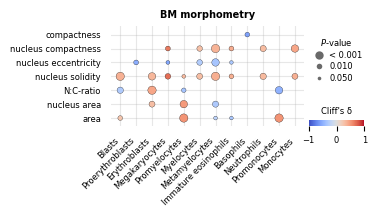

In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "monosomy5_del_5q",
    modality="BM",
    plot_width=2.5, plot_height=1.3,
    title="BM morphometry",
    figure_type="supplementary_monosomy5_bm_morphometry",
)

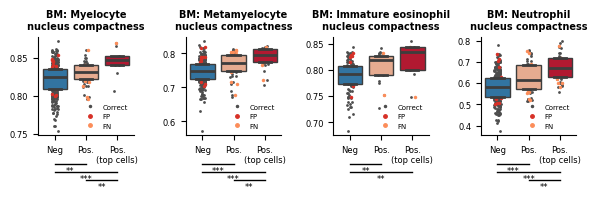

In [ ]:
plot_attention_comparison(
    [
     "Myelocytes_nucleus_compactness_median",
     "Metamyelocytes_nucleus_compactness_median",
     "Eosinophils_immature_nucleus_compactness_median",
     "Neutrophils_nucleus_compactness_median",
    ],
    df3_bm_monosomy5,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=6,
    fig_height=2,
    num_columns=4,
    prediction_col="monosomy5_del_5q_predicted",
    feature_labels={
        "Myelocytes_nucleus_compactness_median": "BM: Myelocyte\nnucleus compactness",
        "Metamyelocytes_nucleus_compactness_median": "BM: Metamyelocyte\nnucleus compactness",
        "Eosinophils_immature_nucleus_compactness_median": "BM: Immature eosinophil\nnucleus compactness",
        "Neutrophils_nucleus_compactness_median": "BM: Neutrophil\nnucleus compactness",
    },
)

#### **Monosomy 5 / del(5q): PB Morphometry**

In [ ]:
get_significant_features("monosomy5_del_5q", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
528,PB,cell_statistic,Monocytes_nucleus_area_median,0.001,-0.502
529,PB,cell_statistic,Eosinophils_nucleus_area_median,0.024,-0.479
530,PB,cell_statistic,Blasts_entire_N:C-ratio_median,0.002,-0.363


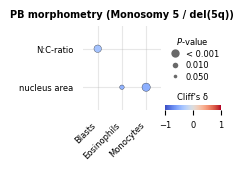

In [ ]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "monosomy5_del_5q",
    modality="PB",
    plot_width=1, plot_height=1.1,
    title="PB morphometry (Monosomy 5 / del(5q))",
    figure_type="supplementary_monosomy5",
)

### **TP53**

In [ ]:
df3_bm_tp53 = build_three_group_df("TP53", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_tp53 = df3_bm_tp53.merge(
    df_bm[["database_id", "album_id", "TP53_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_tp53 = build_three_group_df("TP53", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_tp53 = df3_pb_tp53.merge(
    df_pb[["database_id", "album_id", "TP53_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **TP53: BM Differentials**

In [ ]:
get_significant_features("TP53", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
109,BM,cell_differential,Plasma_cells_proportion,0.001,0.417
110,BM,cell_differential,Lymphocytes_proportion,0.005,0.329
111,BM,cell_differential,Neutrophils_proportion,0.016,0.262
112,BM,cell_differential,Basophils_proportion,0.005,0.335
113,BM,cell_differential,Eosinophils_proportion,0.005,0.323
114,BM,cell_differential,Eosinophils_immature_proportion,0.006,0.315
115,BM,cell_differential,Metamyelocytes_proportion,0.006,0.308
116,BM,cell_differential,Erythroblasts_proportion,0.007,0.301
117,BM,cell_differential,Proerythroblasts_proportion,0.001,0.443
118,BM,cell_differential,Blasts_proportion,0.012,-0.278


/tmp/ipykernel_2157546/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


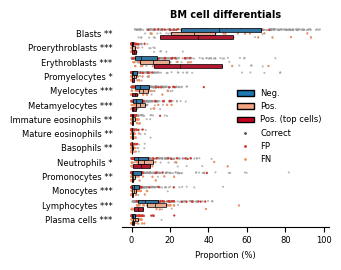

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_tp53,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="TP53_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_tp53_bm_differentials",
    title="BM cell differentials",
)

#### **TP53: PB Differentials**

In [ ]:
get_significant_features("TP53", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
459,PB,cell_differential,Plasma_cells_proportion,0.037,0.257
460,PB,cell_differential,Band_neutrophils_proportion,0.024,0.283
461,PB,cell_differential,Basophils_proportion,0.024,0.298
462,PB,cell_differential,Metamyelocytes_proportion,0.024,0.289


/tmp/ipykernel_2157546/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


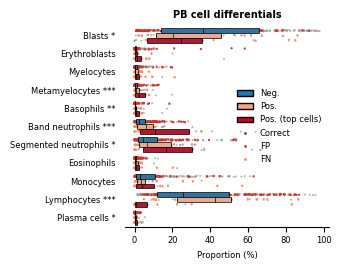

In [ ]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_tp53,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="TP53_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_tp53_pb_differentials",
    title="PB cell differentials",
)

#### **TP53: BM Dysplasia**

In [ ]:
get_significant_features("TP53", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
169,BM,dysplasia,Lymphocytes-vacuolated_proportion,0.041,0.263
170,BM,dysplasia,Neutrophils-vacuolated_proportion,0.044,0.262
171,BM,dysplasia,Myelocytes-vacuolated_proportion,0.001,0.398
172,BM,dysplasia,Promyelocytes-vacuolated_proportion,0.001,0.592
173,BM,dysplasia,Blasts-vacuolated_proportion,0.001,0.386
174,BM,dysplasia,Megakaryocytes_hypolobated_proportion,0.042,0.688
175,BM,dysplasia,Myeloid_precursors_bilobed_proportion,0.022,-0.292


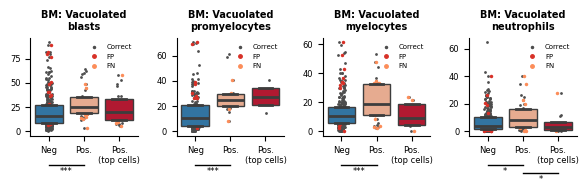

In [ ]:
plot_attention_comparison(
    [
        "Blasts-vacuolated_proportion",
        "Promyelocytes-vacuolated_proportion",
        "Myelocytes-vacuolated_proportion",
        "Neutrophils-vacuolated_proportion",
    ],
    df3_bm_tp53,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=6,
    fig_height=2,
    prediction_col="TP53_predicted",
    feature_labels={
        "Blasts-vacuolated_proportion": "BM: Vacuolated\nblasts",
        "Promyelocytes-vacuolated_proportion": "BM: Vacuolated\npromyelocytes",
        "Myelocytes-vacuolated_proportion": "BM: Vacuolated\nmyelocytes",
        "Neutrophils-vacuolated_proportion": "BM: Vacuolated\nneutrophils",
    },
)

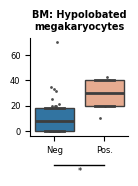

In [ ]:
plot_attention_comparison(
    [
        "Megakaryocytes_hypolobated_proportion",
    ],
    df3_bm_tp53,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    prediction_col="complex_TP53_predicted",
    feature_labels={
        "Megakaryocytes_hypolobated_proportion": "BM: Hypolobated\nmegakaryocytes",
    },
)

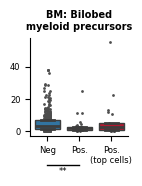

In [ ]:
plot_attention_comparison(
    [
        "Myeloid_precursors_bilobed_proportion",
    ],
    df3_bm_tp53,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    prediction_col="complex_TP53_predicted",
    feature_labels={
        "Myeloid_precursors_bilobed_proportion": "BM: Bilobed\nmyeloid precursors",
    },
)

#### **TP53: PB Dysplasia**

In [ ]:
get_significant_features("TP53", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


#### **TP53: BM Morphometry**

In [ ]:
get_significant_features("TP53", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
398,BM,cell_statistic,Promonocytes_entire_area_median,0.031,0.469
399,BM,cell_statistic,Promyelocytes_entire_N:C-ratio_median,0.013,-0.508
400,BM,cell_statistic,Promyelocytes_nucleus_area_median,0.001,0.653
401,BM,cell_statistic,Promyelocytes_entire_area_median,0.001,0.681
402,BM,cell_statistic,Erythroblasts_nucleus_solidity_median,0.013,0.355
403,BM,cell_statistic,Erythroblasts_entire_N:C-ratio_median,0.013,0.358
404,BM,cell_statistic,Erythroblasts_nucleus_area_median,0.047,0.305
405,BM,cell_statistic,Blasts_nucleus_area_median,0.002,0.414
406,BM,cell_statistic,Blasts_entire_area_median,0.003,0.399


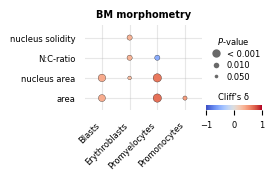

In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "TP53",
    modality="BM",
    plot_width=1.5, plot_height=1.1,
    title="BM morphometry",
    figure_type="supplementary_tp53_bm_morphometry",
)

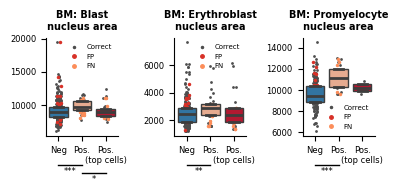

In [ ]:
plot_attention_comparison(
    [
        "Blasts_nucleus_area_median",
        "Erythroblasts_nucleus_area_median",
        "Promyelocytes_nucleus_area_median",
    ],
    df3_bm_tp53,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=4,
    fig_height=2,
    prediction_col="TP53_predicted",
    feature_labels={
        "Blasts_nucleus_area_median": "BM: Blast\nnucleus area",
        "Erythroblasts_nucleus_area_median": "BM: Erythroblast\nnucleus area",
        "Promyelocytes_nucleus_area_median": "BM: Promyelocyte\nnucleus area",
    },
)

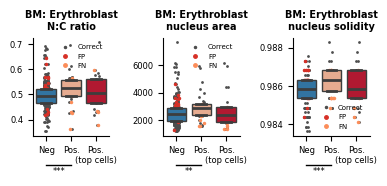

In [ ]:
plot_attention_comparison(
    [
        "Erythroblasts_entire_N:C-ratio_median",
        "Erythroblasts_nucleus_area_median",
        "Erythroblasts_nucleus_solidity_median",
    ],
    df3_bm_tp53,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=4,
    fig_height=2,
    prediction_col="TP53_predicted",
    feature_labels={
        "Erythroblasts_entire_N:C-ratio_median": "BM: Erythroblast\nN:C ratio",
        "Erythroblasts_nucleus_area_median": "BM: Erythroblast\nnucleus area",
        "Erythroblasts_nucleus_solidity_median": "BM: Erythroblast\nnucleus solidity",
    },
)

#### **TP53: PB Morphometry**

In [ ]:
get_significant_features("TP53", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC


In [ ]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "TP53",
    modality="PB",
    plot_width=4, plot_height=3,
    title="PB morphometry (TP53)",
    figure_type="supplementary_tp53",
)

No significant morphometry associations for TP53 (PB)


### **STAG2**

In [163]:
df3_bm_stag2 = build_three_group_df("STAG2", df_bm, df_attn_bm, cell_df_bm,
    aggregate_bm_dataset, post_process_fn=lambda df: pre_process_bone_marrow_data(df)[0])
df3_bm_stag2 = df3_bm_stag2.merge(
    df_bm[["database_id", "album_id", "STAG2_predicted"]],
    on=["database_id", "album_id"], how="left"
)

df3_pb_stag2 = build_three_group_df("STAG2", df_pb, df_attn_pb, cell_df_pb,
    aggregate_pb_dataset, post_process_fn=lambda df: pre_process_peripheral_blood_data(df)[0])
df3_pb_stag2 = df3_pb_stag2.merge(
    df_pb[["database_id", "album_id", "STAG2_predicted"]],
    on=["database_id", "album_id"], how="left"
)

#### **STAG2: BM Differentials**

In [ ]:
get_significant_features("STAG2", modality="BM", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC
119,BM,cell_differential,Promonocytes_proportion,0.046,-0.302
120,BM,cell_differential,Neutrophils_proportion,0.007,0.395
121,BM,cell_differential,Metamyelocytes_proportion,0.001,0.565
122,BM,cell_differential,Myelocytes_proportion,0.001,0.635
123,BM,cell_differential,Erythroblasts_proportion,0.001,0.483
124,BM,cell_differential,Proerythroblasts_proportion,0.001,0.528
125,BM,cell_differential,Blasts_proportion,0.007,-0.402


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


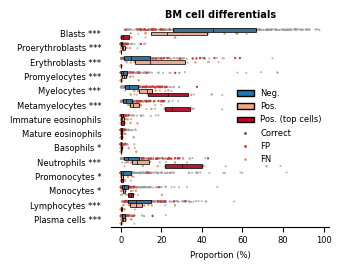

In [164]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_BM.keys()),
    df3_bm_stag2,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="STAG2_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_BM,
    figure_type="supplementary_stag2_bm_differentials",
    title="BM cell differentials",
)

#### **STAG2: PB Differentials**

In [ ]:
get_significant_features("STAG2", modality="PB", feature_type="cell_differential")

,modality,feature_type,cont_col,p-value,Log10_FC


/tmp/ipykernel_2190882/1413810752.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


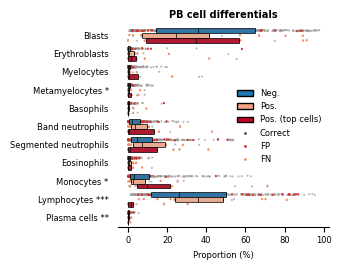

In [165]:
plot_attention_cell_differentials(
    list(CELL_DIFF_VARIABLE_NAMES_PB.keys()),
    df3_pb_stag2,
    xlabel="Proportion (%)",
    fig_width=3.5,
    fig_height=2.8,
    prediction_col="STAG2_predicted",
    feature_labels=CELL_DIFF_VARIABLE_NAMES_PB,
    figure_type="supplementary_stag2_pb_differentials",
    title="PB cell differentials",
)

#### **STAG2: BM Dysplasia**

In [ ]:
get_significant_features("STAG2", modality="BM", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC
176,BM,dysplasia,Myeloid_precursors_bilobed_proportion,0.001,-0.654


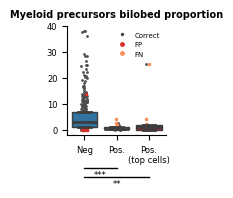

In [167]:
plot_attention_comparison(
    ["Myeloid_precursors_bilobed_proportion"],
    df3_bm_stag2,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    prediction_col="STAG2_predicted",
)

#### **STAG2: PB Dysplasia**

In [ ]:
get_significant_features("STAG2", modality="PB", feature_type="dysplasia")

,modality,feature_type,cont_col,p-value,Log10_FC


#### **STAG2: BM Morphometry**

In [ ]:
get_significant_features("STAG2", modality="BM", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC


In [ ]:
plot_mutation_morphometry_balloon(
    bm_cell_stat_stats, "STAG2",
    modality="BM",
    plot_width=4, plot_height=3,
    title="BM morphometry (STAG2)",
    figure_type="supplementary_stag2",
)

No significant morphometry associations for STAG2 (BM)


#### **STAG2: PB Morphometry**

In [ ]:
get_significant_features("STAG2", modality="PB", feature_type="cell_statistic")

,modality,feature_type,cont_col,p-value,Log10_FC
531,PB,cell_statistic,Monocytes_nucleus_area_median,0.011,-0.579


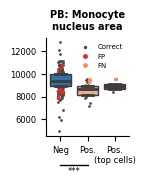

In [169]:
temp = df3_pb_stag2[df3_pb_stag2["Monocytes_nucleus_area_median"] < 30000]

plot_attention_comparison(
    ["Monocytes_nucleus_area_median"],
    temp,
    ylabel="",
    wt_label="Neg",
    mut_label="Pos.",
    fig_width=1.5,
    fig_height=2,
    prediction_col="STAG2_predicted",
    feature_labels={"Monocytes_nucleus_area_median": "PB: Monocyte\nnucleus area"},
)

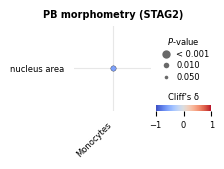

In [170]:
plot_mutation_morphometry_balloon(
    pb_cell_stat_stats, "STAG2",
    modality="PB",
    plot_width=1, plot_height=1.1,
    title="PB morphometry (STAG2)",
    figure_type="supplementary_stag2",
)

# **Supplementary Figure 3 - Model error analysis**

## **i) Oncorpint of false positives**

### Bone marrow

562 3


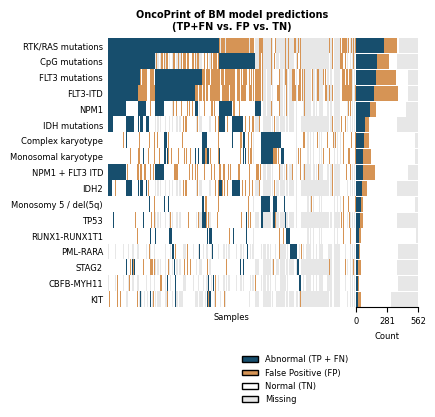

In [ ]:
df = build_oncoprint_data_from_predictions(df_bm, pred_suffix="_predicted", mode="POS_FP_TN", pos_label=1, neg_label=0)

oncoprint(
    df,
    category_colors={
        "POS": "#174E6D",
        "FP": "#D69455",
        "TN": "#ffffff",
    },
    category_names={
        "POS": "Abnormal (TP + FN)",
        "FP": "False Positive (FP)",
        "TN": "Normal (TN)",
        "NaN": "Missing",
    },
    order_by="POS",
    missing_label="NaN",
    missing_color="#E7E7E7",
    figsize=(4, 3.5),
    order_samples=True,
    order_features=True,
    highlight_feature=None,
    highlight_color="tab:red",
    title="OncoPrint of BM model predictions\n(TP+FN vs. FP vs. TN)",
    xlabel="Samples",
    ylabel="",
    num_xticks=3,
)


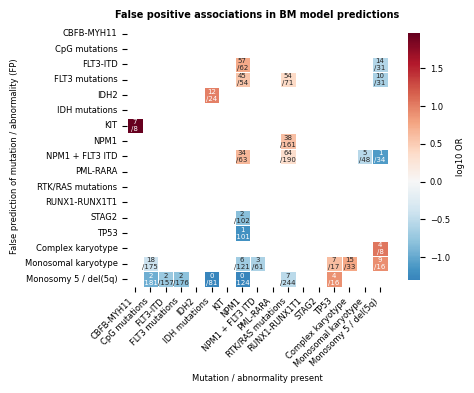

In [ ]:
fp_results = mutation_error_association(df_bm, SELECTED_VARIABLES_IN_ORDER, mode="FP")
#fp_results = fp_results[fp_results["p_adj"] < 0.05]

plot_mutation_error_heatmap(
    fp_results,
    figsize=(4, 4),
    xlabel="Mutation / abnormality present",
    ylabel="False prediction of mutation / abnormality (FP)",
    title="False positive associations in BM model predictions",
)

### Peripheral blood

562 3


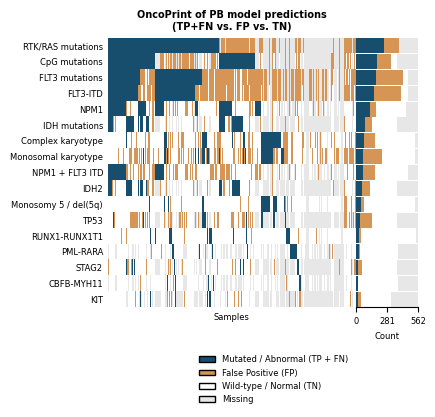

In [ ]:
df = build_oncoprint_data_from_predictions(df_pb, pred_suffix="_predicted", mode="POS_FP_TN", pos_label=1, neg_label=0)

oncoprint(
    df,
    category_colors={
        "POS": "#174E6D",
        "FP": "#D69455",
        "TN": "#ffffff",
    },
    category_names={
        "POS": "Mutated / Abnormal (TP + FN)",
        "FP": "False Positive (FP)",
        "TN": "Wild-type / Normal (TN)",
        "NaN": "Missing",
    },
    order_by="POS",
    missing_label="NaN",
    missing_color="#E7E7E7",
    figsize=(4, 3.5),
    order_samples=True,
    order_features=True,
    highlight_feature=None,
    highlight_color="tab:red",
    title="OncoPrint of PB model predictions\n(TP+FN vs. FP vs. TN)",
    xlabel="Samples",
    ylabel="",
    num_xticks=3,
)


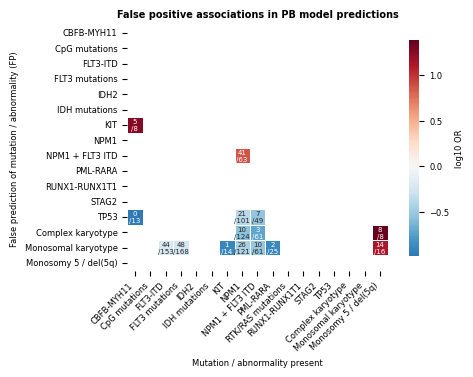

In [ ]:
fp_results = mutation_error_association(df_pb, SELECTED_VARIABLES_IN_ORDER, mode="FP")
#fp_results = fp_results[fp_results["p_adj"] < 0.05]

plot_mutation_error_heatmap(
    fp_results,
    figsize=(4, 3.5),
    xlabel="Mutation / abnormality present",
    ylabel="False prediction of mutation / abnormality (FP)",
    title="False positive associations in PB model predictions",
)

## **i) Oncorpint of false negatives**

### Bone marrow

562 3


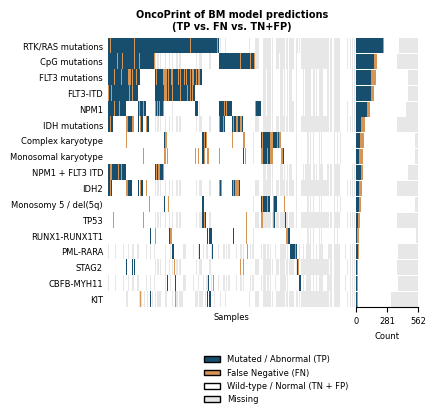

In [ ]:
df = build_oncoprint_data_from_predictions(df_bm, pred_suffix="_predicted", mode="TP_FN_NEG", pos_label=1, neg_label=0)

oncoprint(
    df,
    category_colors={
        "TP": "#174E6D",
        "FN": "#D69455",
        "NEG": "#ffffff",
    },
    category_names={
        "TP": "Mutated / Abnormal (TP)",
        "FN": "False Negative (FN)",
        "NEG": "Wild-type / Normal (TN + FP)",
        "NaN": "Missing",
    },
    order_by=["TP", "FN"],
    missing_label="NaN",
    missing_color="#E7E7E7",
    figsize=(4, 3.5),
    order_samples=True,
    order_features=True,
    highlight_feature=None,
    highlight_color="tab:red",
    title="OncoPrint of BM model predictions\n(TP vs. FN vs. TN+FP)",
    xlabel="Samples",
    ylabel="",
    num_xticks=3,
)


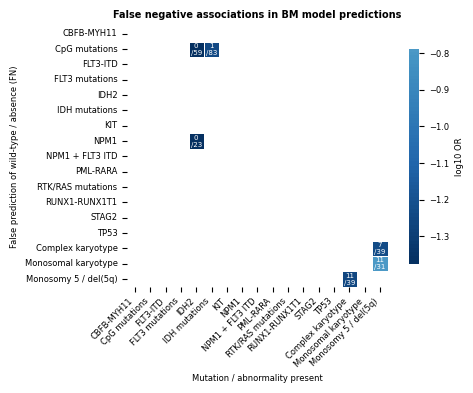

In [ ]:
fn_results = mutation_error_association(df_bm, SELECTED_VARIABLES_IN_ORDER, mode="FN")
#fn_results = fn_results[fn_results["p_adj"] < 0.05]

plot_mutation_error_heatmap(
    fn_results,
    figsize=(4, 3.5),
    xlabel="Mutation / abnormality present",
    ylabel="False prediction of wild-type / absence (FN)",
    title="False negative associations in BM model predictions",
)

### Peripheral blood

562 3


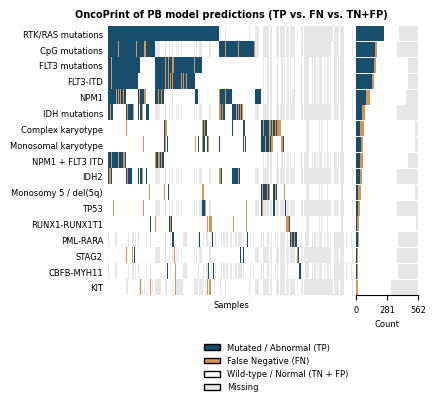

In [ ]:
df = build_oncoprint_data_from_predictions(df_pb, pred_suffix="_predicted", mode="TP_FN_NEG", pos_label=1, neg_label=0)

oncoprint(
    df,
    category_colors={
        "TP": "#174E6D",
        "FN": "#D69455",
        "NEG": "#ffffff",
    },
    category_names={
        "TP": "Mutated / Abnormal (TP)",
        "FN": "False Negative (FN)",
        "NEG": "Wild-type / Normal (TN + FP)",
        "NaN": "Missing",
    },
    order_by=["TP", "FN"],
    missing_label="NaN",
    missing_color="#E7E7E7",
    figsize=(4, 3.5),
    order_samples=True,
    order_features=True,
    highlight_feature=None,
    highlight_color="tab:red",
    title="OncoPrint of PB model predictions (TP vs. FN vs. TN+FP)",
    xlabel="Samples",
    ylabel="",
    num_xticks=3,
)


/home/mikkop/projects/mut-pred-analysis/.venv/lib/python3.12/site-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/home/mikkop/projects/mut-pred-analysis/.venv/lib/python3.12/site-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


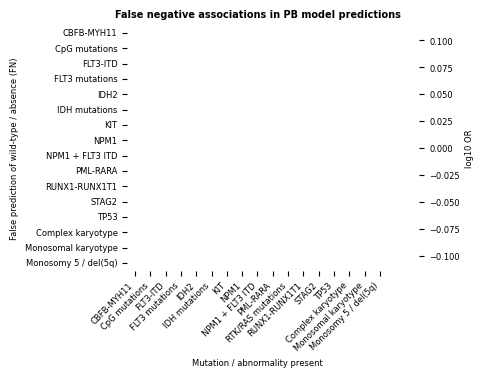

In [ ]:
fn_results = mutation_error_association(df_pb, SELECTED_VARIABLES_IN_ORDER, mode="FN")
#fn_results = fn_results[fn_results["p_adj"] < 0.05]

plot_mutation_error_heatmap(
    fn_results,
    figsize=(4, 3.5),
    xlabel="Mutation / abnormality present",
    ylabel="False prediction of wild-type / absence (FN)",
    title="False negative associations in PB model predictions",
)

## **Other mutations**

In [ ]:
label_map = json.load(open(LABEL_MAP_PATH_BM))
others = sorted(k for k in label_map if k not in SELECTED_VARIABLES)

print(f"Variables in label map not in SELECTED_VARIABLES ({len(others)}):")


Variables in label map not in SELECTED_VARIABLES (35):


In [ ]:
from core.utils import get_other_variables
OTHER_VARIABLES = get_other_variables(
    LABEL_MAP_PATH_BM,
    SELECTED_VARIABLES,
    exclude=['FLT3_ITD', 'KMT2A_rearrangement', 'TP53_OR_monosomy17_del_17p'],
)

# Load BM extra labels (label_map uses different internal key names)
_label_map = json.load(open(LABEL_MAP_PATH_BM))
_labels_bm = pd.read_excel(LABEL_DATA_PATH_BM)
_labels_bm = get_target_labels(_labels_bm, _label_map, OTHER_VARIABLES)
_labels_bm = _labels_bm[["album_id", "database_id"] + OTHER_VARIABLES]

df_bm_other = df_bm.merge(_labels_bm, on=["album_id", "database_id"], how="inner")

# Load PB extra labels
_labels_pb = pd.read_excel(LABEL_DATA_PATH_PB)
_label_map_pb = json.load(open(LABEL_MAP_PATH_PB))
_labels_pb = get_target_labels(_labels_pb, _label_map_pb, OTHER_VARIABLES)
_labels_pb = _labels_pb[["album_id", "database_id"] + OTHER_VARIABLES]

df_pb_other = df_pb.merge(_labels_pb, on=["album_id", "database_id"], how="inner")


### **Other mutations - Cell differentials**

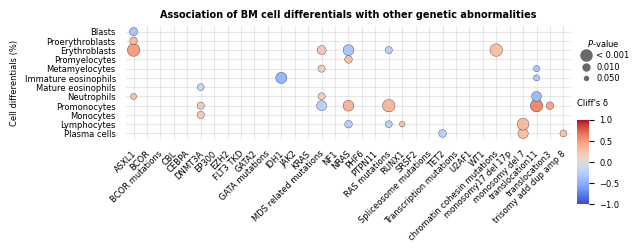

In [ ]:
_bm_diff_vars = sort_features(get_bm_cell_differential_variables(), CELL_LINEAGE_ORDER_BM, CELL_STATISTIC_ORDER)

_, _  = plot_balloon_plot(
    df=df_bm_other,
    cat_vars={v: get_readable_variable_name(v) for v in OTHER_VARIABLES},
    cont_vars={v: get_readable_variable_name(v) for v in _bm_diff_vars},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=3,
    plot_width=8,
    scale_factor=3,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=8,
    title="Association of BM cell differentials with other genetic abnormalities",
    ylabel="Cell differentials (%)",
)


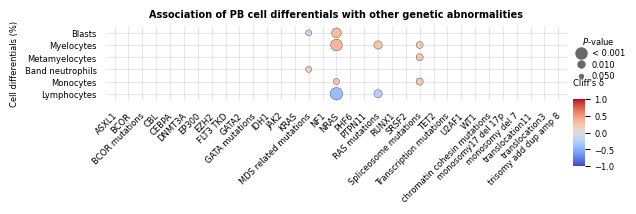

In [ ]:
_, _  = plot_balloon_plot(
    df=df_pb_other,
    cat_vars={v: get_readable_variable_name(v) for v in OTHER_VARIABLES},
    cont_vars={v: get_readable_variable_name(v) for v in sort_features_by_lineage(get_pb_cell_differential_variables(), CELL_LINEAGE_ORDER_PB)},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=2.5,
    plot_width=8,
    scale_factor=3,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=7,
    cbar_width=0.02,
    title="Association of PB cell differentials with other genetic abnormalities",
    ylabel="Cell differentials (%)",
)


### **Other mutations - Morphometry**

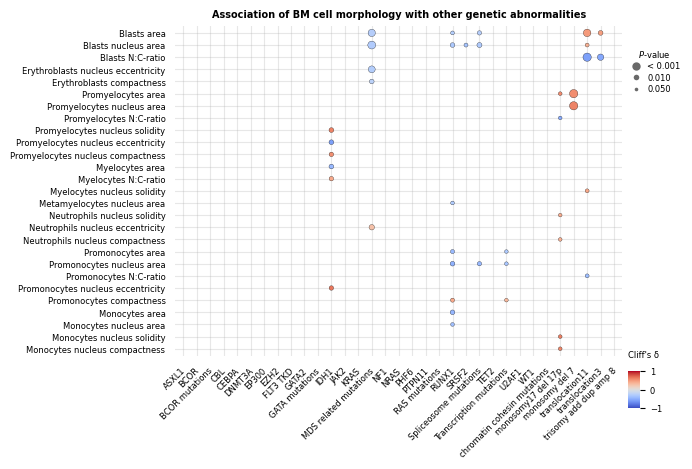

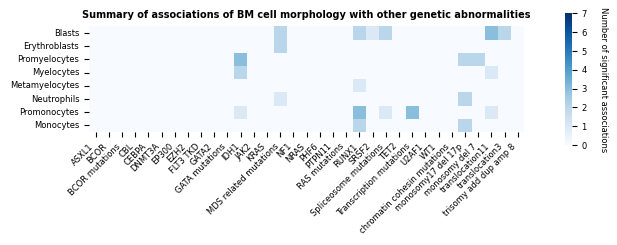

<Axes: title={'center': 'Summary of associations of BM cell morphology with other genetic abnormalities'}>

In [ ]:
_bm_stat_vars = sort_features(cell_statistic_variables_bm, CELL_LINEAGE_ORDER_BM, CELL_STATISTIC_ORDER)

_, _bm_stat_data = plot_balloon_plot(
    df=df_bm_other,
    cat_vars={v: get_readable_variable_name(v) for v in OTHER_VARIABLES},
    cont_vars={v: get_human_readable_cell_statistic_variable(v) for v in _bm_stat_vars},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=7,
    plot_width=10,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=80,
    title="Association of BM cell morphology with other genetic abnormalities",
)

matrix = create_cell_statistic_summary_matrix(
    df=_bm_stat_data,
    cell_types=[get_readable_variable_name(k) for k in CELL_DIFF_VARIABLE_NAMES_BM.keys()],
    variable_order=OTHER_VARIABLES,
    readable_variable_func=get_readable_variable_name,
    max_p_value=0.05,
)
plot_cell_statistic_summary(
    matrix=matrix,
    figsize=(8, 3),
    cbar_shrink=0.8,
    vmin=0,
    vmax=7,
    title="Summary of associations of BM cell morphology with other genetic abnormalities",
)


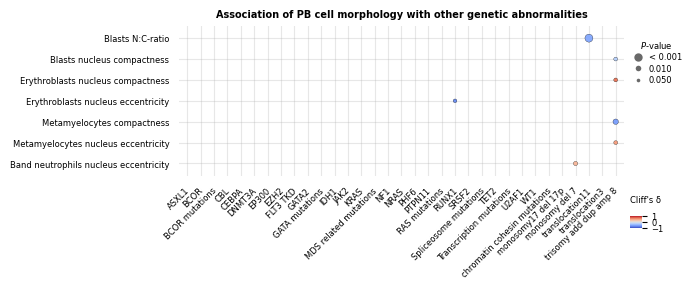

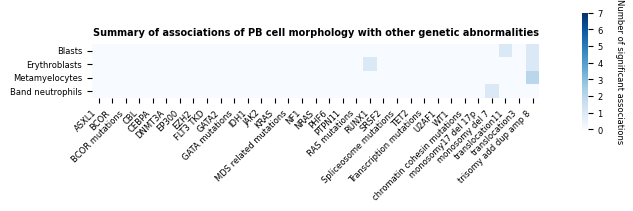

<Axes: title={'center': 'Summary of associations of PB cell morphology with other genetic abnormalities'}>

In [ ]:
_pb_stat_vars = sort_features_by_lineage(cell_statistic_variables_pb, CELL_LINEAGE_ORDER_PB)

_, _pb_stat_data = plot_balloon_plot(
    df=df_pb_other,
    cat_vars={v: get_readable_variable_name(v) for v in OTHER_VARIABLES},
    cont_vars={v: get_human_readable_cell_statistic_variable(v) for v in _pb_stat_vars},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=4,
    plot_width=10,
    scale_factor=2,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=80,
    title="Association of PB cell morphology with other genetic abnormalities",
)

matrix = create_cell_statistic_summary_matrix(
    df=_pb_stat_data,
    cell_types=[get_readable_variable_name(k) for k in CELL_DIFF_VARIABLE_NAMES_PB.keys()],
    variable_order=OTHER_VARIABLES,
    readable_variable_func=get_readable_variable_name,
    max_p_value=0.05,
)
plot_cell_statistic_summary(
    matrix=matrix,
    figsize=(10, 3),
    cbar_shrink=0.8,
    vmin=0,
    vmax=7,
    title="Summary of associations of PB cell morphology with other genetic abnormalities",
)


### **Other mutations - Dysplasia**

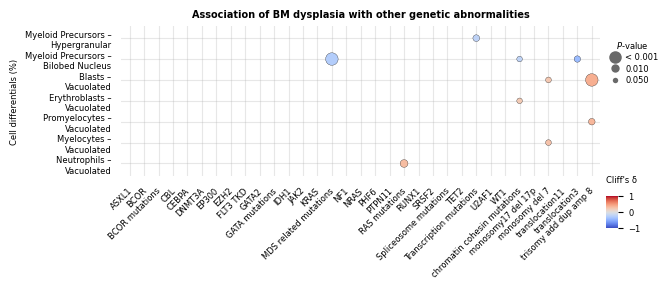

In [ ]:
_, _ = plot_balloon_plot(
    df=df_bm_other,
    cat_vars={v: get_readable_variable_name(v) for v in OTHER_VARIABLES},
    cont_vars={v: get_human_readable_bm_dysplasia_variable(v) for v in SELECTED_BM_DYSPLASIA_VARIABLES[::-1]},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=4,
    plot_width=10,
    scale_factor=3,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=30,
    title="Association of BM dysplasia with other genetic abnormalities",
    ylabel="Cell differentials (%)",
)


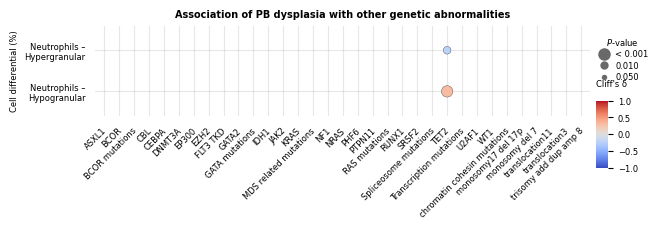

In [ ]:
_, _  = plot_balloon_plot(
    df=df_pb_other,
    cat_vars={v: get_readable_variable_name(v) for v in OTHER_VARIABLES},
    cont_vars={v: get_human_readable_pb_dysplasia_variable(v) for v in SELECTED_PB_DYSPLASIA_VARIABLES},
    max_pvalue=0.05,
    adjust_p_values=True,
    plot_height=3,
    plot_width=10,
    scale_factor=3,
    swap_axes=True,
    sort_by_pvalue=False,
    cbar_divider=8,
    title="Association of PB dysplasia with other genetic abnormalities",
    ylabel="Cell differential (%)",
)


## **HEHR-AML Validation**

#### **Hehr AML - Cell differentials**

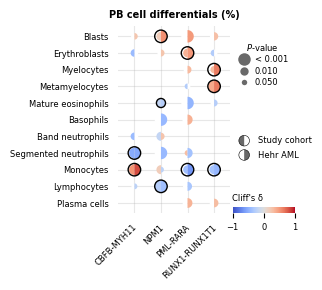

In [ ]:
plot_comparison_balloon_plot(
    df1=df_pb,
    df2=df_hehr,
    cat_vars={v: get_readable_variable_name(v) for v in label_columns_hehr},
    cont_vars={v: get_readable_variable_name(v) for v in sort_features_by_lineage(get_pb_cell_differential_variables(), CELL_LINEAGE_ORDER_PB)},
    label1="Study cohort",
    label2="Hehr AML",
    adjust_p_values_1=True,
    adjust_p_values_2=False,
    swap_axes=False,
    plot_height=3,
    plot_width=2.5,
    scale_factor=3,
    title="PB cell differentials (%)",
    legend_below=False,
    cbar_width=0.25,
    cbar_height=0.02,
    marker_mode="split",
    figure_type="supplementary_cell_differential_validation_hehr_aml",
)

#### **Hehr AML - Dysplasia**

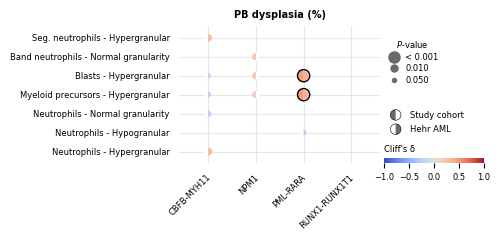

In [ ]:
dysplasia_variables_ordered = sort_features_by_lineage(cell_dysplasia_variables_hehr, CELL_LINEAGE_ORDER_PB)

plot_comparison_balloon_plot(
    df1=df_pb,
    df2=df_hehr,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_hehr},
    cont_vars={variable: get_human_readable_pb_dysplasia_variable(variable, split_into_two_lines=False) for variable in dysplasia_variables_ordered[::-1]},
    label1="Study cohort",
    label2="Hehr AML",
    adjust_p_values_1=True,
    adjust_p_values_2=False,
    swap_axes=False,
    plot_height=2.5,
    plot_width=4,
    scale_factor=3,
    title="PB dysplasia (%)",
    legend_below=False,
    cbar_width=0.25,
    cbar_height=0.02,
    marker_mode="split",
    figure_type="supplementary_dysplasia_validation_hehr_aml",
)

#### **Hehr AML - Morphometry**

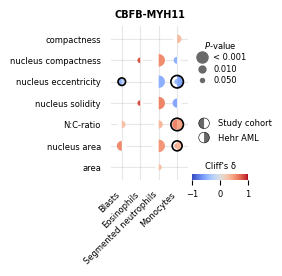

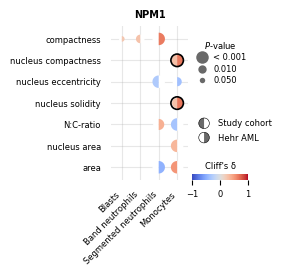

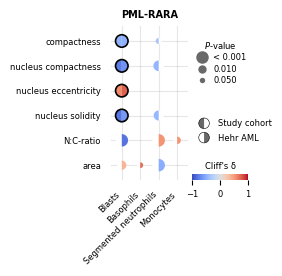

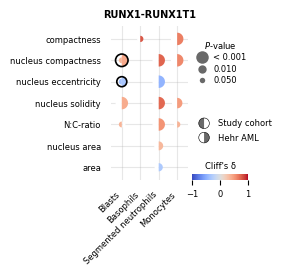

In [ ]:
cell_statistic_variables_ordered = sort_features_by_lineage(cell_statistic_variables_hehr, CELL_LINEAGE_ORDER_PB)
cont_vars_morphometry = {v: get_human_readable_cell_statistic_variable(v) for v in cell_statistic_variables_ordered}

cell_statistic_stats_hehr = calculate_foldchange_pvalue(
    df=df_hehr,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_hehr},
    cont_vars=cont_vars_morphometry,
    max_pvalue=0.05,
    adjust_p_values=False,
    effect_size='cliffs_delta',
)

cell_statistic_stats_pb = calculate_foldchange_pvalue(
    df=df_pb,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_hehr},
    cont_vars=cont_vars_morphometry,
    max_pvalue=0.05,
    adjust_p_values=True,
    effect_size='cliffs_delta',
)

for variable in label_columns_hehr:
    plot_comparison_mutation_morphometry_balloon(
        stats1=cell_statistic_stats_pb,
        stats2=cell_statistic_stats_hehr,
        variable=variable,
        label1="Study cohort",
        label2="Hehr AML",
        modality="PB",
        plot_width=1, 
        plot_height=2,
        title=get_readable_variable_name(variable),
        effect_size='cliffs_delta',
        figure_type=f"supplementary_morphometry_validation_hehr_aml_{variable}",
    )


## **Finland Validation**

In [ ]:
LABEL_DATA_PATH_VENEX = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/venex_bm_samples_07-04-2026.xlsx"
FEATURE_DATA_PATH_VENEX = "data/aggregated_features_venex_bm_07-04-2026.csv"
VENEX_VARIABLES = [
    "NPM1",
    "STAG2",
    "KIT",
    "IDH2",
    "TP53",
]


def load_and_process_venex_bm_data():
    # Load label data
    labels = pd.read_excel(LABEL_DATA_PATH_VENEX)
    print(f"Total Venetoclax BM samples in label data: {len(labels)}")

    label_map = json.load(open(LABEL_MAP_PATH_BM, "r"))

    # Rename anonymized columns to original label names; include all available variables
    labels = get_target_labels(labels, label_map, include_variables=VENEX_VARIABLES)
    label_column_names = [c for c in labels.columns if c not in ["subject_id", "album_id", "database_id"]]

    # Load and pre-process feature data
    features = pd.read_csv(FEATURE_DATA_PATH_VENEX)
    features, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables = pre_process_bone_marrow_data(features)

    # Combine labels and features
    df = pd.merge(labels, features, on=["album_id", "database_id"], how="inner")

    print(f"Total Venetoclax BM samples with valid feature data: {len(df)}")

    return df, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables, label_column_names


df_venex, cell_diff_variables_venex, cell_dysplasia_variables_venex, cell_statistic_variables_venex, label_columns_venex = load_and_process_venex_bm_data()

Total Venetoclax BM samples in label data: 90
Total Venetoclax BM samples with valid feature data: 90


#### **Finland - Cell differentials**

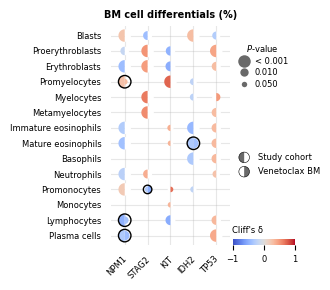

In [ ]:
plot_comparison_balloon_plot(
    df1=df_bm,
    df2=df_venex,
    cat_vars={v: get_readable_variable_name(v) for v in label_columns_venex},
    cont_vars={v: get_readable_variable_name(v) for v in sort_features_by_lineage(get_bm_cell_differential_variables(), CELL_LINEAGE_ORDER_BM)},
    label1="Study cohort",
    label2="Venetoclax BM",
    adjust_p_values_1=True,
    adjust_p_values_2=False,
    swap_axes=False,
    plot_height=3,
    plot_width=2.5,
    scale_factor=3,
    title="BM cell differentials (%)",
    legend_below=False,
    cbar_width=0.25,
    cbar_height=0.02,
    marker_mode="split",
    figure_type="supplementary_cell_differential_validation_venex_bm",
)

#### **Finland - Cell differentials**

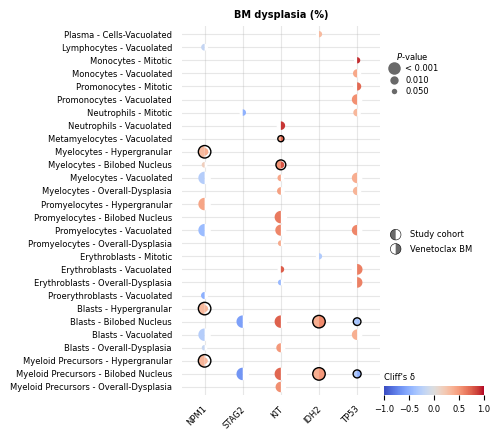

In [ ]:
dysplasia_variables_ordered = sort_features_by_lineage(cell_dysplasia_variables_venex, CELL_LINEAGE_ORDER_BM)

plot_comparison_balloon_plot(
    df1=df_bm,
    df2=df_venex,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_venex},
    cont_vars={variable: get_human_readable_bm_dysplasia_variable(variable, split_into_two_lines=False) for variable in dysplasia_variables_ordered[::-1]},
    label1="Study cohort",
    label2="Venetoclax BM",
    adjust_p_values_1=True,
    adjust_p_values_2=False,
    swap_axes=False,
    plot_height=4.5,
    plot_width=4,
    scale_factor=3,
    title="BM dysplasia (%)",
    legend_below=False,
    cbar_width=0.25,
    cbar_height=0.02,
    marker_mode="split",
    figure_type="supplementary_dysplasia_validation_venex_bm",
)

#### **Finland - Morphometry**

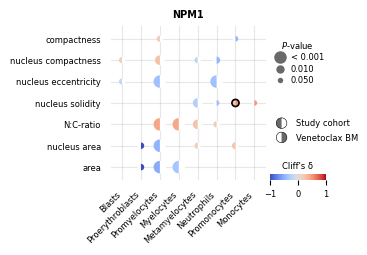

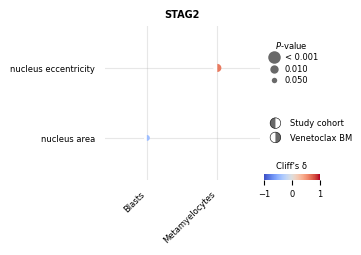

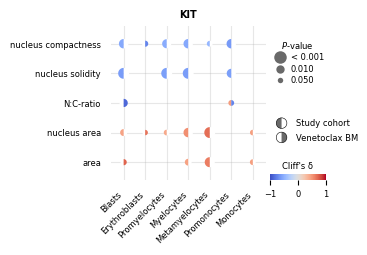

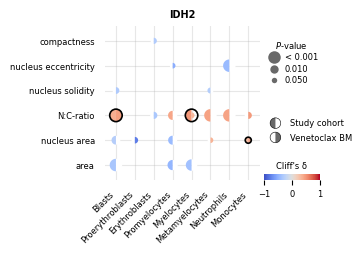

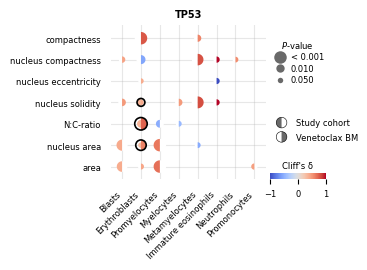

In [ ]:
cell_statistic_variables_ordered = sort_features_by_lineage(cell_statistic_variables_venex, CELL_LINEAGE_ORDER_BM)
cont_vars_morphometry = {v: get_human_readable_cell_statistic_variable(v) for v in cell_statistic_variables_ordered}

cell_statistic_stats_venex = calculate_foldchange_pvalue(
    df=df_venex,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_venex},
    cont_vars=cont_vars_morphometry,
    max_pvalue=0.05,
    adjust_p_values=False,
    effect_size='cliffs_delta',
)

cell_statistic_stats_bm_venex = calculate_foldchange_pvalue(
    df=df_bm,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_venex},
    cont_vars=cont_vars_morphometry,
    max_pvalue=0.05,
    adjust_p_values=True,
    effect_size='cliffs_delta',
)

for variable in label_columns_venex:
    plot_comparison_mutation_morphometry_balloon(
        stats1=cell_statistic_stats_bm_venex,
        stats2=cell_statistic_stats_venex,
        variable=variable,
        label1="Study cohort",
        label2="Venetoclax BM",
        modality="BM",
        plot_width=2,
        plot_height=2,
        title=get_readable_variable_name(variable),
        effect_size='cliffs_delta',
        figure_type=f"supplementary_morphometry_validation_venex_bm_{variable}",
    )

## **Sweden Validation**

In [ ]:
LABEL_DATA_PATH_SWEDEN = "/home/mikkop/projects/aml-mil/data/aml_dg_de-novo-and-secondary-07-04-2026/sweden_bm_samples_07-04-2026.xlsx"
FEATURE_DATA_PATH_SWEDEN = "data/aggregated_features_sweden_bm_07-04-2026.csv"
SWEDEN_VARIABLES = [
    "NPM1",
    "STAG2",
    "KIT",
    "IDH2",
    "TP53",
]


def load_and_process_sweden_bm_data():
    labels = pd.read_excel(LABEL_DATA_PATH_SWEDEN)
    print(f"Total Sweden BM samples in label data: {len(labels)}")
    label_map = json.load(open(LABEL_MAP_PATH_BM, "r"))
    labels = get_target_labels(labels, label_map, include_variables=SWEDEN_VARIABLES)
    label_column_names = [c for c in labels.columns if c not in ["subject_id", "album_id", "database_id"]]
    features = pd.read_csv(FEATURE_DATA_PATH_SWEDEN)
    features, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables = pre_process_bone_marrow_data(features)
    df = pd.merge(labels, features, on=["album_id", "database_id"], how="inner")
    print(f"Total Sweden BM samples with valid feature data: {len(df)}")
    return df, cell_diff_variables, cell_dysplasia_variables, cell_statistic_variables, label_column_names


df_sweden, cell_diff_variables_sweden, cell_dysplasia_variables_sweden, cell_statistic_variables_sweden, label_columns_sweden = load_and_process_sweden_bm_data()


Total Sweden BM samples in label data: 87
Total Sweden BM samples with valid feature data: 87


#### **Sweden - Cell differentials**

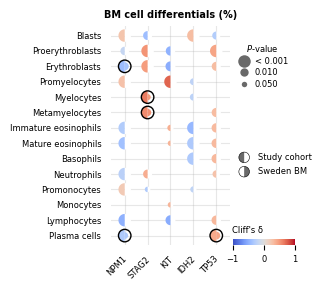

In [ ]:
plot_comparison_balloon_plot(
    df1=df_bm,
    df2=df_sweden,
    cat_vars={v: get_readable_variable_name(v) for v in label_columns_sweden},
    cont_vars={v: get_readable_variable_name(v) for v in sort_features_by_lineage(get_bm_cell_differential_variables(), CELL_LINEAGE_ORDER_BM)},
    label1="Study cohort",
    label2="Sweden BM",
    adjust_p_values_1=True,
    adjust_p_values_2=False,
    swap_axes=False,
    plot_height=3,
    plot_width=2.5,
    scale_factor=3,
    title="BM cell differentials (%)",
    legend_below=False,
    cbar_width=0.25,
    cbar_height=0.02,
    marker_mode="split",
    figure_type="supplementary_cell_differential_validation_sweden_bm",
)

#### **Sweden - Dysplasia**

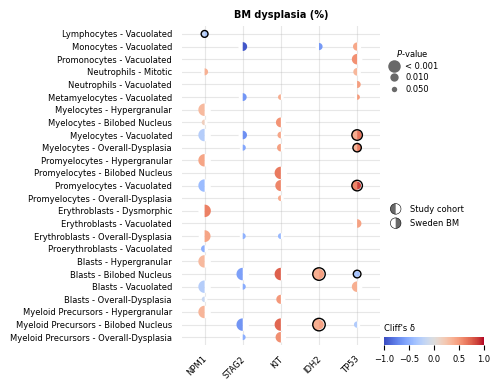

In [ ]:
dysplasia_variables_ordered = sort_features_by_lineage(cell_dysplasia_variables_sweden, CELL_LINEAGE_ORDER_BM)

plot_comparison_balloon_plot(
    df1=df_bm,
    df2=df_sweden,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_sweden},
    cont_vars={variable: get_human_readable_bm_dysplasia_variable(variable, split_into_two_lines=False) for variable in dysplasia_variables_ordered[::-1]},
    label1="Study cohort",
    label2="Sweden BM",
    adjust_p_values_1=True,
    adjust_p_values_2=False,
    swap_axes=False,
    plot_height=4,
    plot_width=4,
    scale_factor=3,
    title="BM dysplasia (%)",
    legend_below=False,
    cbar_width=0.25,
    cbar_height=0.02,
    marker_mode="split",
    figure_type="supplementary_dysplasia_validation_sweden_bm",
)

#### **Sweden - Morphometry**

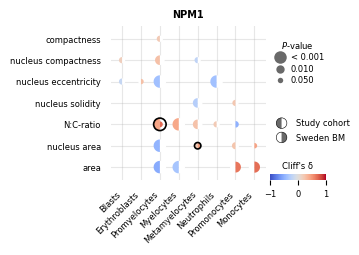

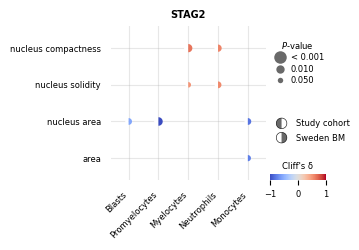

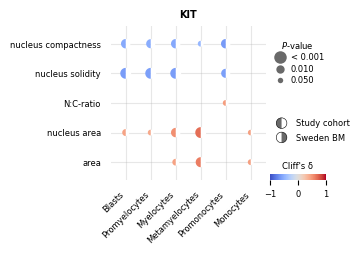

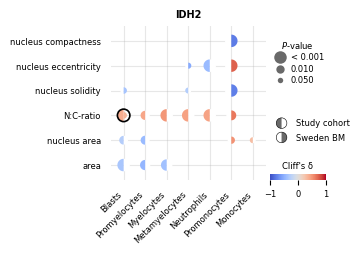

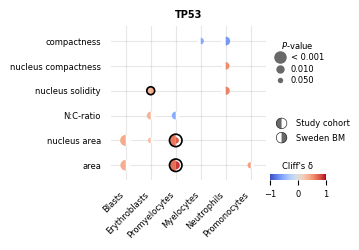

In [ ]:
cell_statistic_variables_ordered = sort_features_by_lineage(cell_statistic_variables_sweden, CELL_LINEAGE_ORDER_BM)
cont_vars_morphometry = {v: get_human_readable_cell_statistic_variable(v) for v in cell_statistic_variables_ordered}

cell_statistic_stats_sweden = calculate_foldchange_pvalue(
    df=df_sweden,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_sweden},
    cont_vars=cont_vars_morphometry,
    max_pvalue=0.05,
    adjust_p_values=False,
    effect_size='cliffs_delta',
)

cell_statistic_stats_bm_sweden = calculate_foldchange_pvalue(
    df=df_bm,
    cat_vars={variable: get_readable_variable_name(variable) for variable in label_columns_sweden},
    cont_vars=cont_vars_morphometry,
    max_pvalue=0.05,
    adjust_p_values=True,
    effect_size='cliffs_delta',
)

for variable in label_columns_sweden:
    plot_comparison_mutation_morphometry_balloon(
        stats1=cell_statistic_stats_bm_sweden,
        stats2=cell_statistic_stats_sweden,
        variable=variable,
        label1="Study cohort",
        label2="Sweden BM",
        modality="BM",
        plot_width=2,
        plot_height=2,
        title=get_readable_variable_name(variable),
        effect_size='cliffs_delta',
        figure_type=f"supplementary_morphometry_validation_sweden_bm_{variable}",
    )